In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, FuncFormatter
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from scipy.stats import norm
import os

from model import *
from data import generate_gmm_data, generate_random_data
from train_utils import train, train_epoch

from plot import *
from utils import *


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

cuda:0


In [3]:
relu = lambda X: np.maximum(X, 0)
d_relu = lambda X: np.maximum(np.sign(X), 0)

elu = lambda X, alpha=1.0: ( alpha * (np.exp(X) - 1) ) * (X <= 0) + (X * (X > 0))
d_elu = lambda X, alpha=1.0: ( alpha * np.exp(X) ) * (X <= 0) + (X > 0)

gelu = lambda X: X * norm.cdf(X)
d_gelu = lambda X: norm.cdf(X) + X * norm.pdf(X)

sigmoid = lambda X: 1 / (1 + np.exp(-X))
d_sigmoid = lambda X: sigmoid(X) * (1 - sigmoid(X))

silu = lambda X: X * sigmoid(X)
d_silu = lambda X: sigmoid(X) + X * d_sigmoid(X)

leaky_relu = lambda X, slope=0.01: slope * np.minimum(X, 0) + np.maximum(X, 0)
d_leaky_relu = lambda X, slope=0.01: slope * (X <= 0) + (X > 0).astype(float)

identity = lambda X: X
d_identity = lambda X: np.ones(X.shape)

abs_ = lambda X: np.abs(X)
d_abs_ = lambda X: -1 * (X <= 0) + (X > 0)

softplus = lambda X: np.log(1 + np.exp(X))
d_softplus = lambda X: sigmoid(X)

leaky_softplus = lambda X, slope=0.01: slope * X + (1 - slope) * (softplus(X) - np.log(2))
d_leaky_softplus = lambda X, slope=0.01: slope + (1 - slope) * (d_softplus(X))


smooth_abs = lambda X, beta = 10: (2 / beta) * softplus(X) - X - ( (2 / beta) * np.log(2) )
d_smooth_abs = lambda X, beta = 10: (2 / beta) * d_softplus(X) - 1

custom_activations_map = {'ReLU': [relu, d_relu],
               'Leaky-Softplus': [leaky_softplus, d_leaky_softplus], 
               'ELU': [elu, d_elu],
               'GELU': [gelu, d_gelu],
               'SiLU': [silu, d_silu],
               'Leaky-ReLU': [leaky_relu, d_leaky_relu],
               'Abs': [abs_, d_abs_],
               'SmoothAbs': [smooth_abs, d_smooth_abs],
               'Identity': [identity, d_identity]}

In [4]:
reduction = 'sum'
loss_map = {
    'ce_loss': nn.CrossEntropyLoss(reduction=reduction),
    'mse_loss': nn.MSELoss(reduction=reduction)
}

optimizer_map = {'SGD': optim.SGD,
                'Adam': optim.Adam, 
                'Muon': optim.Muon}

# Model Training

In [5]:
def get_data(d: int, 
             K: int, 
             N_k: int, 
             nu: float = 1.0,
             normalize_: bool = False, 
             orthogonalize_: bool = False, 
             batch_size: int = None):
    
    
    N = K * N_k
    
    # d > N --> random Gaussian data
    if d > N:
        train_set, train_loader, grad_loader = generate_random_data(d, 
                                                       K, 
                                                       N_k, 
                                                       orthogonalize_ = orthogonalize_, 
                                                       normalize_ = normalize_, 
                                                       batch_size = batch_size)
        val_loader = train_loader 
    
    # N > d --> Gaussian mixture data
    elif N > d:
        train_set, train_loader, grad_loader = generate_gmm_data(d, 
                                                    K, 
                                                    N_k, 
                                                    whiten_ = whiten_, 
                                                    normalize_ = normalize_, 
                                                    batch_size = batch_size)
        val_loader = train_loader
    
    
    X = train_set.samples.T
    Y = train_set.targets.T
    
    return train_loader, val_loader, grad_loader, X, Y

In [6]:
def get_init_grads(model, dataloader, optimizer, criterion):
    
    results = train_epoch(model, 
                        dataloader, 
                        optimizer, 
                        criterion, 
                        device,
                        update=False, 
                        return_grads=True)
    
    return results['epoch_grads'] 
    

In [7]:
def train_model(num_layers: int,
                data_dim: int, 
                hidden_dim: int, 
                num_classes: int, 
                act_fn_str: str, 
                train_loader, 
                grad_loader, 
                val_loader, 
                epochs, 
                lr, 
                freq,
                loss_fn, 
                optimizer_type='SGD', 
                freeze_last_layer=True, 
                diff_init_last_layer=False,
                residual=False, 
                batchnorm=False, 
                init_method='orthogonal',
                init_scale=1):
    
    
    # Train model
    model = MLP(num_layers, 
                data_dim, 
                hidden_dim, 
                num_classes, 
                act_fn_str, 
                freeze_last_layer=freeze_last_layer,
                diff_init_last_layer=diff_init_last_layer,
                residual=residual, 
                batchnorm=batchnorm, 
                init_method=init_method, 
                init_scale=init_scale)

    model = model.to(device)

    # Training
    criterion = loss_map[loss_fn]
    optimizer = optimizer_map[optimizer_type](model.parameters(), momentum=0.9, lr=lr, weight_decay=0)
    #optimizer = optimizer_map[optimizer_type](model.parameters(), lr=lr, weight_decay=0)
    scheduler = None
    
    init_grads = get_init_grads(model, grad_loader, optimizer, criterion)
    results = train(model, 
                    criterion, 
                    optimizer, 
                    train_loader, 
                    val_loader, 
                    epochs, 
                    device,
                    scheduler=scheduler, 
                    return_weights=True,
                    return_grads=False,
                    return_outs=False)


    all_weights = results['all_weights']
    #grads = results['all_grads']
    #outs = results['all_outs']
    train_losses = results['train_losses']
    
    return init_grads, all_weights, train_losses

# Weight decompositions during training

In [8]:
def fro_inner_product(X: np.ndarray, Y: np.ndarray):
    assert X.shape == Y.shape
    
    X_norm = np.linalg.norm(X, ord='fro')
    Y_norm = np.linalg.norm(Y, ord='fro')
    
    return np.trace(X.T @ Y) / (X_norm * Y_norm)

def normalized_dist(X: np.ndarray, Y: np.ndarray):
    assert X.shape == Y.shape
    
    num_elts = np.prod(X.shape)
    
    return np.sqrt( np.linalg.norm(X - Y)**2 / num_elts )

def normalized_norms(X: np.ndarray):
    return normalized_dist(X, np.zeros(X.shape))
    

In [9]:
'''
Helper function to calculate the norm of each component in the weight matrix 
'''
def weight_decomp_norms_dists(all_weights, init_grads, K, init_scale):
    
    L = len(all_weights[0])
    epochs = len(all_weights) - 1
    
    # Get "small update subspace"
    W1_0 = all_weights[0][0]
    G1_0 = init_grads[0]
    
    U_null, V_null = small_update_subspace(W1_0, G1_0, K, init_scale)
    p = U_null.shape[-1]

    # Get "large update subspace"
    U_update = np.linalg.svd(U_null, full_matrices=True)[0][:, p:d]
    V_update = np.linalg.svd(V_null, full_matrices=True)[0][:, p:]
    
    
    # Concatenate two subspaces to create orthogonal matrices
    U = np.concatenate((U_update, U_null), axis=1)
    V = np.concatenate((V_update, V_null), axis=1)

    
    # Get initial weight factors
    W0_tilde = []
    
    U_l, V_l = U.copy(), V.copy()
    for l in range(L - 1):
        # Get weights and resulting decomposition
        W_l_0 = all_weights[0][l]

        decomp = U_l.T @ W_l_0 @ V_l
        W0_tilde.append(decomp)

        # Update U and V factors 
        V_l = U_l 
        U_l = all_weights[0][l + 1] @ V_l / init_scale
    
    
    
    # Calculate weight decomposition norms and distance from initialization
    # for all weights until last-layer classifier 
    norms = np.zeros((epochs, L - 1, 4))
    dists = np.zeros((epochs - 1, L - 1, 4))
    for t in range(1, epochs):
        U_l, V_l = U.copy(), V.copy()
        for l in range(L - 1):
            # Get weights and resulting decomposition
            W_l_t = all_weights[t][l]

            decomp = U_l.T @ W_l_t @ V_l
            

            # Calculate relative squared norm of each component
            norms[t, l, 0] = normalized_norms(decomp[:2*K, :2*K])
            norms[t, l, 1] = normalized_norms(decomp[:2*K, 2*K:])
            norms[t, l, 2] = normalized_norms(decomp[2*K:, :2*K])
            norms[t, l, 3] = normalized_norms(decomp[2*K:, 2*K:])
            
            
            # Calculate relative squared distance of each component
            decomp_0 = W0_tilde[l]
            total_dist = np.linalg.norm(decomp - decomp_0, ord='fro')**2
            
            dists[t - 1, l, 0] = normalized_dist(decomp[:2*K, :2*K], decomp_0[:2*K, :2*K])
            
            dists[t - 1, l, 1] = normalized_dist(decomp[:2*K, 2*K:], decomp_0[:2*K, 2*K:])
            
            dists[t - 1, l, 2] = normalized_dist(decomp[2*K:, :2*K], decomp_0[2*K:, :2*K])
            
            dists[t - 1, l, 3] = normalized_dist(decomp[2*K:, 2*K:], decomp_0[2*K:, 2*K:])
            
            
            # Update U and V factors for next layer 
            V_l = U_l 
            U_l = all_weights[0][l + 1] @ V_l / init_scale
        
        
    return norms, dists

In [10]:
# Data setup
d = 64 # Ambient dim
m = 96
K = 4 # Number of classes
N_k = 250
N = N_k * K
nu = 1

# Model setup
L = 4
act_fn_strs = ['Leaky-Softplus', 'GELU', 'Leaky-ReLU', 'ReLU']
#act, d_act = custom_activations_map[act_fn_str]
residual = False
batchnorm = False
freeze_last_layer = False
diff_init_last_layer = True
init_method = 'orthogonal'
init_scale = 0.1

whiten_ = True
normalize_ = False
orthogonalize_ = False
batch_size = 32

# Training setup
epochs = 250
lrs = [1e-3, 1e-3, 1e-3, 1e-3]
freq = 1

# CHANGE THIS 
# torch.optim.Adam does not have a momentum argument, but Muon does. 
# For Adam, keep the "betas" argument at the default values, which should be (0.9, 0.999).
# Set the Muon "momentum" to 0.9.
# For all optimizers, set the weight decay to 0 (should be the default value in Pytorch anyways.)
optimizer_type = 'SGD' # Change to 'Adam' or 'Muon'. Set momentum to 0.9. 


loss_fn = 'ce_loss'
#loss_fn = 'mse_loss'

savefig_dir = './figs/beyond_theory/' + loss_fn + '/'
savefig_dir += 'full_GD' if (optimizer_type == 'SGD') and (batch_size == N or not batch_size) else optimizer_type + '_batch_size_' + str(batch_size)
if not os.path.exists(savefig_dir):
    os.makedirs(savefig_dir)


===== ACTIVATION FUNCTION:  Leaky-Softplus  =====
=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:28:02,918 - INFO - Finish Epoch 1
2026-01-02 19:28:02,920 - INFO - Train loss: 1386.2962608337402, train accuracy: 22.8
2026-01-02 19:28:02,943 - INFO - Val loss: 1386.2955055236816, val accuracy: 23.8
2026-01-02 19:28:02,995 - INFO - Finish Epoch 2
2026-01-02 19:28:02,996 - INFO - Train loss: 1386.2951354980469, train accuracy: 23.9
2026-01-02 19:28:03,019 - INFO - Val loss: 1386.2943296432495, val accuracy: 25.2
  1%|          | 2/250 [00:00<00:20, 12.00it/s]2026-01-02 19:28:03,072 - INFO - Finish Epoch 3
2026-01-02 19:28:03,073 - INFO - Train loss: 1386.2939195632935, train accuracy: 26.1
2026-01-02 19:28:03,096 - INFO - Val loss: 1386.2931442260742, val accuracy: 28.1
2026-01-02 19:28:03,148 - INFO - Finish Epoch 4
2026-01-02 19:28:03,149 - INFO - Train loss: 1386.29274559021, train accuracy: 29.4
2026-01-02 19:28:03,172 - INFO - Val loss: 1386.2919788360596, val accuracy: 30.3
  2%|▏         | 4/250 [00:00<00:19, 12.60it/s]2026-

 27%|██▋       | 68/250 [00:05<00:14, 12.87it/s]2026-01-02 19:28:08,186 - INFO - Finish Epoch 69
2026-01-02 19:28:08,188 - INFO - Train loss: 1385.8521156311035, train accuracy: 100.0
2026-01-02 19:28:08,211 - INFO - Val loss: 1385.82954788208, val accuracy: 100.0
2026-01-02 19:28:08,264 - INFO - Finish Epoch 70
2026-01-02 19:28:08,265 - INFO - Train loss: 1385.8117923736572, train accuracy: 100.0
2026-01-02 19:28:08,289 - INFO - Val loss: 1385.786452293396, val accuracy: 100.0
 28%|██▊       | 70/250 [00:05<00:13, 12.87it/s]2026-01-02 19:28:08,344 - INFO - Finish Epoch 71
2026-01-02 19:28:08,345 - INFO - Train loss: 1385.766321182251, train accuracy: 100.0
2026-01-02 19:28:08,369 - INFO - Val loss: 1385.737769126892, val accuracy: 100.0
2026-01-02 19:28:08,421 - INFO - Finish Epoch 72
2026-01-02 19:28:08,422 - INFO - Train loss: 1385.7148666381836, train accuracy: 100.0
2026-01-02 19:28:08,445 - INFO - Val loss: 1385.6825304031372, val accuracy: 100.0
 29%|██▉       | 72/250 [00:05<00

 54%|█████▍    | 136/250 [00:10<00:08, 12.89it/s]2026-01-02 19:28:13,458 - INFO - Finish Epoch 137
2026-01-02 19:28:13,459 - INFO - Train loss: 2.6581887952052057, train accuracy: 100.0
2026-01-02 19:28:13,483 - INFO - Val loss: 2.580667259171605, val accuracy: 100.0
2026-01-02 19:28:13,535 - INFO - Finish Epoch 138
2026-01-02 19:28:13,536 - INFO - Train loss: 2.5646675336174667, train accuracy: 100.0
2026-01-02 19:28:13,560 - INFO - Val loss: 2.491981104016304, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 12.88it/s]2026-01-02 19:28:13,613 - INFO - Finish Epoch 139
2026-01-02 19:28:13,614 - INFO - Train loss: 2.477084373589605, train accuracy: 100.0
2026-01-02 19:28:13,638 - INFO - Val loss: 2.4087999807670712, val accuracy: 100.0
2026-01-02 19:28:13,690 - INFO - Finish Epoch 140
2026-01-02 19:28:13,691 - INFO - Train loss: 2.394909514579922, train accuracy: 100.0
2026-01-02 19:28:13,715 - INFO - Val loss: 2.3306409274227917, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:28:16,053 - INFO - Val loss: 1.146303514484316, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 12.90it/s]2026-01-02 19:28:16,106 - INFO - Finish Epoch 171
2026-01-02 19:28:16,107 - INFO - Train loss: 1.1433719079941511, train accuracy: 100.0
2026-01-02 19:28:16,131 - INFO - Val loss: 1.12628277647309, val accuracy: 100.0
2026-01-02 19:28:16,183 - INFO - Finish Epoch 172
2026-01-02 19:28:16,184 - INFO - Train loss: 1.123463015537709, train accuracy: 100.0
2026-01-02 19:28:16,208 - INFO - Val loss: 1.1069009378552437, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:06, 12.90it/s]2026-01-02 19:28:16,260 - INFO - Finish Epoch 173
2026-01-02 19:28:16,261 - INFO - Train loss: 1.1041781064122915, train accuracy: 100.0
2026-01-02 19:28:16,285 - INFO - Val loss: 1.0881242512259632, val accuracy: 100.0
2026-01-02 19:28:16,336 - INFO - Finish Epoch 174
2026-01-02 19:28:16,337 - INFO - Train loss: 1.0854986384510994, train accuracy: 100.0
2026-01-02 19:28:16,361 - 

2026-01-02 19:28:18,651 - INFO - Train loss: 0.7114409042987972, train accuracy: 100.0
2026-01-02 19:28:18,675 - INFO - Val loss: 0.7041322103468701, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 12.99it/s]2026-01-02 19:28:18,727 - INFO - Finish Epoch 205
2026-01-02 19:28:18,728 - INFO - Train loss: 0.7031096611171961, train accuracy: 100.0
2026-01-02 19:28:18,752 - INFO - Val loss: 0.6959525509737432, val accuracy: 100.0
2026-01-02 19:28:18,807 - INFO - Finish Epoch 206
2026-01-02 19:28:18,808 - INFO - Train loss: 0.6949606126872823, train accuracy: 100.0
2026-01-02 19:28:18,832 - INFO - Val loss: 0.6879484506789595, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 12.91it/s]2026-01-02 19:28:18,885 - INFO - Finish Epoch 207
2026-01-02 19:28:18,886 - INFO - Train loss: 0.6869813401717693, train accuracy: 100.0
2026-01-02 19:28:18,909 - INFO - Val loss: 0.6801145650679246, val accuracy: 100.0
2026-01-02 19:28:18,961 - INFO - Finish Epoch 208
2026-01-02 19:28:18,96

2026-01-02 19:28:21,286 - INFO - Finish Epoch 238
2026-01-02 19:28:21,287 - INFO - Train loss: 0.5032163808355108, train accuracy: 100.0
2026-01-02 19:28:21,310 - INFO - Val loss: 0.49928622564766556, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 12.82it/s]2026-01-02 19:28:21,363 - INFO - Finish Epoch 239
2026-01-02 19:28:21,365 - INFO - Train loss: 0.4988109322730452, train accuracy: 100.0
2026-01-02 19:28:21,388 - INFO - Val loss: 0.4949428441468626, val accuracy: 100.0
2026-01-02 19:28:21,440 - INFO - Finish Epoch 240
2026-01-02 19:28:21,441 - INFO - Train loss: 0.494474591454491, train accuracy: 100.0
2026-01-02 19:28:21,465 - INFO - Val loss: 0.4906653694342822, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 12.86it/s]2026-01-02 19:28:21,518 - INFO - Finish Epoch 241
2026-01-02 19:28:21,519 - INFO - Train loss: 0.49020964023657143, train accuracy: 100.0
2026-01-02 19:28:21,542 - INFO - Val loss: 0.4864588174968958, val accuracy: 100.0
2026-01-02 19:28:21,5

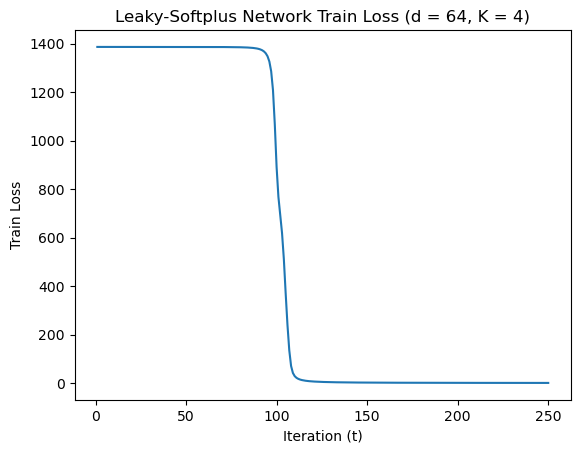

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:28:22,562 - INFO - Finish Epoch 1
2026-01-02 19:28:22,563 - INFO - Train loss: 1386.291275024414, train accuracy: 31.9
2026-01-02 19:28:22,587 - INFO - Val loss: 1386.2904949188232, val accuracy: 33.9
2026-01-02 19:28:22,638 - INFO - Finish Epoch 2
2026-01-02 19:28:22,639 - INFO - Train loss: 1386.2901220321655, train accuracy: 34.4
2026-01-02 19:28:22,663 - INFO - Val loss: 1386.289312362671, val accuracy: 35.8
  1%|          | 2/250 [00:00<00:18, 13.23it/s]2026-01-02 19:28:22,715 - INFO - Finish Epoch 3
2026-01-02 19:28:22,716 - INFO - Train loss: 1386.2889165878296, train accuracy: 36.4
2026-01-02 19:28:22,740 - INFO - Val loss: 1386.2881002426147, val accuracy: 38.8
2026-01-02 19:28:22,791 - INFO - Finish Epoch 4
2026-01-02 19:28:22,793 - INFO - Train loss: 1386.287745475769, train accuracy: 39.2
2026-01-02 19:28:22,816 - INFO - Val loss: 1386.2869091033936, val accuracy: 40.6
  2%|▏         | 4/250 [00:00<00:18, 13.11it/s]2026-0

 27%|██▋       | 68/250 [00:05<00:14, 12.89it/s]2026-01-02 19:28:27,882 - INFO - Finish Epoch 69
2026-01-02 19:28:27,883 - INFO - Train loss: 1385.7073020935059, train accuracy: 99.7
2026-01-02 19:28:27,906 - INFO - Val loss: 1385.6668701171875, val accuracy: 99.7
2026-01-02 19:28:27,958 - INFO - Finish Epoch 70
2026-01-02 19:28:27,959 - INFO - Train loss: 1385.6486368179321, train accuracy: 99.6
2026-01-02 19:28:27,983 - INFO - Val loss: 1385.6023635864258, val accuracy: 99.6
 28%|██▊       | 70/250 [00:05<00:13, 12.89it/s]2026-01-02 19:28:28,038 - INFO - Finish Epoch 71
2026-01-02 19:28:28,039 - INFO - Train loss: 1385.5816249847412, train accuracy: 99.6
2026-01-02 19:28:28,063 - INFO - Val loss: 1385.528470993042, val accuracy: 99.6
2026-01-02 19:28:28,115 - INFO - Finish Epoch 72
2026-01-02 19:28:28,116 - INFO - Train loss: 1385.5047397613525, train accuracy: 99.6
2026-01-02 19:28:28,139 - INFO - Val loss: 1385.4433059692383, val accuracy: 99.6
 29%|██▉       | 72/250 [00:05<00:13,

 54%|█████▍    | 136/250 [00:10<00:08, 12.85it/s]2026-01-02 19:28:33,285 - INFO - Finish Epoch 137
2026-01-02 19:28:33,287 - INFO - Train loss: 3.6314195096492767, train accuracy: 100.0
2026-01-02 19:28:33,310 - INFO - Val loss: 3.4827332571148872, val accuracy: 100.0
2026-01-02 19:28:33,362 - INFO - Finish Epoch 138
2026-01-02 19:28:33,363 - INFO - Train loss: 3.475646298378706, train accuracy: 100.0
2026-01-02 19:28:33,387 - INFO - Val loss: 3.337776519358158, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 12.88it/s]2026-01-02 19:28:33,441 - INFO - Finish Epoch 139
2026-01-02 19:28:33,442 - INFO - Train loss: 3.331700250506401, train accuracy: 100.0
2026-01-02 19:28:33,467 - INFO - Val loss: 3.203527010977268, val accuracy: 100.0
2026-01-02 19:28:33,520 - INFO - Finish Epoch 140
2026-01-02 19:28:33,522 - INFO - Train loss: 3.198313094675541, train accuracy: 100.0
2026-01-02 19:28:33,546 - INFO - Val loss: 3.0788670796900988, val accuracy: 100.0
 56%|█████▌    | 140/250 [0

2026-01-02 19:28:35,872 - INFO - Val loss: 1.3592788837850094, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 12.91it/s]2026-01-02 19:28:35,925 - INFO - Finish Epoch 171
2026-01-02 19:28:35,926 - INFO - Train loss: 1.3598819999024272, train accuracy: 100.0
2026-01-02 19:28:35,950 - INFO - Val loss: 1.3328665876761079, val accuracy: 100.0
2026-01-02 19:28:36,001 - INFO - Finish Epoch 172
2026-01-02 19:28:36,003 - INFO - Train loss: 1.3334799846634269, train accuracy: 100.0
2026-01-02 19:28:36,026 - INFO - Val loss: 1.3073739344254136, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:06, 12.93it/s]2026-01-02 19:28:36,079 - INFO - Finish Epoch 173
2026-01-02 19:28:36,080 - INFO - Train loss: 1.307999772951007, train accuracy: 100.0
2026-01-02 19:28:36,104 - INFO - Val loss: 1.2827605325728655, val accuracy: 100.0
2026-01-02 19:28:36,156 - INFO - Finish Epoch 174
2026-01-02 19:28:36,157 - INFO - Train loss: 1.283396665006876, train accuracy: 100.0
2026-01-02 19:28:36,182 

2026-01-02 19:28:38,483 - INFO - Train loss: 0.8072091434150934, train accuracy: 100.0
2026-01-02 19:28:38,507 - INFO - Val loss: 0.7964051146991551, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 12.89it/s]2026-01-02 19:28:38,560 - INFO - Finish Epoch 205
2026-01-02 19:28:38,561 - INFO - Train loss: 0.7969703814014792, train accuracy: 100.0
2026-01-02 19:28:38,585 - INFO - Val loss: 0.7864071587100625, val accuracy: 100.0
2026-01-02 19:28:38,636 - INFO - Finish Epoch 206
2026-01-02 19:28:38,637 - INFO - Train loss: 0.7869664770551026, train accuracy: 100.0
2026-01-02 19:28:38,661 - INFO - Val loss: 0.7766349432058632, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:16<00:03, 12.91it/s]2026-01-02 19:28:38,714 - INFO - Finish Epoch 207
2026-01-02 19:28:38,715 - INFO - Train loss: 0.7771862954832613, train accuracy: 100.0
2026-01-02 19:28:38,738 - INFO - Val loss: 0.7670798790641129, val accuracy: 100.0
2026-01-02 19:28:38,790 - INFO - Finish Epoch 208
2026-01-02 19:28:38,79

2026-01-02 19:28:41,114 - INFO - Finish Epoch 238
2026-01-02 19:28:41,115 - INFO - Train loss: 0.5561684458516538, train accuracy: 100.0
2026-01-02 19:28:41,139 - INFO - Val loss: 0.5505787879228592, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 12.95it/s]2026-01-02 19:28:41,192 - INFO - Finish Epoch 239
2026-01-02 19:28:41,193 - INFO - Train loss: 0.5509722572751343, train accuracy: 100.0
2026-01-02 19:28:41,216 - INFO - Val loss: 0.5454721665009856, val accuracy: 100.0
2026-01-02 19:28:41,268 - INFO - Finish Epoch 240
2026-01-02 19:28:41,269 - INFO - Train loss: 0.5458590048365295, train accuracy: 100.0
2026-01-02 19:28:41,293 - INFO - Val loss: 0.5404535261914134, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 12.96it/s]2026-01-02 19:28:41,346 - INFO - Finish Epoch 241
2026-01-02 19:28:41,347 - INFO - Train loss: 0.540838235989213, train accuracy: 100.0
2026-01-02 19:28:41,371 - INFO - Val loss: 0.5355191705748439, val accuracy: 100.0
2026-01-02 19:28:41,423

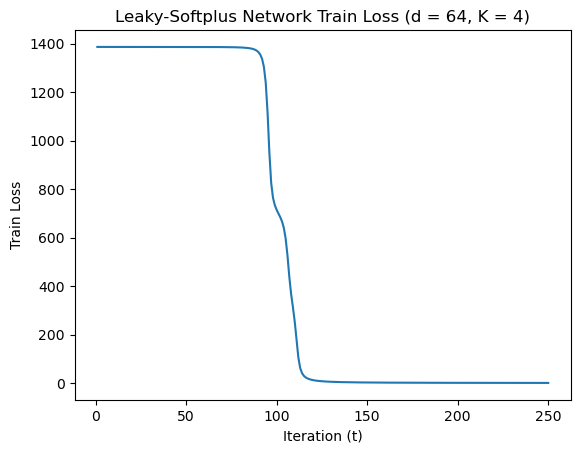

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:28:42,411 - INFO - Finish Epoch 1
2026-01-02 19:28:42,413 - INFO - Train loss: 1386.292636871338, train accuracy: 25.8
2026-01-02 19:28:42,439 - INFO - Val loss: 1386.2919101715088, val accuracy: 27.7
2026-01-02 19:28:42,489 - INFO - Finish Epoch 2
2026-01-02 19:28:42,490 - INFO - Train loss: 1386.2915210723877, train accuracy: 28.6
2026-01-02 19:28:42,514 - INFO - Val loss: 1386.2907123565674, val accuracy: 30.4
  1%|          | 2/250 [00:00<00:19, 13.04it/s]2026-01-02 19:28:42,566 - INFO - Finish Epoch 3
2026-01-02 19:28:42,567 - INFO - Train loss: 1386.2903184890747, train accuracy: 30.8
2026-01-02 19:28:42,590 - INFO - Val loss: 1386.2895040512085, val accuracy: 32.9
2026-01-02 19:28:42,641 - INFO - Finish Epoch 4
2026-01-02 19:28:42,642 - INFO - Train loss: 1386.2891178131104, train accuracy: 34.0
2026-01-02 19:28:42,665 - INFO - Val loss: 1386.28830909729, val accuracy: 35.7
  2%|▏         | 4/250 [00:00<00:18, 13.14it/s]2026-0

 27%|██▋       | 68/250 [00:05<00:13, 13.05it/s]2026-01-02 19:28:47,631 - INFO - Finish Epoch 69
2026-01-02 19:28:47,633 - INFO - Train loss: 1385.6780242919922, train accuracy: 99.9
2026-01-02 19:28:47,657 - INFO - Val loss: 1385.636734008789, val accuracy: 99.9
2026-01-02 19:28:47,708 - INFO - Finish Epoch 70
2026-01-02 19:28:47,710 - INFO - Train loss: 1385.612769126892, train accuracy: 99.9
2026-01-02 19:28:47,734 - INFO - Val loss: 1385.5652885437012, val accuracy: 99.9
 28%|██▊       | 70/250 [00:05<00:13, 13.01it/s]2026-01-02 19:28:47,786 - INFO - Finish Epoch 71
2026-01-02 19:28:47,787 - INFO - Train loss: 1385.5377035140991, train accuracy: 99.9
2026-01-02 19:28:47,812 - INFO - Val loss: 1385.48281955719, val accuracy: 99.9
2026-01-02 19:28:47,863 - INFO - Finish Epoch 72
2026-01-02 19:28:47,864 - INFO - Train loss: 1385.4508972167969, train accuracy: 99.8
2026-01-02 19:28:47,888 - INFO - Val loss: 1385.3870792388916, val accuracy: 99.8
 29%|██▉       | 72/250 [00:05<00:13, 12

 54%|█████▍    | 136/250 [00:10<00:08, 13.01it/s]2026-01-02 19:28:52,847 - INFO - Finish Epoch 137
2026-01-02 19:28:52,848 - INFO - Train loss: 2.453933898359537, train accuracy: 100.0
2026-01-02 19:28:52,872 - INFO - Val loss: 2.3875991702079773, val accuracy: 100.0
2026-01-02 19:28:52,923 - INFO - Finish Epoch 138
2026-01-02 19:28:52,925 - INFO - Train loss: 2.3752004392445087, train accuracy: 100.0
2026-01-02 19:28:52,948 - INFO - Val loss: 2.312579173594713, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.01it/s]2026-01-02 19:28:53,000 - INFO - Finish Epoch 139
2026-01-02 19:28:53,002 - INFO - Train loss: 2.301022332161665, train accuracy: 100.0
2026-01-02 19:28:53,025 - INFO - Val loss: 2.2418250758200884, val accuracy: 100.0
2026-01-02 19:28:53,077 - INFO - Finish Epoch 140
2026-01-02 19:28:53,078 - INFO - Train loss: 2.2310253735631704, train accuracy: 100.0
2026-01-02 19:28:53,102 - INFO - Val loss: 2.174975711852312, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:28:55,401 - INFO - Val loss: 1.11641251668334, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 13.08it/s]2026-01-02 19:28:55,453 - INFO - Finish Epoch 171
2026-01-02 19:28:55,454 - INFO - Train loss: 1.114128915593028, train accuracy: 100.0
2026-01-02 19:28:55,478 - INFO - Val loss: 1.0977261774241924, val accuracy: 100.0
2026-01-02 19:28:55,529 - INFO - Finish Epoch 172
2026-01-02 19:28:55,530 - INFO - Train loss: 1.0955287022516131, train accuracy: 100.0
2026-01-02 19:28:55,554 - INFO - Val loss: 1.0796077400445938, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:05, 13.09it/s]2026-01-02 19:28:55,606 - INFO - Finish Epoch 173
2026-01-02 19:28:55,607 - INFO - Train loss: 1.0774915479123592, train accuracy: 100.0
2026-01-02 19:28:55,630 - INFO - Val loss: 1.0620332658290863, val accuracy: 100.0
2026-01-02 19:28:55,681 - INFO - Finish Epoch 174
2026-01-02 19:28:55,682 - INFO - Train loss: 1.059997383505106, train accuracy: 100.0
2026-01-02 19:28:55,706 - 

2026-01-02 19:28:57,982 - INFO - Train loss: 0.7042540963739157, train accuracy: 100.0
2026-01-02 19:28:58,006 - INFO - Val loss: 0.6969853141345084, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 13.06it/s]2026-01-02 19:28:58,058 - INFO - Finish Epoch 205
2026-01-02 19:28:58,059 - INFO - Train loss: 0.6962153110653162, train accuracy: 100.0
2026-01-02 19:28:58,083 - INFO - Val loss: 0.6890955748967826, val accuracy: 100.0
2026-01-02 19:28:58,134 - INFO - Finish Epoch 206
2026-01-02 19:28:58,135 - INFO - Train loss: 0.6883424804545939, train accuracy: 100.0
2026-01-02 19:28:58,158 - INFO - Val loss: 0.6813653744757175, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 13.07it/s]2026-01-02 19:28:58,211 - INFO - Finish Epoch 207
2026-01-02 19:28:58,212 - INFO - Train loss: 0.6806370997801423, train accuracy: 100.0
2026-01-02 19:28:58,236 - INFO - Val loss: 0.6737907407805324, val accuracy: 100.0
2026-01-02 19:28:58,287 - INFO - Finish Epoch 208
2026-01-02 19:28:58,28

2026-01-02 19:29:00,580 - INFO - Finish Epoch 238
2026-01-02 19:29:00,581 - INFO - Train loss: 0.5016953707672656, train accuracy: 100.0
2026-01-02 19:29:00,605 - INFO - Val loss: 0.4977162703871727, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.05it/s]2026-01-02 19:29:00,658 - INFO - Finish Epoch 239
2026-01-02 19:29:00,659 - INFO - Train loss: 0.4973714519292116, train accuracy: 100.0
2026-01-02 19:29:00,683 - INFO - Val loss: 0.4934586235322058, val accuracy: 100.0
2026-01-02 19:29:00,734 - INFO - Finish Epoch 240
2026-01-02 19:29:00,735 - INFO - Train loss: 0.49311773758381605, train accuracy: 100.0
2026-01-02 19:29:00,760 - INFO - Val loss: 0.48926664609462023, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.01it/s]2026-01-02 19:29:00,812 - INFO - Finish Epoch 241
2026-01-02 19:29:00,813 - INFO - Train loss: 0.48893424263224006, train accuracy: 100.0
2026-01-02 19:29:00,837 - INFO - Val loss: 0.48513701651245356, val accuracy: 100.0
2026-01-02 19:29:0

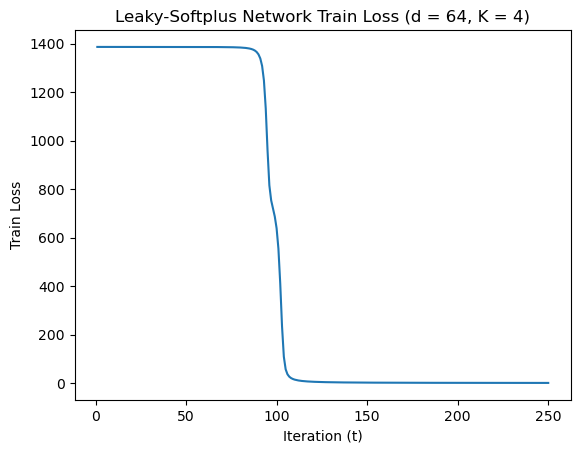

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:29:01,872 - INFO - Finish Epoch 1
2026-01-02 19:29:01,873 - INFO - Train loss: 1386.2956848144531, train accuracy: 23.1
2026-01-02 19:29:01,898 - INFO - Val loss: 1386.295036315918, val accuracy: 24.1
2026-01-02 19:29:01,949 - INFO - Finish Epoch 2
2026-01-02 19:29:01,950 - INFO - Train loss: 1386.2946815490723, train accuracy: 24.8
2026-01-02 19:29:01,973 - INFO - Val loss: 1386.2940101623535, val accuracy: 25.8
  1%|          | 2/250 [00:00<00:18, 13.14it/s]2026-01-02 19:29:02,025 - INFO - Finish Epoch 3
2026-01-02 19:29:02,026 - INFO - Train loss: 1386.2936744689941, train accuracy: 26.9
2026-01-02 19:29:02,050 - INFO - Val loss: 1386.2929935455322, val accuracy: 28.0
2026-01-02 19:29:02,101 - INFO - Finish Epoch 4
2026-01-02 19:29:02,102 - INFO - Train loss: 1386.2926778793335, train accuracy: 29.0
2026-01-02 19:29:02,126 - INFO - Val loss: 1386.2919902801514, val accuracy: 30.4
  2%|▏         | 4/250 [00:00<00:18, 13.13it/s]2026

 27%|██▋       | 68/250 [00:05<00:13, 13.04it/s]2026-01-02 19:29:07,089 - INFO - Finish Epoch 69
2026-01-02 19:29:07,090 - INFO - Train loss: 1386.0164289474487, train accuracy: 100.0
2026-01-02 19:29:07,113 - INFO - Val loss: 1386.0039415359497, val accuracy: 100.0
2026-01-02 19:29:07,164 - INFO - Finish Epoch 70
2026-01-02 19:29:07,165 - INFO - Train loss: 1385.9963054656982, train accuracy: 100.0
2026-01-02 19:29:07,189 - INFO - Val loss: 1385.9826107025146, val accuracy: 100.0
 28%|██▊       | 70/250 [00:05<00:13, 13.07it/s]2026-01-02 19:29:07,241 - INFO - Finish Epoch 71
2026-01-02 19:29:07,242 - INFO - Train loss: 1385.9742012023926, train accuracy: 100.0
2026-01-02 19:29:07,266 - INFO - Val loss: 1385.9591283798218, val accuracy: 100.0
2026-01-02 19:29:07,317 - INFO - Finish Epoch 72
2026-01-02 19:29:07,318 - INFO - Train loss: 1385.949857711792, train accuracy: 100.0
2026-01-02 19:29:07,342 - INFO - Val loss: 1385.9332265853882, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:07<00:11, 13.08it/s]2026-01-02 19:29:09,690 - INFO - Finish Epoch 103
2026-01-02 19:29:09,691 - INFO - Train loss: 1345.6287698745728, train accuracy: 81.3
2026-01-02 19:29:09,714 - INFO - Val loss: 1334.3767757415771, val accuracy: 80.2
2026-01-02 19:29:09,765 - INFO - Finish Epoch 104
2026-01-02 19:29:09,766 - INFO - Train loss: 1323.801796913147, train accuracy: 73.4
2026-01-02 19:29:09,790 - INFO - Val loss: 1303.8349208831787, val accuracy: 72.2
 42%|████▏     | 104/250 [00:07<00:11, 13.09it/s]2026-01-02 19:29:09,842 - INFO - Finish Epoch 105
2026-01-02 19:29:09,843 - INFO - Train loss: 1284.2197189331055, train accuracy: 65.1
2026-01-02 19:29:09,867 - INFO - Val loss: 1246.6791143417358, val accuracy: 63.1
2026-01-02 19:29:09,917 - INFO - Finish Epoch 106
2026-01-02 19:29:09,918 - INFO - Train loss: 1209.5181436538696, train accuracy: 59.3
2026-01-02 19:29:09,942 - INFO - Val loss: 1138.3108253479004, val accuracy: 57.5
 42%|████▏     | 106/250 [00:08

 54%|█████▍    | 136/250 [00:10<00:08, 13.06it/s]2026-01-02 19:29:12,291 - INFO - Finish Epoch 137
2026-01-02 19:29:12,292 - INFO - Train loss: 4.165480572730303, train accuracy: 100.0
2026-01-02 19:29:12,316 - INFO - Val loss: 3.9987235851585865, val accuracy: 100.0
2026-01-02 19:29:12,367 - INFO - Finish Epoch 138
2026-01-02 19:29:12,368 - INFO - Train loss: 3.97956832498312, train accuracy: 100.0
2026-01-02 19:29:12,391 - INFO - Val loss: 3.8253953382372856, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.07it/s]2026-01-02 19:29:12,446 - INFO - Finish Epoch 139
2026-01-02 19:29:12,447 - INFO - Train loss: 3.8084613792598248, train accuracy: 100.0
2026-01-02 19:29:12,471 - INFO - Val loss: 3.66550675034523, val accuracy: 100.0
2026-01-02 19:29:12,522 - INFO - Finish Epoch 140
2026-01-02 19:29:12,523 - INFO - Train loss: 3.6504958756268024, train accuracy: 100.0
2026-01-02 19:29:12,547 - INFO - Val loss: 3.5175768956542015, val accuracy: 100.0
 56%|█████▌    | 140/250 [0

2026-01-02 19:29:14,857 - INFO - Val loss: 1.5257609505206347, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 12.94it/s]2026-01-02 19:29:14,910 - INFO - Finish Epoch 171
2026-01-02 19:29:14,911 - INFO - Train loss: 1.5253303349018097, train accuracy: 100.0
2026-01-02 19:29:14,935 - INFO - Val loss: 1.495799720287323, val accuracy: 100.0
2026-01-02 19:29:14,986 - INFO - Finish Epoch 172
2026-01-02 19:29:14,987 - INFO - Train loss: 1.4954320415854454, train accuracy: 100.0
2026-01-02 19:29:15,011 - INFO - Val loss: 1.466900423169136, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:06, 12.96it/s]2026-01-02 19:29:15,063 - INFO - Finish Epoch 173
2026-01-02 19:29:15,064 - INFO - Train loss: 1.4665971770882607, train accuracy: 100.0
2026-01-02 19:29:15,088 - INFO - Val loss: 1.4390119686722755, val accuracy: 100.0
2026-01-02 19:29:15,139 - INFO - Finish Epoch 174
2026-01-02 19:29:15,140 - INFO - Train loss: 1.4387664049863815, train accuracy: 100.0
2026-01-02 19:29:15,164 

2026-01-02 19:29:17,463 - INFO - Train loss: 0.9024463091045618, train accuracy: 100.0
2026-01-02 19:29:17,487 - INFO - Val loss: 0.8905817056074739, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 12.98it/s]2026-01-02 19:29:17,540 - INFO - Finish Epoch 205
2026-01-02 19:29:17,541 - INFO - Train loss: 0.8909579096361995, train accuracy: 100.0
2026-01-02 19:29:17,565 - INFO - Val loss: 0.879355319775641, val accuracy: 100.0
2026-01-02 19:29:17,616 - INFO - Finish Epoch 206
2026-01-02 19:29:17,618 - INFO - Train loss: 0.8797324579209089, train accuracy: 100.0
2026-01-02 19:29:17,641 - INFO - Val loss: 0.8683859752491117, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 12.98it/s]2026-01-02 19:29:17,694 - INFO - Finish Epoch 207
2026-01-02 19:29:17,695 - INFO - Train loss: 0.8687627362087369, train accuracy: 100.0
2026-01-02 19:29:17,719 - INFO - Val loss: 0.8576600579544902, val accuracy: 100.0
2026-01-02 19:29:17,770 - INFO - Finish Epoch 208
2026-01-02 19:29:17,771

2026-01-02 19:29:20,099 - INFO - Finish Epoch 238
2026-01-02 19:29:20,100 - INFO - Train loss: 0.6212056535296142, train accuracy: 100.0
2026-01-02 19:29:20,124 - INFO - Val loss: 0.6150315515697002, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 12.92it/s]2026-01-02 19:29:20,176 - INFO - Finish Epoch 239
2026-01-02 19:29:20,177 - INFO - Train loss: 0.6153960740193725, train accuracy: 100.0
2026-01-02 19:29:20,201 - INFO - Val loss: 0.6093179415911436, val accuracy: 100.0
2026-01-02 19:29:20,253 - INFO - Finish Epoch 240
2026-01-02 19:29:20,254 - INFO - Train loss: 0.6096743536181748, train accuracy: 100.0
2026-01-02 19:29:20,278 - INFO - Val loss: 0.6037006066180766, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 12.93it/s]2026-01-02 19:29:20,330 - INFO - Finish Epoch 241
2026-01-02 19:29:20,331 - INFO - Train loss: 0.6040559224784374, train accuracy: 100.0
2026-01-02 19:29:20,355 - INFO - Val loss: 0.5981805948540568, val accuracy: 100.0
2026-01-02 19:29:20,40

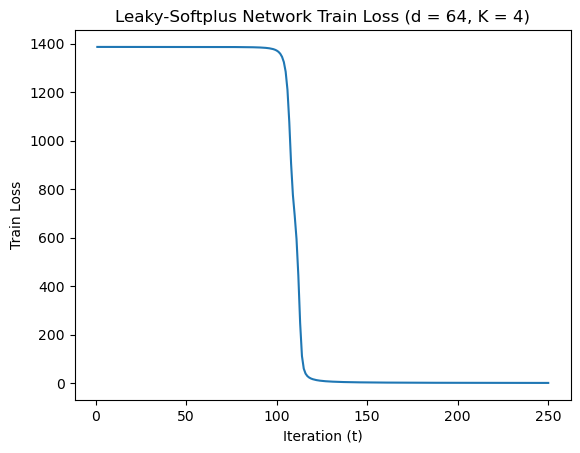

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:29:21,402 - INFO - Finish Epoch 1
2026-01-02 19:29:21,403 - INFO - Train loss: 1386.2923774719238, train accuracy: 29.5
2026-01-02 19:29:21,427 - INFO - Val loss: 1386.291660308838, val accuracy: 30.3
2026-01-02 19:29:21,477 - INFO - Finish Epoch 2
2026-01-02 19:29:21,478 - INFO - Train loss: 1386.291319847107, train accuracy: 30.8
2026-01-02 19:29:21,502 - INFO - Val loss: 1386.2905673980713, val accuracy: 32.2
  1%|          | 2/250 [00:00<00:18, 13.23it/s]2026-01-02 19:29:21,554 - INFO - Finish Epoch 3
2026-01-02 19:29:21,555 - INFO - Train loss: 1386.2902088165283, train accuracy: 33.2
2026-01-02 19:29:21,579 - INFO - Val loss: 1386.2894763946533, val accuracy: 34.6
2026-01-02 19:29:21,630 - INFO - Finish Epoch 4
2026-01-02 19:29:21,631 - INFO - Train loss: 1386.2891254425049, train accuracy: 35.6
2026-01-02 19:29:21,655 - INFO - Val loss: 1386.288372039795, val accuracy: 36.5
  2%|▏         | 4/250 [00:00<00:18, 13.18it/s]2026-0

 27%|██▋       | 68/250 [00:05<00:14, 13.00it/s]2026-01-02 19:29:26,626 - INFO - Finish Epoch 69
2026-01-02 19:29:26,627 - INFO - Train loss: 1385.8841524124146, train accuracy: 99.8
2026-01-02 19:29:26,651 - INFO - Val loss: 1385.8634204864502, val accuracy: 99.9
2026-01-02 19:29:26,702 - INFO - Finish Epoch 70
2026-01-02 19:29:26,703 - INFO - Train loss: 1385.8496265411377, train accuracy: 99.8
2026-01-02 19:29:26,727 - INFO - Val loss: 1385.8265237808228, val accuracy: 99.9
 28%|██▊       | 70/250 [00:05<00:13, 13.00it/s]2026-01-02 19:29:26,779 - INFO - Finish Epoch 71
2026-01-02 19:29:26,780 - INFO - Train loss: 1385.81107711792, train accuracy: 99.8
2026-01-02 19:29:26,804 - INFO - Val loss: 1385.7852401733398, val accuracy: 99.9
2026-01-02 19:29:26,855 - INFO - Finish Epoch 72
2026-01-02 19:29:26,856 - INFO - Train loss: 1385.7678413391113, train accuracy: 99.8
2026-01-02 19:29:26,880 - INFO - Val loss: 1385.7388610839844, val accuracy: 99.9
 29%|██▉       | 72/250 [00:05<00:13, 

 54%|█████▍    | 136/250 [00:10<00:08, 13.04it/s]2026-01-02 19:29:31,974 - INFO - Finish Epoch 137
2026-01-02 19:29:31,975 - INFO - Train loss: 3.6283854246139526, train accuracy: 100.0
2026-01-02 19:29:31,998 - INFO - Val loss: 3.501578960567713, val accuracy: 100.0
2026-01-02 19:29:32,049 - INFO - Finish Epoch 138
2026-01-02 19:29:32,050 - INFO - Train loss: 3.4695408046245575, train accuracy: 100.0
2026-01-02 19:29:32,074 - INFO - Val loss: 3.3522901758551598, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.08it/s]2026-01-02 19:29:32,126 - INFO - Finish Epoch 139
2026-01-02 19:29:32,127 - INFO - Train loss: 3.322931185364723, train accuracy: 100.0
2026-01-02 19:29:32,152 - INFO - Val loss: 3.2142251916229725, val accuracy: 100.0
2026-01-02 19:29:32,204 - INFO - Finish Epoch 140
2026-01-02 19:29:32,205 - INFO - Train loss: 3.187241617590189, train accuracy: 100.0
2026-01-02 19:29:32,229 - INFO - Val loss: 3.0861935317516327, val accuracy: 100.0
 56%|█████▌    | 140/250 

2026-01-02 19:29:34,522 - INFO - Val loss: 1.3415276035666466, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 13.10it/s]2026-01-02 19:29:34,574 - INFO - Finish Epoch 171
2026-01-02 19:29:34,575 - INFO - Train loss: 1.3369355536997318, train accuracy: 100.0
2026-01-02 19:29:34,599 - INFO - Val loss: 1.315105652436614, val accuracy: 100.0
2026-01-02 19:29:34,649 - INFO - Finish Epoch 172
2026-01-02 19:29:34,650 - INFO - Train loss: 1.3106968067586422, train accuracy: 100.0
2026-01-02 19:29:34,674 - INFO - Val loss: 1.289625532925129, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:05, 13.12it/s]2026-01-02 19:29:34,726 - INFO - Finish Epoch 173
2026-01-02 19:29:34,727 - INFO - Train loss: 1.2853875942528248, train accuracy: 100.0
2026-01-02 19:29:34,751 - INFO - Val loss: 1.2650300730019808, val accuracy: 100.0
2026-01-02 19:29:34,802 - INFO - Finish Epoch 174
2026-01-02 19:29:34,804 - INFO - Train loss: 1.2609562426805496, train accuracy: 100.0
2026-01-02 19:29:34,828 

2026-01-02 19:29:37,110 - INFO - Train loss: 0.790228933095932, train accuracy: 100.0
2026-01-02 19:29:37,134 - INFO - Val loss: 0.781660845503211, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 12.91it/s]2026-01-02 19:29:37,187 - INFO - Finish Epoch 205
2026-01-02 19:29:37,189 - INFO - Train loss: 0.7801518393680453, train accuracy: 100.0
2026-01-02 19:29:37,213 - INFO - Val loss: 0.7717763725668192, val accuracy: 100.0
2026-01-02 19:29:37,264 - INFO - Finish Epoch 206
2026-01-02 19:29:37,265 - INFO - Train loss: 0.7703071078285575, train accuracy: 100.0
2026-01-02 19:29:37,289 - INFO - Val loss: 0.7621194375678897, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 12.92it/s]2026-01-02 19:29:37,341 - INFO - Finish Epoch 207
2026-01-02 19:29:37,342 - INFO - Train loss: 0.7606888590380549, train accuracy: 100.0
2026-01-02 19:29:37,366 - INFO - Val loss: 0.7526829401031137, val accuracy: 100.0
2026-01-02 19:29:37,417 - INFO - Finish Epoch 208
2026-01-02 19:29:37,418 

2026-01-02 19:29:39,710 - INFO - Finish Epoch 238
2026-01-02 19:29:39,711 - INFO - Train loss: 0.5437671146355569, train accuracy: 100.0
2026-01-02 19:29:39,735 - INFO - Val loss: 0.5393717791885138, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.10it/s]2026-01-02 19:29:39,787 - INFO - Finish Epoch 239
2026-01-02 19:29:39,788 - INFO - Train loss: 0.5386767191812396, train accuracy: 100.0
2026-01-02 19:29:39,812 - INFO - Val loss: 0.5343559309840202, val accuracy: 100.0
2026-01-02 19:29:39,862 - INFO - Finish Epoch 240
2026-01-02 19:29:39,863 - INFO - Train loss: 0.5336736268363893, train accuracy: 100.0
2026-01-02 19:29:39,887 - INFO - Val loss: 0.5294250114820898, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.12it/s]2026-01-02 19:29:39,938 - INFO - Finish Epoch 241
2026-01-02 19:29:39,939 - INFO - Train loss: 0.528756408020854, train accuracy: 100.0
2026-01-02 19:29:39,963 - INFO - Val loss: 0.5245751207694411, val accuracy: 100.0
2026-01-02 19:29:40,013

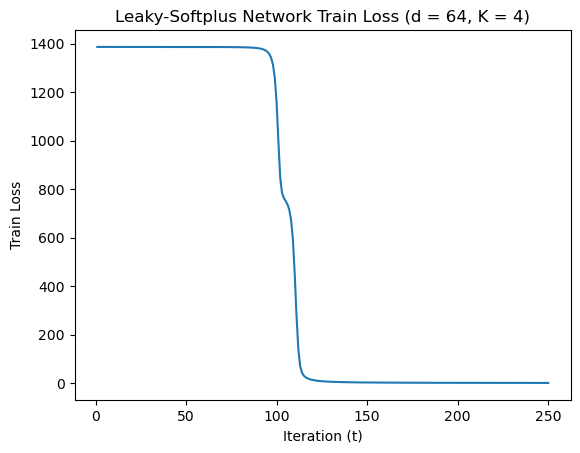

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:29:40,980 - INFO - Finish Epoch 1
2026-01-02 19:29:40,982 - INFO - Train loss: 1386.2926683425903, train accuracy: 26.1
2026-01-02 19:29:41,005 - INFO - Val loss: 1386.2919549942017, val accuracy: 27.7
2026-01-02 19:29:41,056 - INFO - Finish Epoch 2
2026-01-02 19:29:41,057 - INFO - Train loss: 1386.2915687561035, train accuracy: 28.4
2026-01-02 19:29:41,081 - INFO - Val loss: 1386.2908191680908, val accuracy: 30.3
  1%|          | 2/250 [00:00<00:18, 13.20it/s]2026-01-02 19:29:41,137 - INFO - Finish Epoch 3
2026-01-02 19:29:41,138 - INFO - Train loss: 1386.29043674469, train accuracy: 31.3
2026-01-02 19:29:41,162 - INFO - Val loss: 1386.2896928787231, val accuracy: 33.1
2026-01-02 19:29:41,213 - INFO - Finish Epoch 4
2026-01-02 19:29:41,214 - INFO - Train loss: 1386.2893028259277, train accuracy: 34.1
2026-01-02 19:29:41,238 - INFO - Val loss: 1386.2885494232178, val accuracy: 36.1
  2%|▏         | 4/250 [00:00<00:19, 12.91it/s]2026-

 27%|██▋       | 68/250 [00:05<00:14, 12.96it/s]2026-01-02 19:29:46,216 - INFO - Finish Epoch 69
2026-01-02 19:29:46,217 - INFO - Train loss: 1385.8731498718262, train accuracy: 100.0
2026-01-02 19:29:46,241 - INFO - Val loss: 1385.8530826568604, val accuracy: 100.0
2026-01-02 19:29:46,292 - INFO - Finish Epoch 70
2026-01-02 19:29:46,293 - INFO - Train loss: 1385.8382873535156, train accuracy: 100.0
2026-01-02 19:29:46,317 - INFO - Val loss: 1385.8160934448242, val accuracy: 100.0
 28%|██▊       | 70/250 [00:05<00:13, 12.99it/s]2026-01-02 19:29:46,369 - INFO - Finish Epoch 71
2026-01-02 19:29:46,370 - INFO - Train loss: 1385.7995471954346, train accuracy: 100.0
2026-01-02 19:29:46,394 - INFO - Val loss: 1385.7748565673828, val accuracy: 100.0
2026-01-02 19:29:46,446 - INFO - Finish Epoch 72
2026-01-02 19:29:46,447 - INFO - Train loss: 1385.756269454956, train accuracy: 100.0
2026-01-02 19:29:46,471 - INFO - Val loss: 1385.7287406921387, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:07<00:11, 13.06it/s]2026-01-02 19:29:48,818 - INFO - Finish Epoch 103
2026-01-02 19:29:48,819 - INFO - Train loss: 989.0342597961426, train accuracy: 66.6
2026-01-02 19:29:48,843 - INFO - Val loss: 914.0927286148071, val accuracy: 72.4
2026-01-02 19:29:48,894 - INFO - Finish Epoch 104
2026-01-02 19:29:48,895 - INFO - Train loss: 880.0560046434402, train accuracy: 60.6
2026-01-02 19:29:48,919 - INFO - Val loss: 806.5237159132957, val accuracy: 71.7
 42%|████▏     | 104/250 [00:07<00:11, 13.07it/s]2026-01-02 19:29:48,971 - INFO - Finish Epoch 105
2026-01-02 19:29:48,972 - INFO - Train loss: 801.7273734807968, train accuracy: 61.4
2026-01-02 19:29:48,995 - INFO - Val loss: 717.1808335483074, val accuracy: 78.9
2026-01-02 19:29:49,046 - INFO - Finish Epoch 106
2026-01-02 19:29:49,047 - INFO - Train loss: 715.3950119912624, train accuracy: 68.1
2026-01-02 19:29:49,071 - INFO - Val loss: 608.5716906189919, val accuracy: 85.7
 42%|████▏     | 106/250 [00:08<00:11,

 54%|█████▍    | 136/250 [00:10<00:08, 12.84it/s]2026-01-02 19:29:51,439 - INFO - Finish Epoch 137
2026-01-02 19:29:51,440 - INFO - Train loss: 3.003679482266307, train accuracy: 100.0
2026-01-02 19:29:51,464 - INFO - Val loss: 2.904319539666176, val accuracy: 100.0
2026-01-02 19:29:51,515 - INFO - Finish Epoch 138
2026-01-02 19:29:51,516 - INFO - Train loss: 2.8812790904194117, train accuracy: 100.0
2026-01-02 19:29:51,540 - INFO - Val loss: 2.7890806682407856, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 12.91it/s]2026-01-02 19:29:51,592 - INFO - Finish Epoch 139
2026-01-02 19:29:51,593 - INFO - Train loss: 2.7677685003727674, train accuracy: 100.0
2026-01-02 19:29:51,617 - INFO - Val loss: 2.6820009909570217, val accuracy: 100.0
2026-01-02 19:29:51,668 - INFO - Finish Epoch 140
2026-01-02 19:29:51,669 - INFO - Train loss: 2.6622439436614513, train accuracy: 100.0
2026-01-02 19:29:51,694 - INFO - Val loss: 2.58226677775383, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:29:53,988 - INFO - Val loss: 1.1755139427259564, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 13.10it/s]2026-01-02 19:29:54,040 - INFO - Finish Epoch 171
2026-01-02 19:29:54,041 - INFO - Train loss: 1.1715712463483214, train accuracy: 100.0
2026-01-02 19:29:54,065 - INFO - Val loss: 1.1534126726910472, val accuracy: 100.0
2026-01-02 19:29:54,116 - INFO - Finish Epoch 172
2026-01-02 19:29:54,117 - INFO - Train loss: 1.1496164491400123, train accuracy: 100.0
2026-01-02 19:29:54,141 - INFO - Val loss: 1.1320661576464772, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:05, 13.10it/s]2026-01-02 19:29:54,193 - INFO - Finish Epoch 173
2026-01-02 19:29:54,194 - INFO - Train loss: 1.1284089162945747, train accuracy: 100.0
2026-01-02 19:29:54,217 - INFO - Val loss: 1.1114459140226245, val accuracy: 100.0
2026-01-02 19:29:54,269 - INFO - Finish Epoch 174
2026-01-02 19:29:54,270 - INFO - Train loss: 1.1079138489440084, train accuracy: 100.0
2026-01-02 19:29:54,29

2026-01-02 19:29:56,581 - INFO - Train loss: 0.707725771702826, train accuracy: 100.0
2026-01-02 19:29:56,605 - INFO - Val loss: 0.7004453931003809, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 13.01it/s]2026-01-02 19:29:56,657 - INFO - Finish Epoch 205
2026-01-02 19:29:56,658 - INFO - Train loss: 0.6990371216088533, train accuracy: 100.0
2026-01-02 19:29:56,682 - INFO - Val loss: 0.6919181300327182, val accuracy: 100.0
2026-01-02 19:29:56,733 - INFO - Finish Epoch 206
2026-01-02 19:29:56,734 - INFO - Train loss: 0.6905450872145593, train accuracy: 100.0
2026-01-02 19:29:56,758 - INFO - Val loss: 0.6835788022726774, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 13.05it/s]2026-01-02 19:29:56,809 - INFO - Finish Epoch 207
2026-01-02 19:29:56,811 - INFO - Train loss: 0.6822386290878057, train accuracy: 100.0
2026-01-02 19:29:56,834 - INFO - Val loss: 0.675423068460077, val accuracy: 100.0
2026-01-02 19:29:56,885 - INFO - Finish Epoch 208
2026-01-02 19:29:56,886 

2026-01-02 19:29:59,183 - INFO - Finish Epoch 238
2026-01-02 19:29:59,184 - INFO - Train loss: 0.4934368096292019, train accuracy: 100.0
2026-01-02 19:29:59,208 - INFO - Val loss: 0.48964825412258506, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.02it/s]2026-01-02 19:29:59,261 - INFO - Finish Epoch 239
2026-01-02 19:29:59,262 - INFO - Train loss: 0.488968756981194, train accuracy: 100.0
2026-01-02 19:29:59,286 - INFO - Val loss: 0.48524460196495056, val accuracy: 100.0
2026-01-02 19:29:59,338 - INFO - Finish Epoch 240
2026-01-02 19:29:59,339 - INFO - Train loss: 0.48457534378394485, train accuracy: 100.0
2026-01-02 19:29:59,363 - INFO - Val loss: 0.4809115380048752, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.00it/s]2026-01-02 19:29:59,416 - INFO - Finish Epoch 241
2026-01-02 19:29:59,417 - INFO - Train loss: 0.4802501415833831, train accuracy: 100.0
2026-01-02 19:29:59,441 - INFO - Val loss: 0.4766495474614203, val accuracy: 100.0
2026-01-02 19:29:59,

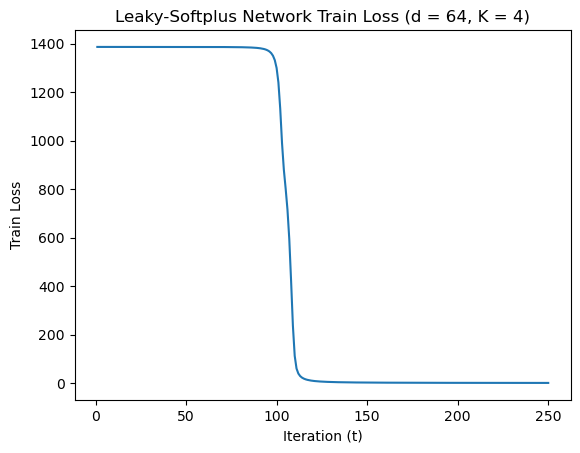

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:30:00,475 - INFO - Finish Epoch 1
2026-01-02 19:30:00,476 - INFO - Train loss: 1386.2940254211426, train accuracy: 25.5
2026-01-02 19:30:00,500 - INFO - Val loss: 1386.2932434082031, val accuracy: 27.3
2026-01-02 19:30:00,550 - INFO - Finish Epoch 2
2026-01-02 19:30:00,552 - INFO - Train loss: 1386.292833328247, train accuracy: 28.2
2026-01-02 19:30:00,575 - INFO - Val loss: 1386.2920274734497, val accuracy: 30.6
  1%|          | 2/250 [00:00<00:18, 13.16it/s]2026-01-02 19:30:00,627 - INFO - Finish Epoch 3
2026-01-02 19:30:00,628 - INFO - Train loss: 1386.2916374206543, train accuracy: 31.2
2026-01-02 19:30:00,652 - INFO - Val loss: 1386.2908353805542, val accuracy: 32.7
2026-01-02 19:30:00,703 - INFO - Finish Epoch 4
2026-01-02 19:30:00,704 - INFO - Train loss: 1386.29043674469, train accuracy: 33.7
2026-01-02 19:30:00,729 - INFO - Val loss: 1386.2896118164062, val accuracy: 35.8
  2%|▏         | 4/250 [00:00<00:18, 13.09it/s]2026-0

 27%|██▋       | 68/250 [00:05<00:14, 12.94it/s]2026-01-02 19:30:05,749 - INFO - Finish Epoch 69
2026-01-02 19:30:05,750 - INFO - Train loss: 1385.797342300415, train accuracy: 100.0
2026-01-02 19:30:05,774 - INFO - Val loss: 1385.7680921554565, val accuracy: 100.0
2026-01-02 19:30:05,825 - INFO - Finish Epoch 70
2026-01-02 19:30:05,826 - INFO - Train loss: 1385.751564025879, train accuracy: 100.0
2026-01-02 19:30:05,850 - INFO - Val loss: 1385.7186241149902, val accuracy: 100.0
 28%|██▊       | 70/250 [00:05<00:13, 12.97it/s]2026-01-02 19:30:05,902 - INFO - Finish Epoch 71
2026-01-02 19:30:05,903 - INFO - Train loss: 1385.6999502182007, train accuracy: 100.0
2026-01-02 19:30:05,927 - INFO - Val loss: 1385.6626567840576, val accuracy: 100.0
2026-01-02 19:30:05,978 - INFO - Finish Epoch 72
2026-01-02 19:30:05,979 - INFO - Train loss: 1385.6414623260498, train accuracy: 100.0
2026-01-02 19:30:06,003 - INFO - Val loss: 1385.5991020202637, val accuracy: 100.0
 29%|██▉       | 72/250 [00:05

 41%|████      | 102/250 [00:07<00:11, 13.03it/s]2026-01-02 19:30:08,364 - INFO - Finish Epoch 103
2026-01-02 19:30:08,365 - INFO - Train loss: 769.0563335418701, train accuracy: 52.1
2026-01-02 19:30:08,388 - INFO - Val loss: 639.3429322242737, val accuracy: 55.2
2026-01-02 19:30:08,439 - INFO - Finish Epoch 104
2026-01-02 19:30:08,440 - INFO - Train loss: 711.7586050033569, train accuracy: 57.0
2026-01-02 19:30:08,464 - INFO - Val loss: 577.9165434837341, val accuracy: 66.9
 42%|████▏     | 104/250 [00:08<00:11, 13.05it/s]2026-01-02 19:30:08,516 - INFO - Finish Epoch 105
2026-01-02 19:30:08,517 - INFO - Train loss: 628.7323808670044, train accuracy: 69.8
2026-01-02 19:30:08,541 - INFO - Val loss: 492.58991026878357, val accuracy: 75.2
2026-01-02 19:30:08,592 - INFO - Finish Epoch 106
2026-01-02 19:30:08,593 - INFO - Train loss: 524.0529429912567, train accuracy: 75.4
2026-01-02 19:30:08,617 - INFO - Val loss: 407.5357301235199, val accuracy: 75.6
 42%|████▏     | 106/250 [00:08<00:11

 54%|█████▍    | 136/250 [00:10<00:08, 13.01it/s]2026-01-02 19:30:10,967 - INFO - Finish Epoch 137
2026-01-02 19:30:10,968 - INFO - Train loss: 2.63172266446054, train accuracy: 100.0
2026-01-02 19:30:10,992 - INFO - Val loss: 2.5487093199044466, val accuracy: 100.0
2026-01-02 19:30:11,043 - INFO - Finish Epoch 138
2026-01-02 19:30:11,045 - INFO - Train loss: 2.508324723690748, train accuracy: 100.0
2026-01-02 19:30:11,069 - INFO - Val loss: 2.432060355320573, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.01it/s]2026-01-02 19:30:11,121 - INFO - Finish Epoch 139
2026-01-02 19:30:11,122 - INFO - Train loss: 2.3950966112315655, train accuracy: 100.0
2026-01-02 19:30:11,146 - INFO - Val loss: 2.3248099628835917, val accuracy: 100.0
2026-01-02 19:30:11,197 - INFO - Finish Epoch 140
2026-01-02 19:30:11,198 - INFO - Train loss: 2.290867341682315, train accuracy: 100.0
2026-01-02 19:30:11,222 - INFO - Val loss: 2.2258980199694633, val accuracy: 100.0
 56%|█████▌    | 140/250 [0

2026-01-02 19:30:13,525 - INFO - Val loss: 0.9295259676873684, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 13.03it/s]2026-01-02 19:30:13,577 - INFO - Finish Epoch 171
2026-01-02 19:30:13,578 - INFO - Train loss: 0.9234692705795169, train accuracy: 100.0
2026-01-02 19:30:13,603 - INFO - Val loss: 0.9106397498399019, val accuracy: 100.0
2026-01-02 19:30:13,655 - INFO - Finish Epoch 172
2026-01-02 19:30:13,656 - INFO - Train loss: 0.9048139452934265, train accuracy: 100.0
2026-01-02 19:30:13,680 - INFO - Val loss: 0.8924445984885097, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:06, 12.97it/s]2026-01-02 19:30:13,733 - INFO - Finish Epoch 173
2026-01-02 19:30:13,734 - INFO - Train loss: 0.8868333771824837, train accuracy: 100.0
2026-01-02 19:30:13,758 - INFO - Val loss: 0.8749042339622974, val accuracy: 100.0
2026-01-02 19:30:13,809 - INFO - Finish Epoch 174
2026-01-02 19:30:13,810 - INFO - Train loss: 0.8695013420656323, train accuracy: 100.0
2026-01-02 19:30:13,83

2026-01-02 19:30:16,116 - INFO - Train loss: 0.5391868646256626, train accuracy: 100.0
2026-01-02 19:30:16,139 - INFO - Val loss: 0.5343390975613147, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 13.16it/s]2026-01-02 19:30:16,191 - INFO - Finish Epoch 205
2026-01-02 19:30:16,192 - INFO - Train loss: 0.5321956316474825, train accuracy: 100.0
2026-01-02 19:30:16,217 - INFO - Val loss: 0.5274570796173066, val accuracy: 100.0
2026-01-02 19:30:16,267 - INFO - Finish Epoch 206
2026-01-02 19:30:16,268 - INFO - Train loss: 0.5253687999211252, train accuracy: 100.0
2026-01-02 19:30:16,292 - INFO - Val loss: 0.5207416354678571, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 13.14it/s]2026-01-02 19:30:16,344 - INFO - Finish Epoch 207
2026-01-02 19:30:16,345 - INFO - Train loss: 0.518699134234339, train accuracy: 100.0
2026-01-02 19:30:16,368 - INFO - Val loss: 0.5141822858713567, val accuracy: 100.0
2026-01-02 19:30:16,419 - INFO - Finish Epoch 208
2026-01-02 19:30:16,420

2026-01-02 19:30:18,663 - INFO - Val loss: 0.3702256018295884, val accuracy: 100.0
2026-01-02 19:30:18,714 - INFO - Finish Epoch 238
2026-01-02 19:30:18,715 - INFO - Train loss: 0.3691501682624221, train accuracy: 100.0
2026-01-02 19:30:18,739 - INFO - Val loss: 0.3667157886084169, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.14it/s]2026-01-02 19:30:18,790 - INFO - Finish Epoch 239
2026-01-02 19:30:18,791 - INFO - Train loss: 0.3656591649632901, train accuracy: 100.0
2026-01-02 19:30:18,815 - INFO - Val loss: 0.36326748598366976, val accuracy: 100.0
2026-01-02 19:30:18,866 - INFO - Finish Epoch 240
2026-01-02 19:30:18,867 - INFO - Train loss: 0.36223025992512703, train accuracy: 100.0
2026-01-02 19:30:18,891 - INFO - Val loss: 0.3598774764686823, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.13it/s]2026-01-02 19:30:18,943 - INFO - Finish Epoch 241
2026-01-02 19:30:18,944 - INFO - Train loss: 0.3588561962824315, train accuracy: 100.0
2026-01-02 19:30:18,

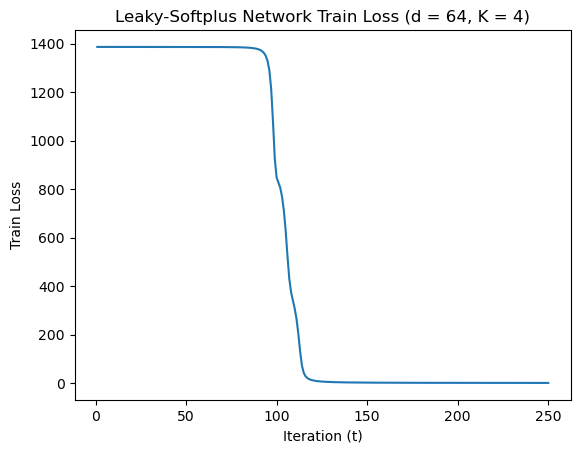

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:30:20,128 - INFO - Finish Epoch 1
2026-01-02 19:30:20,129 - INFO - Train loss: 1386.2944641113281, train accuracy: 25.2
2026-01-02 19:30:20,153 - INFO - Val loss: 1386.2938528060913, val accuracy: 26.9
2026-01-02 19:30:20,204 - INFO - Finish Epoch 2
2026-01-02 19:30:20,205 - INFO - Train loss: 1386.293544769287, train accuracy: 27.4
2026-01-02 19:30:20,228 - INFO - Val loss: 1386.2929182052612, val accuracy: 28.4
  1%|          | 2/250 [00:00<00:18, 13.17it/s]2026-01-02 19:30:20,280 - INFO - Finish Epoch 3
2026-01-02 19:30:20,281 - INFO - Train loss: 1386.2926063537598, train accuracy: 29.1
2026-01-02 19:30:20,305 - INFO - Val loss: 1386.291968345642, val accuracy: 30.6
2026-01-02 19:30:20,356 - INFO - Finish Epoch 4
2026-01-02 19:30:20,357 - INFO - Train loss: 1386.2916536331177, train accuracy: 30.9
2026-01-02 19:30:20,381 - INFO - Val loss: 1386.2910041809082, val accuracy: 32.8
  2%|▏         | 4/250 [00:00<00:18, 13.13it/s]2026-

 27%|██▋       | 68/250 [00:05<00:13, 13.06it/s]2026-01-02 19:30:25,339 - INFO - Finish Epoch 69
2026-01-02 19:30:25,340 - INFO - Train loss: 1386.05277633667, train accuracy: 99.8
2026-01-02 19:30:25,364 - INFO - Val loss: 1386.0429668426514, val accuracy: 99.8
2026-01-02 19:30:25,415 - INFO - Finish Epoch 70
2026-01-02 19:30:25,416 - INFO - Train loss: 1386.0366897583008, train accuracy: 99.8
2026-01-02 19:30:25,440 - INFO - Val loss: 1386.0259952545166, val accuracy: 99.8
 28%|██▊       | 70/250 [00:05<00:13, 13.07it/s]2026-01-02 19:30:25,492 - INFO - Finish Epoch 71
2026-01-02 19:30:25,493 - INFO - Train loss: 1386.0191354751587, train accuracy: 99.8
2026-01-02 19:30:25,517 - INFO - Val loss: 1386.0075054168701, val accuracy: 99.8
2026-01-02 19:30:25,567 - INFO - Finish Epoch 72
2026-01-02 19:30:25,568 - INFO - Train loss: 1385.999960899353, train accuracy: 99.8
2026-01-02 19:30:25,592 - INFO - Val loss: 1385.9872303009033, val accuracy: 99.8
 29%|██▉       | 72/250 [00:05<00:13, 1

 54%|█████▍    | 136/250 [00:10<00:08, 13.15it/s]2026-01-02 19:30:30,545 - INFO - Finish Epoch 137
2026-01-02 19:30:30,546 - INFO - Train loss: 5.0314905270934105, train accuracy: 100.0
2026-01-02 19:30:30,570 - INFO - Val loss: 4.7951438538730145, val accuracy: 100.0
2026-01-02 19:30:30,620 - INFO - Finish Epoch 138
2026-01-02 19:30:30,621 - INFO - Train loss: 4.723708458244801, train accuracy: 100.0
2026-01-02 19:30:30,645 - INFO - Val loss: 4.512450665235519, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.18it/s]2026-01-02 19:30:30,696 - INFO - Finish Epoch 139
2026-01-02 19:30:30,697 - INFO - Train loss: 4.448956038802862, train accuracy: 100.0
2026-01-02 19:30:30,721 - INFO - Val loss: 4.259029693901539, val accuracy: 100.0
2026-01-02 19:30:30,771 - INFO - Finish Epoch 140
2026-01-02 19:30:30,773 - INFO - Train loss: 4.202284719794989, train accuracy: 100.0
2026-01-02 19:30:30,797 - INFO - Val loss: 4.030669851228595, val accuracy: 100.0
 56%|█████▌    | 140/250 [00

2026-01-02 19:30:33,086 - INFO - Val loss: 1.4538842970505357, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:06, 13.13it/s]2026-01-02 19:30:33,138 - INFO - Finish Epoch 171
2026-01-02 19:30:33,139 - INFO - Train loss: 1.447226301766932, train accuracy: 100.0
2026-01-02 19:30:33,163 - INFO - Val loss: 1.421403357759118, val accuracy: 100.0
2026-01-02 19:30:33,213 - INFO - Finish Epoch 172
2026-01-02 19:30:33,214 - INFO - Train loss: 1.415043625049293, train accuracy: 100.0
2026-01-02 19:30:33,238 - INFO - Val loss: 1.3902310160920024, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:05, 13.15it/s]2026-01-02 19:30:33,289 - INFO - Finish Epoch 173
2026-01-02 19:30:33,290 - INFO - Train loss: 1.384157046675682, train accuracy: 100.0
2026-01-02 19:30:33,314 - INFO - Val loss: 1.3602951969951391, val accuracy: 100.0
2026-01-02 19:30:33,365 - INFO - Finish Epoch 174
2026-01-02 19:30:33,366 - INFO - Train loss: 1.354482403025031, train accuracy: 100.0
2026-01-02 19:30:33,390 - I

2026-01-02 19:30:35,670 - INFO - Train loss: 0.8095739437267184, train accuracy: 100.0
2026-01-02 19:30:35,693 - INFO - Val loss: 0.8004001593217254, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 13.00it/s]2026-01-02 19:30:35,745 - INFO - Finish Epoch 205
2026-01-02 19:30:35,747 - INFO - Train loss: 0.7984456224367023, train accuracy: 100.0
2026-01-02 19:30:35,771 - INFO - Val loss: 0.7895019841380417, val accuracy: 100.0
2026-01-02 19:30:35,821 - INFO - Finish Epoch 206
2026-01-02 19:30:35,822 - INFO - Train loss: 0.7875966615974903, train accuracy: 100.0
2026-01-02 19:30:35,846 - INFO - Val loss: 0.7788654994219542, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 13.04it/s]2026-01-02 19:30:35,898 - INFO - Finish Epoch 207
2026-01-02 19:30:35,899 - INFO - Train loss: 0.7770164087414742, train accuracy: 100.0
2026-01-02 19:30:35,923 - INFO - Val loss: 0.7684949031099677, val accuracy: 100.0
2026-01-02 19:30:35,973 - INFO - Finish Epoch 208
2026-01-02 19:30:35,97

2026-01-02 19:30:38,261 - INFO - Finish Epoch 238
2026-01-02 19:30:38,262 - INFO - Train loss: 0.543614603113383, train accuracy: 100.0
2026-01-02 19:30:38,286 - INFO - Val loss: 0.5391136170364916, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.09it/s]2026-01-02 19:30:38,338 - INFO - Finish Epoch 239
2026-01-02 19:30:38,339 - INFO - Train loss: 0.5382516495883465, train accuracy: 100.0
2026-01-02 19:30:38,363 - INFO - Val loss: 0.5338348608929664, val accuracy: 100.0
2026-01-02 19:30:38,413 - INFO - Finish Epoch 240
2026-01-02 19:30:38,414 - INFO - Train loss: 0.532989784842357, train accuracy: 100.0
2026-01-02 19:30:38,438 - INFO - Val loss: 0.5286482644733042, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.10it/s]2026-01-02 19:30:38,490 - INFO - Finish Epoch 241
2026-01-02 19:30:38,491 - INFO - Train loss: 0.5278204530477524, train accuracy: 100.0
2026-01-02 19:30:38,515 - INFO - Val loss: 0.5235550492070615, val accuracy: 100.0
2026-01-02 19:30:38,565 

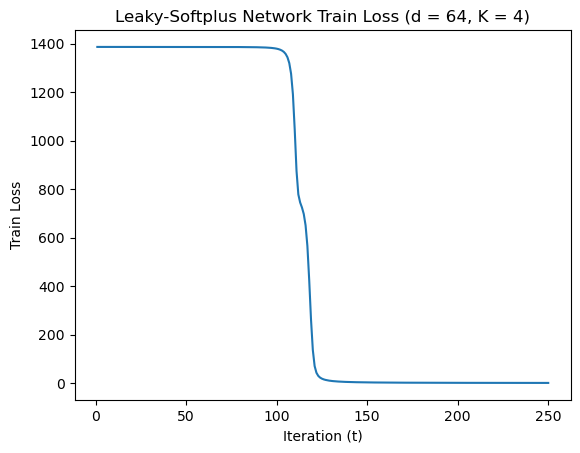

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:30:39,542 - INFO - Finish Epoch 1
2026-01-02 19:30:39,543 - INFO - Train loss: 1386.2931880950928, train accuracy: 27.2
2026-01-02 19:30:39,567 - INFO - Val loss: 1386.2924547195435, val accuracy: 28.7
2026-01-02 19:30:39,618 - INFO - Finish Epoch 2
2026-01-02 19:30:39,619 - INFO - Train loss: 1386.2921199798584, train accuracy: 29.5
2026-01-02 19:30:39,643 - INFO - Val loss: 1386.2913675308228, val accuracy: 31.2
  1%|          | 2/250 [00:00<00:18, 13.16it/s]2026-01-02 19:30:39,695 - INFO - Finish Epoch 3
2026-01-02 19:30:39,696 - INFO - Train loss: 1386.291021347046, train accuracy: 32.3
2026-01-02 19:30:39,720 - INFO - Val loss: 1386.2902717590332, val accuracy: 33.6
2026-01-02 19:30:39,770 - INFO - Finish Epoch 4
2026-01-02 19:30:39,771 - INFO - Train loss: 1386.2899360656738, train accuracy: 34.0
2026-01-02 19:30:39,795 - INFO - Val loss: 1386.2891845703125, val accuracy: 35.2
  2%|▏         | 4/250 [00:00<00:18, 13.15it/s]2026

 27%|██▋       | 68/250 [00:05<00:14, 12.90it/s]2026-01-02 19:30:44,775 - INFO - Finish Epoch 69
2026-01-02 19:30:44,776 - INFO - Train loss: 1385.8164339065552, train accuracy: 98.3
2026-01-02 19:30:44,800 - INFO - Val loss: 1385.7868118286133, val accuracy: 98.3
2026-01-02 19:30:44,851 - INFO - Finish Epoch 70
2026-01-02 19:30:44,852 - INFO - Train loss: 1385.768424987793, train accuracy: 98.1
2026-01-02 19:30:44,876 - INFO - Val loss: 1385.7345113754272, val accuracy: 98.2
 28%|██▊       | 70/250 [00:05<00:13, 12.96it/s]2026-01-02 19:30:44,928 - INFO - Finish Epoch 71
2026-01-02 19:30:44,929 - INFO - Train loss: 1385.7134084701538, train accuracy: 97.6
2026-01-02 19:30:44,953 - INFO - Val loss: 1385.6743488311768, val accuracy: 97.6
2026-01-02 19:30:45,005 - INFO - Finish Epoch 72
2026-01-02 19:30:45,006 - INFO - Train loss: 1385.649959564209, train accuracy: 97.3
2026-01-02 19:30:45,030 - INFO - Val loss: 1385.6046981811523, val accuracy: 97.3
 29%|██▉       | 72/250 [00:05<00:13, 

 54%|█████▍    | 136/250 [00:10<00:08, 12.99it/s]2026-01-02 19:30:50,000 - INFO - Finish Epoch 137
2026-01-02 19:30:50,001 - INFO - Train loss: 7.199556685984135, train accuracy: 100.0
2026-01-02 19:30:50,025 - INFO - Val loss: 6.650170162320137, val accuracy: 100.0
2026-01-02 19:30:50,076 - INFO - Finish Epoch 138
2026-01-02 19:30:50,077 - INFO - Train loss: 6.555776417255402, train accuracy: 100.0
2026-01-02 19:30:50,101 - INFO - Val loss: 6.092273600399494, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.00it/s]2026-01-02 19:30:50,153 - INFO - Finish Epoch 139
2026-01-02 19:30:50,154 - INFO - Train loss: 6.013508420437574, train accuracy: 100.0
2026-01-02 19:30:50,177 - INFO - Val loss: 5.6171659007668495, val accuracy: 100.0
2026-01-02 19:30:50,228 - INFO - Finish Epoch 140
2026-01-02 19:30:50,229 - INFO - Train loss: 5.550604276359081, train accuracy: 100.0
2026-01-02 19:30:50,253 - INFO - Val loss: 5.207788623869419, val accuracy: 100.0
 56%|█████▌    | 140/250 [00:

 68%|██████▊   | 170/250 [00:13<00:06, 13.09it/s]2026-01-02 19:30:52,639 - INFO - Finish Epoch 171
2026-01-02 19:30:52,640 - INFO - Train loss: 1.5283325519412756, train accuracy: 100.0
2026-01-02 19:30:52,664 - INFO - Val loss: 1.494710747152567, val accuracy: 100.0
2026-01-02 19:30:52,715 - INFO - Finish Epoch 172
2026-01-02 19:30:52,716 - INFO - Train loss: 1.4909161161631346, train accuracy: 100.0
2026-01-02 19:30:52,740 - INFO - Val loss: 1.4587622163817286, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:05, 13.10it/s]2026-01-02 19:30:52,791 - INFO - Finish Epoch 173
2026-01-02 19:30:52,793 - INFO - Train loss: 1.455171869136393, train accuracy: 100.0
2026-01-02 19:30:52,817 - INFO - Val loss: 1.424388712272048, val accuracy: 100.0
2026-01-02 19:30:52,868 - INFO - Finish Epoch 174
2026-01-02 19:30:52,869 - INFO - Train loss: 1.4209854267537594, train accuracy: 100.0
2026-01-02 19:30:52,894 - INFO - Val loss: 1.3914893455803394, val accuracy: 100.0
 70%|██████▉   | 174/250 

2026-01-02 19:30:55,209 - INFO - Val loss: 0.8072369052097201, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 13.00it/s]2026-01-02 19:30:55,261 - INFO - Finish Epoch 205
2026-01-02 19:30:55,262 - INFO - Train loss: 0.8063354836776853, train accuracy: 100.0
2026-01-02 19:30:55,286 - INFO - Val loss: 0.7956836950033903, val accuracy: 100.0
2026-01-02 19:30:55,337 - INFO - Finish Epoch 206
2026-01-02 19:30:55,338 - INFO - Train loss: 0.7948152520693839, train accuracy: 100.0
2026-01-02 19:30:55,362 - INFO - Val loss: 0.7844313667155802, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 13.02it/s]2026-01-02 19:30:55,414 - INFO - Finish Epoch 207
2026-01-02 19:30:55,415 - INFO - Train loss: 0.7835908215492964, train accuracy: 100.0
2026-01-02 19:30:55,439 - INFO - Val loss: 0.7734707212075591, val accuracy: 100.0
2026-01-02 19:30:55,489 - INFO - Finish Epoch 208
2026-01-02 19:30:55,491 - INFO - Train loss: 0.7726577669382095, train accuracy: 100.0
2026-01-02 19:30:55,51

2026-01-02 19:30:57,786 - INFO - Train loss: 0.540061037056148, train accuracy: 100.0
2026-01-02 19:30:57,810 - INFO - Val loss: 0.5348859638907015, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.05it/s]2026-01-02 19:30:57,863 - INFO - Finish Epoch 239
2026-01-02 19:30:57,864 - INFO - Train loss: 0.5345584088936448, train accuracy: 100.0
2026-01-02 19:30:57,888 - INFO - Val loss: 0.5294771348126233, val accuracy: 100.0
2026-01-02 19:30:57,940 - INFO - Finish Epoch 240
2026-01-02 19:30:57,941 - INFO - Train loss: 0.5291598727926612, train accuracy: 100.0
2026-01-02 19:30:57,965 - INFO - Val loss: 0.524167307652533, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.02it/s]2026-01-02 19:30:58,016 - INFO - Finish Epoch 241
2026-01-02 19:30:58,018 - INFO - Train loss: 0.5238591679371893, train accuracy: 100.0
2026-01-02 19:30:58,041 - INFO - Val loss: 0.5189575706608593, val accuracy: 100.0
2026-01-02 19:30:58,092 - INFO - Finish Epoch 242
2026-01-02 19:30:58,093 

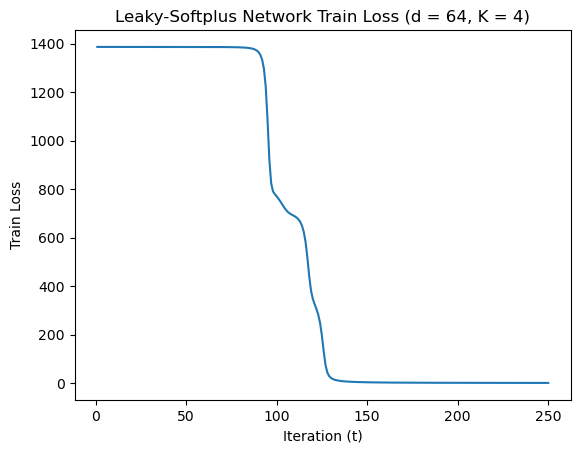

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:30:59,068 - INFO - Finish Epoch 1
2026-01-02 19:30:59,069 - INFO - Train loss: 1386.2952480316162, train accuracy: 22.0
2026-01-02 19:30:59,093 - INFO - Val loss: 1386.2945413589478, val accuracy: 23.2
2026-01-02 19:30:59,144 - INFO - Finish Epoch 2
2026-01-02 19:30:59,145 - INFO - Train loss: 1386.2942123413086, train accuracy: 24.0
2026-01-02 19:30:59,169 - INFO - Val loss: 1386.2934837341309, val accuracy: 25.3
  1%|          | 2/250 [00:00<00:18, 13.13it/s]2026-01-02 19:30:59,223 - INFO - Finish Epoch 3
2026-01-02 19:30:59,225 - INFO - Train loss: 1386.2931442260742, train accuracy: 25.7
2026-01-02 19:30:59,249 - INFO - Val loss: 1386.2924156188965, val accuracy: 27.1
2026-01-02 19:30:59,301 - INFO - Finish Epoch 4
2026-01-02 19:30:59,302 - INFO - Train loss: 1386.2920684814453, train accuracy: 27.9
2026-01-02 19:30:59,326 - INFO - Val loss: 1386.2913513183594, val accuracy: 29.8
  2%|▏         | 4/250 [00:00<00:19, 12.89it/s]202

 27%|██▋       | 68/250 [00:05<00:14, 12.97it/s]2026-01-02 19:31:04,289 - INFO - Finish Epoch 69
2026-01-02 19:31:04,290 - INFO - Train loss: 1385.9682512283325, train accuracy: 99.9
2026-01-02 19:31:04,314 - INFO - Val loss: 1385.9523239135742, val accuracy: 99.9
2026-01-02 19:31:04,365 - INFO - Finish Epoch 70
2026-01-02 19:31:04,366 - INFO - Train loss: 1385.9430904388428, train accuracy: 99.9
2026-01-02 19:31:04,389 - INFO - Val loss: 1385.9254932403564, val accuracy: 99.9
 28%|██▊       | 70/250 [00:05<00:13, 13.03it/s]2026-01-02 19:31:04,441 - INFO - Finish Epoch 71
2026-01-02 19:31:04,442 - INFO - Train loss: 1385.915286064148, train accuracy: 99.9
2026-01-02 19:31:04,466 - INFO - Val loss: 1385.8958053588867, val accuracy: 99.9
2026-01-02 19:31:04,517 - INFO - Finish Epoch 72
2026-01-02 19:31:04,518 - INFO - Train loss: 1385.884485244751, train accuracy: 99.9
2026-01-02 19:31:04,541 - INFO - Val loss: 1385.8628044128418, val accuracy: 99.9
 29%|██▉       | 72/250 [00:05<00:13, 

 54%|█████▍    | 136/250 [00:10<00:08, 13.04it/s]2026-01-02 19:31:09,509 - INFO - Finish Epoch 137
2026-01-02 19:31:09,510 - INFO - Train loss: 4.496220462024212, train accuracy: 100.0
2026-01-02 19:31:09,534 - INFO - Val loss: 4.30941504240036, val accuracy: 100.0
2026-01-02 19:31:09,585 - INFO - Finish Epoch 138
2026-01-02 19:31:09,586 - INFO - Train loss: 4.313610076904297, train accuracy: 100.0
2026-01-02 19:31:09,610 - INFO - Val loss: 4.139432977885008, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:10<00:08, 13.04it/s]2026-01-02 19:31:09,663 - INFO - Finish Epoch 139
2026-01-02 19:31:09,664 - INFO - Train loss: 4.144240006804466, train accuracy: 100.0
2026-01-02 19:31:09,688 - INFO - Val loss: 3.9814637508243322, val accuracy: 100.0
2026-01-02 19:31:09,739 - INFO - Finish Epoch 140
2026-01-02 19:31:09,740 - INFO - Train loss: 3.9867550618946552, train accuracy: 100.0
2026-01-02 19:31:09,764 - INFO - Val loss: 3.8342894427478313, val accuracy: 100.0
 56%|█████▌    | 140/250 [00

2026-01-02 19:31:12,217 - INFO - Val loss: 1.7496173726394773, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:13<00:07, 11.42it/s]2026-01-02 19:31:12,268 - INFO - Finish Epoch 171
2026-01-02 19:31:12,270 - INFO - Train loss: 1.7544061304070055, train accuracy: 100.0
2026-01-02 19:31:12,293 - INFO - Val loss: 1.716657520737499, val accuracy: 100.0
2026-01-02 19:31:12,344 - INFO - Finish Epoch 172
2026-01-02 19:31:12,345 - INFO - Train loss: 1.7213570191524923, train accuracy: 100.0
2026-01-02 19:31:12,369 - INFO - Val loss: 1.684817579574883, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:13<00:06, 11.88it/s]2026-01-02 19:31:12,421 - INFO - Finish Epoch 173
2026-01-02 19:31:12,424 - INFO - Train loss: 1.6894321274012327, train accuracy: 100.0
2026-01-02 19:31:12,448 - INFO - Val loss: 1.6540452213957906, val accuracy: 100.0
2026-01-02 19:31:12,499 - INFO - Finish Epoch 174
2026-01-02 19:31:12,500 - INFO - Train loss: 1.6585778519511223, train accuracy: 100.0
2026-01-02 19:31:12,524 

2026-01-02 19:31:14,821 - INFO - Train loss: 1.055046594236046, train accuracy: 100.0
2026-01-02 19:31:14,845 - INFO - Val loss: 1.0393002072814852, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:15<00:03, 12.93it/s]2026-01-02 19:31:14,897 - INFO - Finish Epoch 205
2026-01-02 19:31:14,898 - INFO - Train loss: 1.041928990278393, train accuracy: 100.0
2026-01-02 19:31:14,922 - INFO - Val loss: 1.026516871759668, val accuracy: 100.0
2026-01-02 19:31:14,973 - INFO - Finish Epoch 206
2026-01-02 19:31:14,974 - INFO - Train loss: 1.02910095336847, train accuracy: 100.0
2026-01-02 19:31:14,998 - INFO - Val loss: 1.0140170624945313, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:15<00:03, 12.97it/s]2026-01-02 19:31:15,050 - INFO - Finish Epoch 207
2026-01-02 19:31:15,051 - INFO - Train loss: 1.0165598983876407, train accuracy: 100.0
2026-01-02 19:31:15,075 - INFO - Val loss: 1.0017909498419613, val accuracy: 100.0
2026-01-02 19:31:15,127 - INFO - Finish Epoch 208
2026-01-02 19:31:15,128 - I

2026-01-02 19:31:17,424 - INFO - Finish Epoch 238
2026-01-02 19:31:17,425 - INFO - Train loss: 0.7314519342035055, train accuracy: 100.0
2026-01-02 19:31:17,449 - INFO - Val loss: 0.7231018072925508, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:18<00:00, 13.06it/s]2026-01-02 19:31:17,501 - INFO - Finish Epoch 239
2026-01-02 19:31:17,502 - INFO - Train loss: 0.7247105157002807, train accuracy: 100.0
2026-01-02 19:31:17,526 - INFO - Val loss: 0.7164911413565278, val accuracy: 100.0
2026-01-02 19:31:17,577 - INFO - Finish Epoch 240
2026-01-02 19:31:17,578 - INFO - Train loss: 0.7180728146340698, train accuracy: 100.0
2026-01-02 19:31:17,603 - INFO - Val loss: 0.7099886622745544, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:18<00:00, 13.04it/s]2026-01-02 19:31:17,656 - INFO - Finish Epoch 241
2026-01-02 19:31:17,657 - INFO - Train loss: 0.7115527498535812, train accuracy: 100.0
2026-01-02 19:31:17,681 - INFO - Val loss: 0.7035957470070571, val accuracy: 100.0
2026-01-02 19:31:17,73

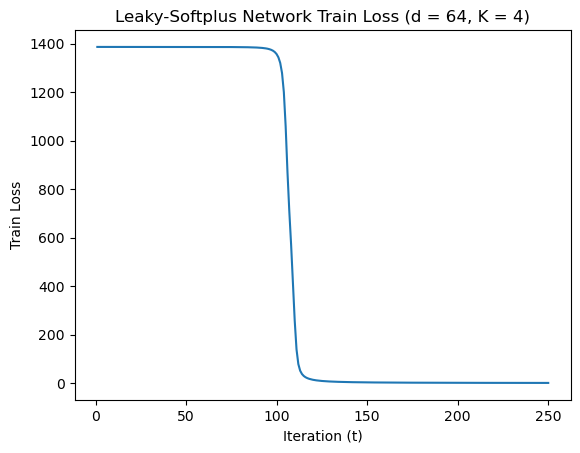

===== ACTIVATION FUNCTION:  GELU  =====
=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:31:18,691 - INFO - Finish Epoch 1
2026-01-02 19:31:18,693 - INFO - Train loss: 1386.2942276000977, train accuracy: 25.4
2026-01-02 19:31:18,709 - INFO - Val loss: 1386.293459892273, val accuracy: 27.0
2026-01-02 19:31:18,747 - INFO - Finish Epoch 2
2026-01-02 19:31:18,749 - INFO - Train loss: 1386.29310131073, train accuracy: 28.2
2026-01-02 19:31:18,765 - INFO - Val loss: 1386.2923374176025, val accuracy: 30.0
  1%|          | 2/250 [00:00<00:13, 17.77it/s]2026-01-02 19:31:18,804 - INFO - Finish Epoch 3
2026-01-02 19:31:18,805 - INFO - Train loss: 1386.2919721603394, train accuracy: 30.7
2026-01-02 19:31:18,822 - INFO - Val loss: 1386.2912044525146, val accuracy: 32.4
2026-01-02 19:31:18,860 - INFO - Finish Epoch 4
2026-01-02 19:31:18,861 - INFO - Train loss: 1386.290831565857, train accuracy: 33.1
2026-01-02 19:31:18,877 - INFO - Val loss: 1386.2900371551514, val accuracy: 34.4
  2%|▏         | 4/250 [00:00<00:13, 17.81it/s]2026-01

 27%|██▋       | 68/250 [00:03<00:10, 17.68it/s]2026-01-02 19:31:22,538 - INFO - Finish Epoch 69
2026-01-02 19:31:22,539 - INFO - Train loss: 1385.8565645217896, train accuracy: 99.7
2026-01-02 19:31:22,556 - INFO - Val loss: 1385.8305320739746, val accuracy: 99.7
2026-01-02 19:31:22,594 - INFO - Finish Epoch 70
2026-01-02 19:31:22,595 - INFO - Train loss: 1385.8175296783447, train accuracy: 99.7
2026-01-02 19:31:22,612 - INFO - Val loss: 1385.7882261276245, val accuracy: 99.7
 28%|██▊       | 70/250 [00:03<00:10, 17.71it/s]2026-01-02 19:31:22,651 - INFO - Finish Epoch 71
2026-01-02 19:31:22,652 - INFO - Train loss: 1385.773609161377, train accuracy: 99.7
2026-01-02 19:31:22,668 - INFO - Val loss: 1385.7405099868774, val accuracy: 99.7
2026-01-02 19:31:22,707 - INFO - Finish Epoch 72
2026-01-02 19:31:22,708 - INFO - Train loss: 1385.7239999771118, train accuracy: 99.7
2026-01-02 19:31:22,724 - INFO - Val loss: 1385.6864643096924, val accuracy: 99.7
 29%|██▉       | 72/250 [00:04<00:10,

 54%|█████▍    | 136/250 [00:07<00:06, 17.62it/s]2026-01-02 19:31:26,381 - INFO - Finish Epoch 137
2026-01-02 19:31:26,383 - INFO - Train loss: 3.9227291867136955, train accuracy: 100.0
2026-01-02 19:31:26,399 - INFO - Val loss: 3.732680805027485, val accuracy: 100.0
2026-01-02 19:31:26,437 - INFO - Finish Epoch 138
2026-01-02 19:31:26,438 - INFO - Train loss: 3.7211350835859776, train accuracy: 100.0
2026-01-02 19:31:26,455 - INFO - Val loss: 3.5473804641515017, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.66it/s]2026-01-02 19:31:26,494 - INFO - Finish Epoch 139
2026-01-02 19:31:26,495 - INFO - Train loss: 3.5372451096773148, train accuracy: 100.0
2026-01-02 19:31:26,511 - INFO - Val loss: 3.377846635878086, val accuracy: 100.0
2026-01-02 19:31:26,550 - INFO - Finish Epoch 140
2026-01-02 19:31:26,551 - INFO - Train loss: 3.3689110167324543, train accuracy: 100.0
2026-01-02 19:31:26,567 - INFO - Val loss: 3.2222247775644064, val accuracy: 100.0
 56%|█████▌    | 140/250

2026-01-02 19:31:28,256 - INFO - Val loss: 1.2586578531190753, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.67it/s]2026-01-02 19:31:28,295 - INFO - Finish Epoch 171
2026-01-02 19:31:28,296 - INFO - Train loss: 1.2581358393654227, train accuracy: 100.0
2026-01-02 19:31:28,313 - INFO - Val loss: 1.2313158111646771, val accuracy: 100.0
2026-01-02 19:31:28,351 - INFO - Finish Epoch 172
2026-01-02 19:31:28,352 - INFO - Train loss: 1.2308335667476058, train accuracy: 100.0
2026-01-02 19:31:28,368 - INFO - Val loss: 1.2050222288817167, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.71it/s]2026-01-02 19:31:28,407 - INFO - Finish Epoch 173
2026-01-02 19:31:28,408 - INFO - Train loss: 1.2045748457312584, train accuracy: 100.0
2026-01-02 19:31:28,425 - INFO - Val loss: 1.1797139830887318, val accuracy: 100.0
2026-01-02 19:31:28,463 - INFO - Finish Epoch 174
2026-01-02 19:31:28,465 - INFO - Train loss: 1.1793004712089896, train accuracy: 100.0
2026-01-02 19:31:28,48

2026-01-02 19:31:30,184 - INFO - Train loss: 0.7069253008812666, train accuracy: 100.0
2026-01-02 19:31:30,200 - INFO - Val loss: 0.6971599142998457, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.54it/s]2026-01-02 19:31:30,240 - INFO - Finish Epoch 205
2026-01-02 19:31:30,241 - INFO - Train loss: 0.697139460593462, train accuracy: 100.0
2026-01-02 19:31:30,258 - INFO - Val loss: 0.6876084804534912, val accuracy: 100.0
2026-01-02 19:31:30,296 - INFO - Finish Epoch 206
2026-01-02 19:31:30,297 - INFO - Train loss: 0.6875897930003703, train accuracy: 100.0
2026-01-02 19:31:30,314 - INFO - Val loss: 0.6782892728224397, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.58it/s]2026-01-02 19:31:30,353 - INFO - Finish Epoch 207
2026-01-02 19:31:30,354 - INFO - Train loss: 0.678276389837265, train accuracy: 100.0
2026-01-02 19:31:30,371 - INFO - Val loss: 0.6691962629556656, val accuracy: 100.0
2026-01-02 19:31:30,409 - INFO - Finish Epoch 208
2026-01-02 19:31:30,410 

2026-01-02 19:31:32,108 - INFO - Finish Epoch 238
2026-01-02 19:31:32,109 - INFO - Train loss: 0.4719600696116686, train accuracy: 100.0
2026-01-02 19:31:32,126 - INFO - Val loss: 0.4671793777961284, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.73it/s]2026-01-02 19:31:32,166 - INFO - Finish Epoch 239
2026-01-02 19:31:32,167 - INFO - Train loss: 0.4672116052825004, train accuracy: 100.0
2026-01-02 19:31:32,184 - INFO - Val loss: 0.462513166712597, val accuracy: 100.0
2026-01-02 19:31:32,223 - INFO - Finish Epoch 240
2026-01-02 19:31:32,224 - INFO - Train loss: 0.4625458074733615, train accuracy: 100.0
2026-01-02 19:31:32,241 - INFO - Val loss: 0.45793379889801145, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.64it/s]2026-01-02 19:31:32,281 - INFO - Finish Epoch 241
2026-01-02 19:31:32,282 - INFO - Train loss: 0.45796411018818617, train accuracy: 100.0
2026-01-02 19:31:32,299 - INFO - Val loss: 0.45343414694070816, val accuracy: 100.0
2026-01-02 19:31:32,

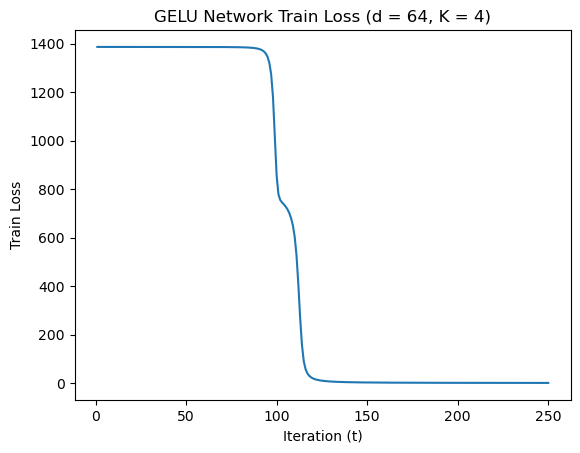

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:31:33,127 - INFO - Finish Epoch 1
2026-01-02 19:31:33,128 - INFO - Train loss: 1386.2960386276245, train accuracy: 20.9
2026-01-02 19:31:33,145 - INFO - Val loss: 1386.2953128814697, val accuracy: 22.2
2026-01-02 19:31:33,183 - INFO - Finish Epoch 2
2026-01-02 19:31:33,185 - INFO - Train loss: 1386.2949314117432, train accuracy: 22.8
2026-01-02 19:31:33,201 - INFO - Val loss: 1386.2941570281982, val accuracy: 24.0
  1%|          | 2/250 [00:00<00:14, 17.68it/s]2026-01-02 19:31:33,240 - INFO - Finish Epoch 3
2026-01-02 19:31:33,241 - INFO - Train loss: 1386.2938022613525, train accuracy: 24.7
2026-01-02 19:31:33,258 - INFO - Val loss: 1386.2930088043213, val accuracy: 26.5
2026-01-02 19:31:33,296 - INFO - Finish Epoch 4
2026-01-02 19:31:33,297 - INFO - Train loss: 1386.2926349639893, train accuracy: 26.7
2026-01-02 19:31:33,314 - INFO - Val loss: 1386.291862487793, val accuracy: 27.9
  2%|▏         | 4/250 [00:00<00:13, 17.75it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.59it/s]2026-01-02 19:31:36,956 - INFO - Finish Epoch 69
2026-01-02 19:31:36,957 - INFO - Train loss: 1385.8893823623657, train accuracy: 100.0
2026-01-02 19:31:36,974 - INFO - Val loss: 1385.8656148910522, val accuracy: 100.0
2026-01-02 19:31:37,012 - INFO - Finish Epoch 70
2026-01-02 19:31:37,013 - INFO - Train loss: 1385.8537664413452, train accuracy: 100.0
2026-01-02 19:31:37,029 - INFO - Val loss: 1385.8270330429077, val accuracy: 100.0
 28%|██▊       | 70/250 [00:03<00:10, 17.64it/s]2026-01-02 19:31:37,068 - INFO - Finish Epoch 71
2026-01-02 19:31:37,069 - INFO - Train loss: 1385.8137702941895, train accuracy: 100.0
2026-01-02 19:31:37,086 - INFO - Val loss: 1385.7835865020752, val accuracy: 100.0
2026-01-02 19:31:37,125 - INFO - Finish Epoch 72
2026-01-02 19:31:37,126 - INFO - Train loss: 1385.7686595916748, train accuracy: 100.0
2026-01-02 19:31:37,143 - INFO - Val loss: 1385.7344884872437, val accuracy: 100.0
 29%|██▉       | 72/250 [00:

 41%|████      | 102/250 [00:05<00:08, 17.73it/s]2026-01-02 19:31:38,881 - INFO - Finish Epoch 103
2026-01-02 19:31:38,882 - INFO - Train loss: 766.4417271018028, train accuracy: 52.5
2026-01-02 19:31:38,899 - INFO - Val loss: 740.059093952179, val accuracy: 52.2
2026-01-02 19:31:38,937 - INFO - Finish Epoch 104
2026-01-02 19:31:38,938 - INFO - Train loss: 740.8013559579849, train accuracy: 52.7
2026-01-02 19:31:38,955 - INFO - Val loss: 720.7265725135803, val accuracy: 55.1
 42%|████▏     | 104/250 [00:05<00:08, 17.70it/s]2026-01-02 19:31:38,994 - INFO - Finish Epoch 105
2026-01-02 19:31:38,995 - INFO - Train loss: 719.437973856926, train accuracy: 56.2
2026-01-02 19:31:39,012 - INFO - Val loss: 698.0984712839127, val accuracy: 57.5
2026-01-02 19:31:39,050 - INFO - Finish Epoch 106
2026-01-02 19:31:39,051 - INFO - Train loss: 691.9149116277695, train accuracy: 58.7
2026-01-02 19:31:39,067 - INFO - Val loss: 661.4865274429321, val accuracy: 62.3
 42%|████▏     | 106/250 [00:05<00:08, 1

 54%|█████▍    | 136/250 [00:07<00:06, 17.82it/s]2026-01-02 19:31:40,789 - INFO - Finish Epoch 137
2026-01-02 19:31:40,790 - INFO - Train loss: 2.6764633040875196, train accuracy: 100.0
2026-01-02 19:31:40,807 - INFO - Val loss: 2.5927420742809772, val accuracy: 100.0
2026-01-02 19:31:40,844 - INFO - Finish Epoch 138
2026-01-02 19:31:40,845 - INFO - Train loss: 2.562729187309742, train accuracy: 100.0
2026-01-02 19:31:40,862 - INFO - Val loss: 2.4851060919463634, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.86it/s]2026-01-02 19:31:40,901 - INFO - Finish Epoch 139
2026-01-02 19:31:40,902 - INFO - Train loss: 2.457483373582363, train accuracy: 100.0
2026-01-02 19:31:40,918 - INFO - Val loss: 2.385326161980629, val accuracy: 100.0
2026-01-02 19:31:40,956 - INFO - Finish Epoch 140
2026-01-02 19:31:40,957 - INFO - Train loss: 2.359838515520096, train accuracy: 100.0
2026-01-02 19:31:40,974 - INFO - Val loss: 2.2926043700426817, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:31:42,664 - INFO - Val loss: 1.0092407688498497, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.72it/s]2026-01-02 19:31:42,703 - INFO - Finish Epoch 171
2026-01-02 19:31:42,704 - INFO - Train loss: 1.0045009646564722, train accuracy: 100.0
2026-01-02 19:31:42,721 - INFO - Val loss: 0.989516731351614, val accuracy: 100.0
2026-01-02 19:31:42,759 - INFO - Finish Epoch 172
2026-01-02 19:31:42,760 - INFO - Train loss: 0.9849550249055028, train accuracy: 100.0
2026-01-02 19:31:42,777 - INFO - Val loss: 0.9704770529642701, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.71it/s]2026-01-02 19:31:42,816 - INFO - Finish Epoch 173
2026-01-02 19:31:42,817 - INFO - Train loss: 0.9660828905180097, train accuracy: 100.0
2026-01-02 19:31:42,834 - INFO - Val loss: 0.9520994904451072, val accuracy: 100.0
2026-01-02 19:31:42,872 - INFO - Finish Epoch 174
2026-01-02 19:31:42,873 - INFO - Train loss: 0.9478681483305991, train accuracy: 100.0
2026-01-02 19:31:42,890

2026-01-02 19:31:44,602 - INFO - Train loss: 0.5952981146983802, train accuracy: 100.0
2026-01-02 19:31:44,619 - INFO - Val loss: 0.5893757939338684, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.19it/s]2026-01-02 19:31:44,659 - INFO - Finish Epoch 205
2026-01-02 19:31:44,660 - INFO - Train loss: 0.5877186367288232, train accuracy: 100.0
2026-01-02 19:31:44,677 - INFO - Val loss: 0.5819327980279922, val accuracy: 100.0
2026-01-02 19:31:44,715 - INFO - Finish Epoch 206
2026-01-02 19:31:44,716 - INFO - Train loss: 0.5803129728883505, train accuracy: 100.0
2026-01-02 19:31:44,733 - INFO - Val loss: 0.5746599324047565, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.31it/s]2026-01-02 19:31:44,772 - INFO - Finish Epoch 207
2026-01-02 19:31:44,773 - INFO - Train loss: 0.5730779254809022, train accuracy: 100.0
2026-01-02 19:31:44,790 - INFO - Val loss: 0.5675490023568273, val accuracy: 100.0
2026-01-02 19:31:44,828 - INFO - Finish Epoch 208
2026-01-02 19:31:44,82

2026-01-02 19:31:46,534 - INFO - Finish Epoch 238
2026-01-02 19:31:46,535 - INFO - Train loss: 0.40962583129294217, train accuracy: 100.0
2026-01-02 19:31:46,552 - INFO - Val loss: 0.40658902330324054, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.51it/s]2026-01-02 19:31:46,592 - INFO - Finish Epoch 239
2026-01-02 19:31:46,593 - INFO - Train loss: 0.40578629123046994, train accuracy: 100.0
2026-01-02 19:31:46,610 - INFO - Val loss: 0.40280252578668296, val accuracy: 100.0
2026-01-02 19:31:46,649 - INFO - Finish Epoch 240
2026-01-02 19:31:46,650 - INFO - Train loss: 0.40200919145718217, train accuracy: 100.0
2026-01-02 19:31:46,667 - INFO - Val loss: 0.39907392021268606, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.47it/s]2026-01-02 19:31:46,707 - INFO - Finish Epoch 241
2026-01-02 19:31:46,709 - INFO - Train loss: 0.3982985601760447, train accuracy: 100.0
2026-01-02 19:31:46,726 - INFO - Val loss: 0.39541203947737813, val accuracy: 100.0
2026-01-02 19:3

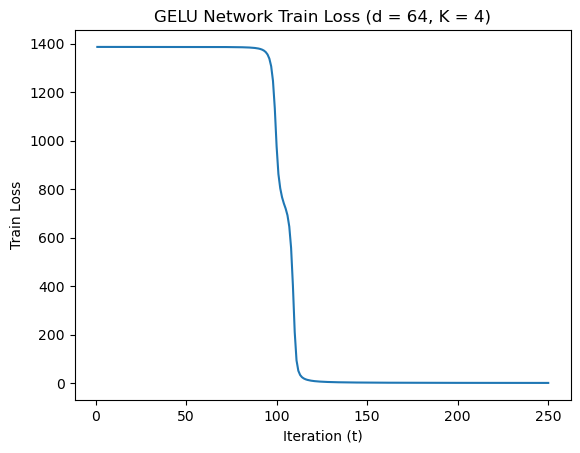

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:31:47,552 - INFO - Finish Epoch 1
2026-01-02 19:31:47,554 - INFO - Train loss: 1386.2968425750732, train accuracy: 20.5
2026-01-02 19:31:47,570 - INFO - Val loss: 1386.296142578125, val accuracy: 21.3
2026-01-02 19:31:47,609 - INFO - Finish Epoch 2
2026-01-02 19:31:47,610 - INFO - Train loss: 1386.29580783844, train accuracy: 22.1
2026-01-02 19:31:47,626 - INFO - Val loss: 1386.2950744628906, val accuracy: 23.0
  1%|          | 2/250 [00:00<00:13, 17.76it/s]2026-01-02 19:31:47,666 - INFO - Finish Epoch 3
2026-01-02 19:31:47,667 - INFO - Train loss: 1386.2947473526, train accuracy: 23.8
2026-01-02 19:31:47,683 - INFO - Val loss: 1386.2940139770508, val accuracy: 25.5
2026-01-02 19:31:47,721 - INFO - Finish Epoch 4
2026-01-02 19:31:47,723 - INFO - Train loss: 1386.293667793274, train accuracy: 26.2
2026-01-02 19:31:47,739 - INFO - Val loss: 1386.2929496765137, val accuracy: 28.1
  2%|▏         | 4/250 [00:00<00:13, 17.73it/s]2026-01-02

 27%|██▋       | 68/250 [00:03<00:10, 17.59it/s]2026-01-02 19:31:51,414 - INFO - Finish Epoch 69
2026-01-02 19:31:51,415 - INFO - Train loss: 1385.9959964752197, train accuracy: 99.6
2026-01-02 19:31:51,432 - INFO - Val loss: 1385.981143951416, val accuracy: 99.6
2026-01-02 19:31:51,470 - INFO - Finish Epoch 70
2026-01-02 19:31:51,472 - INFO - Train loss: 1385.973684310913, train accuracy: 99.6
2026-01-02 19:31:51,488 - INFO - Val loss: 1385.9573001861572, val accuracy: 99.6
 28%|██▊       | 70/250 [00:03<00:10, 17.55it/s]2026-01-02 19:31:51,530 - INFO - Finish Epoch 71
2026-01-02 19:31:51,531 - INFO - Train loss: 1385.949083328247, train accuracy: 99.6
2026-01-02 19:31:51,548 - INFO - Val loss: 1385.931001663208, val accuracy: 99.6
2026-01-02 19:31:51,586 - INFO - Finish Epoch 72
2026-01-02 19:31:51,587 - INFO - Train loss: 1385.9219245910645, train accuracy: 99.6
2026-01-02 19:31:51,604 - INFO - Val loss: 1385.9019012451172, val accuracy: 99.6
 29%|██▉       | 72/250 [00:04<00:10, 17

 54%|█████▍    | 136/250 [00:07<00:08, 13.86it/s]2026-01-02 19:31:55,377 - INFO - Finish Epoch 137
2026-01-02 19:31:55,378 - INFO - Train loss: 4.850334249436855, train accuracy: 100.0
2026-01-02 19:31:55,395 - INFO - Val loss: 4.6404592506587505, val accuracy: 100.0
2026-01-02 19:31:55,433 - INFO - Finish Epoch 138
2026-01-02 19:31:55,434 - INFO - Train loss: 4.639764808118343, train accuracy: 100.0
2026-01-02 19:31:55,451 - INFO - Val loss: 4.444687031209469, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:07, 14.79it/s]2026-01-02 19:31:55,490 - INFO - Finish Epoch 139
2026-01-02 19:31:55,491 - INFO - Train loss: 4.445079758763313, train accuracy: 100.0
2026-01-02 19:31:55,507 - INFO - Val loss: 4.263307988643646, val accuracy: 100.0
2026-01-02 19:31:55,545 - INFO - Finish Epoch 140
2026-01-02 19:31:55,546 - INFO - Train loss: 4.264600640162826, train accuracy: 100.0
2026-01-02 19:31:55,563 - INFO - Val loss: 4.094833888113499, val accuracy: 100.0
 56%|█████▌    | 140/250 [00:

2026-01-02 19:31:57,251 - INFO - Val loss: 1.7717845533043146, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.82it/s]2026-01-02 19:31:57,291 - INFO - Finish Epoch 171
2026-01-02 19:31:57,292 - INFO - Train loss: 1.7758466005325317, train accuracy: 100.0
2026-01-02 19:31:57,308 - INFO - Val loss: 1.7362509910017252, val accuracy: 100.0
2026-01-02 19:31:57,346 - INFO - Finish Epoch 172
2026-01-02 19:31:57,347 - INFO - Train loss: 1.740245757624507, train accuracy: 100.0
2026-01-02 19:31:57,364 - INFO - Val loss: 1.7019702224060893, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.81it/s]2026-01-02 19:31:57,403 - INFO - Finish Epoch 173
2026-01-02 19:31:57,404 - INFO - Train loss: 1.7058973656967282, train accuracy: 100.0
2026-01-02 19:31:57,420 - INFO - Val loss: 1.6688818242400885, val accuracy: 100.0
2026-01-02 19:31:57,458 - INFO - Finish Epoch 174
2026-01-02 19:31:57,459 - INFO - Train loss: 1.6727445051074028, train accuracy: 100.0
2026-01-02 19:31:57,475

2026-01-02 19:31:59,158 - INFO - Train loss: 1.03402461996302, train accuracy: 100.0
2026-01-02 19:31:59,174 - INFO - Val loss: 1.0181030994281173, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.58it/s]2026-01-02 19:31:59,214 - INFO - Finish Epoch 205
2026-01-02 19:31:59,215 - INFO - Train loss: 1.0203745609614998, train accuracy: 100.0
2026-01-02 19:31:59,231 - INFO - Val loss: 1.004807030549273, val accuracy: 100.0
2026-01-02 19:31:59,270 - INFO - Finish Epoch 206
2026-01-02 19:31:59,271 - INFO - Train loss: 1.0070450534112751, train accuracy: 100.0
2026-01-02 19:31:59,288 - INFO - Val loss: 0.9918194152414799, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.59it/s]2026-01-02 19:31:59,327 - INFO - Finish Epoch 207
2026-01-02 19:31:59,328 - INFO - Train loss: 0.994017171440646, train accuracy: 100.0
2026-01-02 19:31:59,345 - INFO - Val loss: 0.9791269483976066, val accuracy: 100.0
2026-01-02 19:31:59,383 - INFO - Finish Epoch 208
2026-01-02 19:31:59,385 - 

2026-01-02 19:32:01,101 - INFO - Finish Epoch 238
2026-01-02 19:32:01,102 - INFO - Train loss: 0.701101855840534, train accuracy: 100.0
2026-01-02 19:32:01,119 - INFO - Val loss: 0.6928810456302017, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.43it/s]2026-01-02 19:32:01,159 - INFO - Finish Epoch 239
2026-01-02 19:32:01,160 - INFO - Train loss: 0.6942562505137175, train accuracy: 100.0
2026-01-02 19:32:01,177 - INFO - Val loss: 0.6861687812488526, val accuracy: 100.0
2026-01-02 19:32:01,216 - INFO - Finish Epoch 240
2026-01-02 19:32:01,217 - INFO - Train loss: 0.6875243396498263, train accuracy: 100.0
2026-01-02 19:32:01,234 - INFO - Val loss: 0.6795740413945168, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.39it/s]2026-01-02 19:32:01,275 - INFO - Finish Epoch 241
2026-01-02 19:32:01,276 - INFO - Train loss: 0.680910759489052, train accuracy: 100.0
2026-01-02 19:32:01,293 - INFO - Val loss: 0.6730935557279736, val accuracy: 100.0
2026-01-02 19:32:01,332 

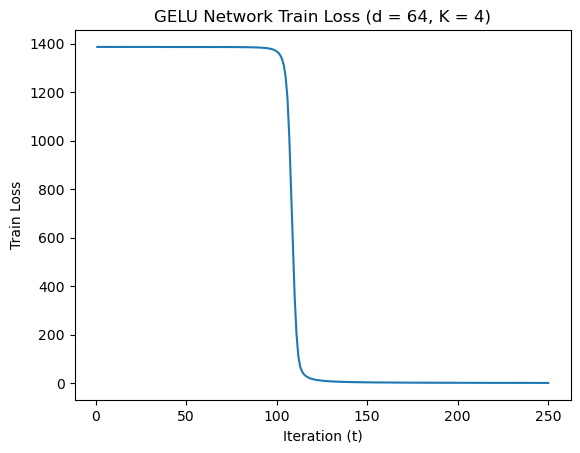

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:32:02,132 - INFO - Finish Epoch 1
2026-01-02 19:32:02,133 - INFO - Train loss: 1386.2942209243774, train accuracy: 27.1
2026-01-02 19:32:02,150 - INFO - Val loss: 1386.29349899292, val accuracy: 29.2
2026-01-02 19:32:02,188 - INFO - Finish Epoch 2
2026-01-02 19:32:02,190 - INFO - Train loss: 1386.2931213378906, train accuracy: 29.7
2026-01-02 19:32:02,206 - INFO - Val loss: 1386.292366027832, val accuracy: 31.6
  1%|          | 2/250 [00:00<00:13, 17.72it/s]2026-01-02 19:32:02,246 - INFO - Finish Epoch 3
2026-01-02 19:32:02,247 - INFO - Train loss: 1386.292007446289, train accuracy: 32.0
2026-01-02 19:32:02,264 - INFO - Val loss: 1386.2912282943726, val accuracy: 33.2
2026-01-02 19:32:02,303 - INFO - Finish Epoch 4
2026-01-02 19:32:02,304 - INFO - Train loss: 1386.2908391952515, train accuracy: 33.5
2026-01-02 19:32:02,321 - INFO - Val loss: 1386.2901020050049, val accuracy: 34.9
  2%|▏         | 4/250 [00:00<00:14, 17.56it/s]2026-01

 27%|██▋       | 68/250 [00:03<00:10, 17.57it/s]2026-01-02 19:32:06,010 - INFO - Finish Epoch 69
2026-01-02 19:32:06,011 - INFO - Train loss: 1385.8792972564697, train accuracy: 99.7
2026-01-02 19:32:06,028 - INFO - Val loss: 1385.8544960021973, val accuracy: 99.8
2026-01-02 19:32:06,067 - INFO - Finish Epoch 70
2026-01-02 19:32:06,068 - INFO - Train loss: 1385.8432445526123, train accuracy: 99.7
2026-01-02 19:32:06,085 - INFO - Val loss: 1385.8154125213623, val accuracy: 99.8
 28%|██▊       | 70/250 [00:03<00:10, 17.57it/s]2026-01-02 19:32:06,124 - INFO - Finish Epoch 71
2026-01-02 19:32:06,125 - INFO - Train loss: 1385.8028497695923, train accuracy: 99.7
2026-01-02 19:32:06,142 - INFO - Val loss: 1385.771484375, val accuracy: 99.8
2026-01-02 19:32:06,181 - INFO - Finish Epoch 72
2026-01-02 19:32:06,182 - INFO - Train loss: 1385.7573947906494, train accuracy: 99.7
2026-01-02 19:32:06,198 - INFO - Val loss: 1385.7218742370605, val accuracy: 99.7
 29%|██▉       | 72/250 [00:04<00:10, 17

 54%|█████▍    | 136/250 [00:07<00:06, 17.69it/s]2026-01-02 19:32:09,884 - INFO - Finish Epoch 137
2026-01-02 19:32:09,886 - INFO - Train loss: 3.420007783919573, train accuracy: 100.0
2026-01-02 19:32:09,902 - INFO - Val loss: 3.294102221727371, val accuracy: 100.0
2026-01-02 19:32:09,940 - INFO - Finish Epoch 138
2026-01-02 19:32:09,941 - INFO - Train loss: 3.2826023176312447, train accuracy: 100.0
2026-01-02 19:32:09,958 - INFO - Val loss: 3.165215738117695, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.71it/s]2026-01-02 19:32:09,997 - INFO - Finish Epoch 139
2026-01-02 19:32:09,998 - INFO - Train loss: 3.154885683208704, train accuracy: 100.0
2026-01-02 19:32:10,014 - INFO - Val loss: 3.045192677527666, val accuracy: 100.0
2026-01-02 19:32:10,052 - INFO - Finish Epoch 140
2026-01-02 19:32:10,053 - INFO - Train loss: 3.0358973033726215, train accuracy: 100.0
2026-01-02 19:32:10,070 - INFO - Val loss: 2.933179710060358, val accuracy: 100.0
 56%|█████▌    | 140/250 [00

2026-01-02 19:32:11,762 - INFO - Val loss: 1.3313874434679747, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.77it/s]2026-01-02 19:32:11,802 - INFO - Finish Epoch 171
2026-01-02 19:32:11,803 - INFO - Train loss: 1.3307821806520224, train accuracy: 100.0
2026-01-02 19:32:11,819 - INFO - Val loss: 1.3059499897062778, val accuracy: 100.0
2026-01-02 19:32:11,858 - INFO - Finish Epoch 172
2026-01-02 19:32:11,859 - INFO - Train loss: 1.3053947035223246, train accuracy: 100.0
2026-01-02 19:32:11,876 - INFO - Val loss: 1.2813805807381868, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.71it/s]2026-01-02 19:32:11,915 - INFO - Finish Epoch 173
2026-01-02 19:32:11,916 - INFO - Train loss: 1.2808760683983564, train accuracy: 100.0
2026-01-02 19:32:11,933 - INFO - Val loss: 1.25763357616961, val accuracy: 100.0
2026-01-02 19:32:11,972 - INFO - Finish Epoch 174
2026-01-02 19:32:11,973 - INFO - Train loss: 1.257168436422944, train accuracy: 100.0
2026-01-02 19:32:11,989 -

2026-01-02 19:32:13,682 - INFO - Train loss: 0.7942952318117023, train accuracy: 100.0
2026-01-02 19:32:13,699 - INFO - Val loss: 0.7841748055070639, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.43it/s]2026-01-02 19:32:13,738 - INFO - Finish Epoch 205
2026-01-02 19:32:13,739 - INFO - Train loss: 0.7842573542147875, train accuracy: 100.0
2026-01-02 19:32:13,756 - INFO - Val loss: 0.7743591880425811, val accuracy: 100.0
2026-01-02 19:32:13,794 - INFO - Finish Epoch 206
2026-01-02 19:32:13,795 - INFO - Train loss: 0.7744507193565369, train accuracy: 100.0
2026-01-02 19:32:13,812 - INFO - Val loss: 0.7647674158215523, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.52it/s]2026-01-02 19:32:13,850 - INFO - Finish Epoch 207
2026-01-02 19:32:13,852 - INFO - Train loss: 0.764856013469398, train accuracy: 100.0
2026-01-02 19:32:13,868 - INFO - Val loss: 0.755383207462728, val accuracy: 100.0
2026-01-02 19:32:13,906 - INFO - Finish Epoch 208
2026-01-02 19:32:13,907 

2026-01-02 19:32:15,626 - INFO - Finish Epoch 238
2026-01-02 19:32:15,627 - INFO - Train loss: 0.5473673394881189, train accuracy: 100.0
2026-01-02 19:32:15,644 - INFO - Val loss: 0.542093378957361, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.65it/s]2026-01-02 19:32:15,682 - INFO - Finish Epoch 239
2026-01-02 19:32:15,684 - INFO - Train loss: 0.5422383164986968, train accuracy: 100.0
2026-01-02 19:32:15,700 - INFO - Val loss: 0.5370512176305056, val accuracy: 100.0
2026-01-02 19:32:15,738 - INFO - Finish Epoch 240
2026-01-02 19:32:15,739 - INFO - Train loss: 0.5371932592242956, train accuracy: 100.0
2026-01-02 19:32:15,756 - INFO - Val loss: 0.5320881549268961, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.69it/s]2026-01-02 19:32:15,795 - INFO - Finish Epoch 241
2026-01-02 19:32:15,796 - INFO - Train loss: 0.532234693877399, train accuracy: 100.0
2026-01-02 19:32:15,813 - INFO - Val loss: 0.5272134724073112, val accuracy: 100.0
2026-01-02 19:32:15,850 

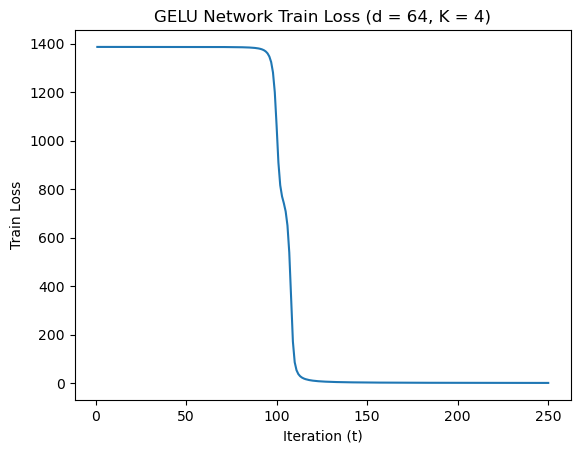

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:32:16,634 - INFO - Finish Epoch 1
2026-01-02 19:32:16,635 - INFO - Train loss: 1386.293734550476, train accuracy: 26.2
2026-01-02 19:32:16,653 - INFO - Val loss: 1386.2930364608765, val accuracy: 27.6
2026-01-02 19:32:16,691 - INFO - Finish Epoch 2
2026-01-02 19:32:16,693 - INFO - Train loss: 1386.2926445007324, train accuracy: 28.2
2026-01-02 19:32:16,709 - INFO - Val loss: 1386.2919263839722, val accuracy: 29.8
  1%|          | 2/250 [00:00<00:14, 17.41it/s]2026-01-02 19:32:16,749 - INFO - Finish Epoch 3
2026-01-02 19:32:16,750 - INFO - Train loss: 1386.2915496826172, train accuracy: 31.0
2026-01-02 19:32:16,767 - INFO - Val loss: 1386.2908086776733, val accuracy: 32.4
2026-01-02 19:32:16,805 - INFO - Finish Epoch 4
2026-01-02 19:32:16,806 - INFO - Train loss: 1386.290446281433, train accuracy: 33.1
2026-01-02 19:32:16,823 - INFO - Val loss: 1386.2896976470947, val accuracy: 34.4
  2%|▏         | 4/250 [00:00<00:14, 17.55it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.74it/s]2026-01-02 19:32:20,471 - INFO - Finish Epoch 69
2026-01-02 19:32:20,472 - INFO - Train loss: 1385.8098888397217, train accuracy: 98.4
2026-01-02 19:32:20,489 - INFO - Val loss: 1385.7767534255981, val accuracy: 98.2
2026-01-02 19:32:20,527 - INFO - Finish Epoch 70
2026-01-02 19:32:20,528 - INFO - Train loss: 1385.7613506317139, train accuracy: 98.2
2026-01-02 19:32:20,545 - INFO - Val loss: 1385.7233352661133, val accuracy: 98.2
 28%|██▊       | 70/250 [00:03<00:10, 17.73it/s]2026-01-02 19:32:20,584 - INFO - Finish Epoch 71
2026-01-02 19:32:20,585 - INFO - Train loss: 1385.7057600021362, train accuracy: 98.2
2026-01-02 19:32:20,602 - INFO - Val loss: 1385.661964416504, val accuracy: 98.1
2026-01-02 19:32:20,640 - INFO - Finish Epoch 72
2026-01-02 19:32:20,641 - INFO - Train loss: 1385.6417751312256, train accuracy: 98.1
2026-01-02 19:32:20,658 - INFO - Val loss: 1385.5909786224365, val accuracy: 98.0
 29%|██▉       | 72/250 [00:04<00:10,

 54%|█████▍    | 136/250 [00:07<00:06, 17.75it/s]2026-01-02 19:32:24,320 - INFO - Finish Epoch 137
2026-01-02 19:32:24,321 - INFO - Train loss: 6.138617038726807, train accuracy: 100.0
2026-01-02 19:32:24,338 - INFO - Val loss: 5.72706650942564, val accuracy: 100.0
2026-01-02 19:32:24,376 - INFO - Finish Epoch 138
2026-01-02 19:32:24,377 - INFO - Train loss: 5.78240779042244, train accuracy: 100.0
2026-01-02 19:32:24,394 - INFO - Val loss: 5.410269349813461, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.75it/s]2026-01-02 19:32:24,433 - INFO - Finish Epoch 139
2026-01-02 19:32:24,434 - INFO - Train loss: 5.461553197354078, train accuracy: 100.0
2026-01-02 19:32:24,451 - INFO - Val loss: 5.123543601483107, val accuracy: 100.0
2026-01-02 19:32:24,489 - INFO - Finish Epoch 140
2026-01-02 19:32:24,490 - INFO - Train loss: 5.171187575906515, train accuracy: 100.0
2026-01-02 19:32:24,507 - INFO - Val loss: 4.862921329215169, val accuracy: 100.0
 56%|█████▌    | 140/250 [00:07<

2026-01-02 19:32:26,206 - INFO - Val loss: 1.7745057460851967, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.63it/s]2026-01-02 19:32:26,245 - INFO - Finish Epoch 171
2026-01-02 19:32:26,246 - INFO - Train loss: 1.7846025619655848, train accuracy: 100.0
2026-01-02 19:32:26,263 - INFO - Val loss: 1.734016157221049, val accuracy: 100.0
2026-01-02 19:32:26,302 - INFO - Finish Epoch 172
2026-01-02 19:32:26,303 - INFO - Train loss: 1.7437574211508036, train accuracy: 100.0
2026-01-02 19:32:26,319 - INFO - Val loss: 1.6951394621282816, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.61it/s]2026-01-02 19:32:26,359 - INFO - Finish Epoch 173
2026-01-02 19:32:26,360 - INFO - Train loss: 1.7045449810102582, train accuracy: 100.0
2026-01-02 19:32:26,376 - INFO - Val loss: 1.6577828163281083, val accuracy: 100.0
2026-01-02 19:32:26,414 - INFO - Finish Epoch 174
2026-01-02 19:32:26,415 - INFO - Train loss: 1.6668623676523566, train accuracy: 100.0
2026-01-02 19:32:26,432

2026-01-02 19:32:28,109 - INFO - Train loss: 0.9748742810916156, train accuracy: 100.0
2026-01-02 19:32:28,126 - INFO - Val loss: 0.9570113241206855, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.70it/s]2026-01-02 19:32:28,165 - INFO - Finish Epoch 205
2026-01-02 19:32:28,166 - INFO - Train loss: 0.9607928483746946, train accuracy: 100.0
2026-01-02 19:32:28,182 - INFO - Val loss: 0.9433718589134514, val accuracy: 100.0
2026-01-02 19:32:28,220 - INFO - Finish Epoch 206
2026-01-02 19:32:28,221 - INFO - Train loss: 0.9470668302383274, train accuracy: 100.0
2026-01-02 19:32:28,237 - INFO - Val loss: 0.9300732840783894, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.77it/s]2026-01-02 19:32:28,276 - INFO - Finish Epoch 207
2026-01-02 19:32:28,277 - INFO - Train loss: 0.9336848868988454, train accuracy: 100.0
2026-01-02 19:32:28,297 - INFO - Val loss: 0.9171042500529438, val accuracy: 100.0
2026-01-02 19:32:28,336 - INFO - Finish Epoch 208
2026-01-02 19:32:28,33

2026-01-02 19:32:30,045 - INFO - Finish Epoch 238
2026-01-02 19:32:30,046 - INFO - Train loss: 0.6400208864361048, train accuracy: 100.0
2026-01-02 19:32:30,062 - INFO - Val loss: 0.6314187860116363, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.64it/s]2026-01-02 19:32:30,102 - INFO - Finish Epoch 239
2026-01-02 19:32:30,103 - INFO - Train loss: 0.6333262680564076, train accuracy: 100.0
2026-01-02 19:32:30,120 - INFO - Val loss: 0.6248809576500207, val accuracy: 100.0
2026-01-02 19:32:30,158 - INFO - Finish Epoch 240
2026-01-02 19:32:30,159 - INFO - Train loss: 0.6267511665355414, train accuracy: 100.0
2026-01-02 19:32:30,176 - INFO - Val loss: 0.6184586546150967, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.64it/s]2026-01-02 19:32:30,215 - INFO - Finish Epoch 241
2026-01-02 19:32:30,216 - INFO - Train loss: 0.6203014714410529, train accuracy: 100.0
2026-01-02 19:32:30,233 - INFO - Val loss: 0.6121566515648738, val accuracy: 100.0
2026-01-02 19:32:30,27

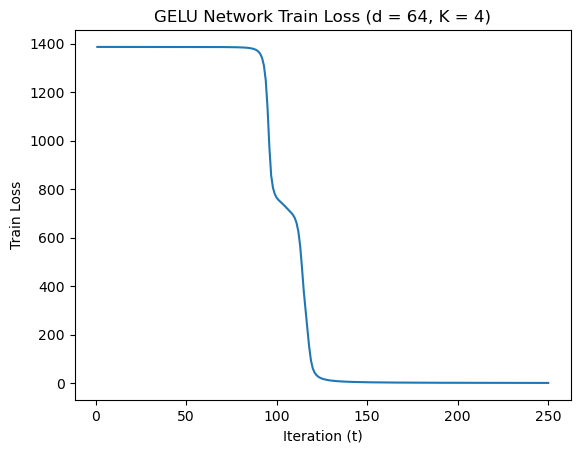

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:32:31,062 - INFO - Finish Epoch 1
2026-01-02 19:32:31,063 - INFO - Train loss: 1386.2979955673218, train accuracy: 19.4
2026-01-02 19:32:31,080 - INFO - Val loss: 1386.2972660064697, val accuracy: 20.2
2026-01-02 19:32:31,118 - INFO - Finish Epoch 2
2026-01-02 19:32:31,119 - INFO - Train loss: 1386.2969341278076, train accuracy: 20.9
2026-01-02 19:32:31,136 - INFO - Val loss: 1386.2961750030518, val accuracy: 22.1
  1%|          | 2/250 [00:00<00:14, 17.49it/s]2026-01-02 19:32:31,176 - INFO - Finish Epoch 3
2026-01-02 19:32:31,177 - INFO - Train loss: 1386.2958354949951, train accuracy: 22.7
2026-01-02 19:32:31,194 - INFO - Val loss: 1386.295087814331, val accuracy: 23.8
2026-01-02 19:32:31,233 - INFO - Finish Epoch 4
2026-01-02 19:32:31,234 - INFO - Train loss: 1386.2947330474854, train accuracy: 24.6
2026-01-02 19:32:31,250 - INFO - Val loss: 1386.2939720153809, val accuracy: 25.4
  2%|▏         | 4/250 [00:00<00:14, 17.52it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.52it/s]2026-01-02 19:32:35,038 - INFO - Finish Epoch 69
2026-01-02 19:32:35,039 - INFO - Train loss: 1385.9864702224731, train accuracy: 99.5
2026-01-02 19:32:35,056 - INFO - Val loss: 1385.9710969924927, val accuracy: 99.5
2026-01-02 19:32:35,094 - INFO - Finish Epoch 70
2026-01-02 19:32:35,095 - INFO - Train loss: 1385.9625120162964, train accuracy: 99.5
2026-01-02 19:32:35,116 - INFO - Val loss: 1385.9454364776611, val accuracy: 99.5
 28%|██▊       | 70/250 [00:04<00:10, 17.41it/s]2026-01-02 19:32:35,156 - INFO - Finish Epoch 71
2026-01-02 19:32:35,157 - INFO - Train loss: 1385.93594455719, train accuracy: 99.5
2026-01-02 19:32:35,174 - INFO - Val loss: 1385.917010307312, val accuracy: 99.5
2026-01-02 19:32:35,213 - INFO - Finish Epoch 72
2026-01-02 19:32:35,214 - INFO - Train loss: 1385.9064483642578, train accuracy: 99.5
2026-01-02 19:32:35,231 - INFO - Val loss: 1385.885362625122, val accuracy: 99.5
 29%|██▉       | 72/250 [00:04<00:10, 17

 54%|█████▍    | 136/250 [00:07<00:06, 17.74it/s]2026-01-02 19:32:38,882 - INFO - Finish Epoch 137
2026-01-02 19:32:38,883 - INFO - Train loss: 3.196263659745455, train accuracy: 100.0
2026-01-02 19:32:38,900 - INFO - Val loss: 3.0512376371771097, val accuracy: 100.0
2026-01-02 19:32:38,938 - INFO - Finish Epoch 138
2026-01-02 19:32:38,939 - INFO - Train loss: 3.017444947734475, train accuracy: 100.0
2026-01-02 19:32:38,956 - INFO - Val loss: 2.8866514787077904, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.71it/s]2026-01-02 19:32:38,994 - INFO - Finish Epoch 139
2026-01-02 19:32:38,996 - INFO - Train loss: 2.8563507348299026, train accuracy: 100.0
2026-01-02 19:32:39,012 - INFO - Val loss: 2.7378197591751814, val accuracy: 100.0
2026-01-02 19:32:39,050 - INFO - Finish Epoch 140
2026-01-02 19:32:39,051 - INFO - Train loss: 2.710523074492812, train accuracy: 100.0
2026-01-02 19:32:39,067 - INFO - Val loss: 2.602624583989382, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:32:40,754 - INFO - Val loss: 0.9956651106476784, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.76it/s]2026-01-02 19:32:40,792 - INFO - Finish Epoch 171
2026-01-02 19:32:40,794 - INFO - Train loss: 0.9920583534985781, train accuracy: 100.0
2026-01-02 19:32:40,810 - INFO - Val loss: 0.9742873776704073, val accuracy: 100.0
2026-01-02 19:32:40,847 - INFO - Finish Epoch 172
2026-01-02 19:32:40,849 - INFO - Train loss: 0.970839318819344, train accuracy: 100.0
2026-01-02 19:32:40,865 - INFO - Val loss: 0.9537429818883538, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.83it/s]2026-01-02 19:32:40,904 - INFO - Finish Epoch 173
2026-01-02 19:32:40,905 - INFO - Train loss: 0.9504390731453896, train accuracy: 100.0
2026-01-02 19:32:40,921 - INFO - Val loss: 0.9339807741343975, val accuracy: 100.0
2026-01-02 19:32:40,959 - INFO - Finish Epoch 174
2026-01-02 19:32:40,960 - INFO - Train loss: 0.9308148548007011, train accuracy: 100.0
2026-01-02 19:32:40,977

2026-01-02 19:32:42,651 - INFO - Train loss: 0.5651707062497735, train accuracy: 100.0
2026-01-02 19:32:42,667 - INFO - Val loss: 0.5587073974311352, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.76it/s]2026-01-02 19:32:42,706 - INFO - Finish Epoch 205
2026-01-02 19:32:42,707 - INFO - Train loss: 0.5575952180661261, train accuracy: 100.0
2026-01-02 19:32:42,723 - INFO - Val loss: 0.5512877958826721, val accuracy: 100.0
2026-01-02 19:32:42,762 - INFO - Finish Epoch 206
2026-01-02 19:32:42,763 - INFO - Train loss: 0.5502030095085502, train accuracy: 100.0
2026-01-02 19:32:42,780 - INFO - Val loss: 0.5440467223525047, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.75it/s]2026-01-02 19:32:42,820 - INFO - Finish Epoch 207
2026-01-02 19:32:42,821 - INFO - Train loss: 0.5429893364198506, train accuracy: 100.0
2026-01-02 19:32:42,837 - INFO - Val loss: 0.5369768403470516, val accuracy: 100.0
2026-01-02 19:32:42,875 - INFO - Finish Epoch 208
2026-01-02 19:32:42,87

2026-01-02 19:32:44,551 - INFO - Val loss: 0.383226178586483, val accuracy: 100.0
2026-01-02 19:32:44,589 - INFO - Finish Epoch 238
2026-01-02 19:32:44,590 - INFO - Train loss: 0.3827093755826354, train accuracy: 100.0
2026-01-02 19:32:44,607 - INFO - Val loss: 0.37950981268659234, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.49it/s]2026-01-02 19:32:44,646 - INFO - Finish Epoch 239
2026-01-02 19:32:44,647 - INFO - Train loss: 0.3790018227882683, train accuracy: 100.0
2026-01-02 19:32:44,664 - INFO - Val loss: 0.37585773784667253, val accuracy: 100.0
2026-01-02 19:32:44,701 - INFO - Finish Epoch 240
2026-01-02 19:32:44,702 - INFO - Train loss: 0.3753589284606278, train accuracy: 100.0
2026-01-02 19:32:44,719 - INFO - Val loss: 0.372271271655336, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.60it/s]2026-01-02 19:32:44,758 - INFO - Finish Epoch 241
2026-01-02 19:32:44,759 - INFO - Train loss: 0.3717833091504872, train accuracy: 100.0
2026-01-02 19:32:44,77

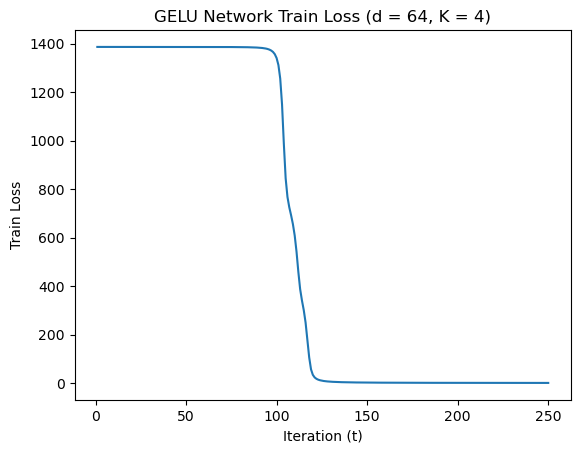

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:32:45,609 - INFO - Finish Epoch 1
2026-01-02 19:32:45,611 - INFO - Train loss: 1386.292067527771, train accuracy: 29.6
2026-01-02 19:32:45,628 - INFO - Val loss: 1386.2913303375244, val accuracy: 31.1
2026-01-02 19:32:45,666 - INFO - Finish Epoch 2
2026-01-02 19:32:45,667 - INFO - Train loss: 1386.2910070419312, train accuracy: 31.8
2026-01-02 19:32:45,684 - INFO - Val loss: 1386.2902545928955, val accuracy: 33.3
  1%|          | 2/250 [00:00<00:14, 17.66it/s]2026-01-02 19:32:45,724 - INFO - Finish Epoch 3
2026-01-02 19:32:45,725 - INFO - Train loss: 1386.2898969650269, train accuracy: 34.1
2026-01-02 19:32:45,741 - INFO - Val loss: 1386.289113998413, val accuracy: 35.4
2026-01-02 19:32:45,780 - INFO - Finish Epoch 4
2026-01-02 19:32:45,781 - INFO - Train loss: 1386.2887563705444, train accuracy: 36.0
2026-01-02 19:32:45,798 - INFO - Val loss: 1386.2879848480225, val accuracy: 38.3
  2%|▏         | 4/250 [00:00<00:13, 17.60it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.51it/s]2026-01-02 19:32:49,529 - INFO - Finish Epoch 69
2026-01-02 19:32:49,530 - INFO - Train loss: 1385.7440547943115, train accuracy: 95.7
2026-01-02 19:32:49,546 - INFO - Val loss: 1385.7031106948853, val accuracy: 95.8
2026-01-02 19:32:49,585 - INFO - Finish Epoch 70
2026-01-02 19:32:49,587 - INFO - Train loss: 1385.6867942810059, train accuracy: 95.2
2026-01-02 19:32:49,604 - INFO - Val loss: 1385.6397075653076, val accuracy: 95.2
 28%|██▊       | 70/250 [00:04<00:10, 17.49it/s]2026-01-02 19:32:49,644 - INFO - Finish Epoch 71
2026-01-02 19:32:49,645 - INFO - Train loss: 1385.620964050293, train accuracy: 94.7
2026-01-02 19:32:49,662 - INFO - Val loss: 1385.5665016174316, val accuracy: 94.8
2026-01-02 19:32:49,700 - INFO - Finish Epoch 72
2026-01-02 19:32:49,701 - INFO - Train loss: 1385.5448246002197, train accuracy: 93.5
2026-01-02 19:32:49,718 - INFO - Val loss: 1385.4814758300781, val accuracy: 93.4
 29%|██▉       | 72/250 [00:04<00:10,

 54%|█████▍    | 136/250 [00:07<00:06, 17.55it/s]2026-01-02 19:32:53,421 - INFO - Finish Epoch 137
2026-01-02 19:32:53,422 - INFO - Train loss: 3.1982709653675556, train accuracy: 100.0
2026-01-02 19:32:53,439 - INFO - Val loss: 3.075655475258827, val accuracy: 100.0
2026-01-02 19:32:53,477 - INFO - Finish Epoch 138
2026-01-02 19:32:53,478 - INFO - Train loss: 3.0525088980793953, train accuracy: 100.0
2026-01-02 19:32:53,495 - INFO - Val loss: 2.9392972495406866, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.60it/s]2026-01-02 19:32:53,534 - INFO - Finish Epoch 139
2026-01-02 19:32:53,535 - INFO - Train loss: 2.918223664164543, train accuracy: 100.0
2026-01-02 19:32:53,552 - INFO - Val loss: 2.8134012538939714, val accuracy: 100.0
2026-01-02 19:32:53,590 - INFO - Finish Epoch 140
2026-01-02 19:32:53,591 - INFO - Train loss: 2.794156450778246, train accuracy: 100.0
2026-01-02 19:32:53,608 - INFO - Val loss: 2.696853954344988, val accuracy: 100.0
 56%|█████▌    | 140/250 [

2026-01-02 19:32:55,310 - INFO - Val loss: 1.1322841001674533, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.66it/s]2026-01-02 19:32:55,349 - INFO - Finish Epoch 171
2026-01-02 19:32:55,350 - INFO - Train loss: 1.1292879888787866, train accuracy: 100.0
2026-01-02 19:32:55,367 - INFO - Val loss: 1.1090478468686342, val accuracy: 100.0
2026-01-02 19:32:55,406 - INFO - Finish Epoch 172
2026-01-02 19:32:55,408 - INFO - Train loss: 1.1061730664223433, train accuracy: 100.0
2026-01-02 19:32:55,424 - INFO - Val loss: 1.0866528432816267, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.63it/s]2026-01-02 19:32:55,463 - INFO - Finish Epoch 173
2026-01-02 19:32:55,464 - INFO - Train loss: 1.0838943785056472, train accuracy: 100.0
2026-01-02 19:32:55,481 - INFO - Val loss: 1.0650586625561118, val accuracy: 100.0
2026-01-02 19:32:55,519 - INFO - Finish Epoch 174
2026-01-02 19:32:55,520 - INFO - Train loss: 1.0624075653031468, train accuracy: 100.0
2026-01-02 19:32:55,53

2026-01-02 19:32:57,232 - INFO - Train loss: 0.652455038856715, train accuracy: 100.0
2026-01-02 19:32:57,249 - INFO - Val loss: 0.6447438942268491, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.67it/s]2026-01-02 19:32:57,288 - INFO - Finish Epoch 205
2026-01-02 19:32:57,289 - INFO - Train loss: 0.6437750482000411, train accuracy: 100.0
2026-01-02 19:32:57,306 - INFO - Val loss: 0.6362441410310566, val accuracy: 100.0
2026-01-02 19:32:57,344 - INFO - Finish Epoch 206
2026-01-02 19:32:57,345 - INFO - Train loss: 0.6353042917326093, train accuracy: 100.0
2026-01-02 19:32:57,362 - INFO - Val loss: 0.6279478473588824, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.67it/s]2026-01-02 19:32:57,401 - INFO - Finish Epoch 207
2026-01-02 19:32:57,402 - INFO - Train loss: 0.6270322576165199, train accuracy: 100.0
2026-01-02 19:32:57,419 - INFO - Val loss: 0.6198436324484646, val accuracy: 100.0
2026-01-02 19:32:57,457 - INFO - Finish Epoch 208
2026-01-02 19:32:57,458

2026-01-02 19:32:59,158 - INFO - Finish Epoch 238
2026-01-02 19:32:59,159 - INFO - Train loss: 0.44185246527194977, train accuracy: 100.0
2026-01-02 19:32:59,176 - INFO - Val loss: 0.4379888945259154, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.65it/s]2026-01-02 19:32:59,215 - INFO - Finish Epoch 239
2026-01-02 19:32:59,216 - INFO - Train loss: 0.4375420433934778, train accuracy: 100.0
2026-01-02 19:32:59,233 - INFO - Val loss: 0.433744125533849, val accuracy: 100.0
2026-01-02 19:32:59,271 - INFO - Finish Epoch 240
2026-01-02 19:32:59,272 - INFO - Train loss: 0.4333101217634976, train accuracy: 100.0
2026-01-02 19:32:59,289 - INFO - Val loss: 0.4295769049786031, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.66it/s]2026-01-02 19:32:59,328 - INFO - Finish Epoch 241
2026-01-02 19:32:59,329 - INFO - Train loss: 0.4291472991462797, train accuracy: 100.0
2026-01-02 19:32:59,346 - INFO - Val loss: 0.4254798539914191, val accuracy: 100.0
2026-01-02 19:32:59,38

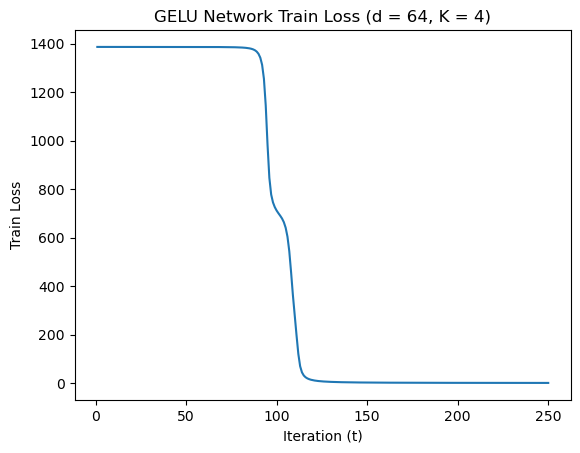

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:33:00,180 - INFO - Finish Epoch 1
2026-01-02 19:33:00,181 - INFO - Train loss: 1386.2958393096924, train accuracy: 22.2
2026-01-02 19:33:00,198 - INFO - Val loss: 1386.2952251434326, val accuracy: 23.3
2026-01-02 19:33:00,237 - INFO - Finish Epoch 2
2026-01-02 19:33:00,238 - INFO - Train loss: 1386.2948818206787, train accuracy: 24.5
2026-01-02 19:33:00,255 - INFO - Val loss: 1386.2942295074463, val accuracy: 26.0
  1%|          | 2/250 [00:00<00:14, 17.60it/s]2026-01-02 19:33:00,294 - INFO - Finish Epoch 3
2026-01-02 19:33:00,295 - INFO - Train loss: 1386.2938861846924, train accuracy: 26.7
2026-01-02 19:33:00,312 - INFO - Val loss: 1386.2932176589966, val accuracy: 28.4
2026-01-02 19:33:00,351 - INFO - Finish Epoch 4
2026-01-02 19:33:00,352 - INFO - Train loss: 1386.2928895950317, train accuracy: 29.1
2026-01-02 19:33:00,368 - INFO - Val loss: 1386.292233467102, val accuracy: 30.1
  2%|▏         | 4/250 [00:00<00:13, 17.60it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.44it/s]2026-01-02 19:33:04,078 - INFO - Finish Epoch 69
2026-01-02 19:33:04,080 - INFO - Train loss: 1386.0298442840576, train accuracy: 99.4
2026-01-02 19:33:04,097 - INFO - Val loss: 1386.0191593170166, val accuracy: 99.5
2026-01-02 19:33:04,136 - INFO - Finish Epoch 70
2026-01-02 19:33:04,137 - INFO - Train loss: 1386.0111045837402, train accuracy: 99.5
2026-01-02 19:33:04,154 - INFO - Val loss: 1385.9994382858276, val accuracy: 99.6
 28%|██▊       | 70/250 [00:04<00:10, 17.37it/s]2026-01-02 19:33:04,194 - INFO - Finish Epoch 71
2026-01-02 19:33:04,195 - INFO - Train loss: 1385.990592956543, train accuracy: 99.6
2026-01-02 19:33:04,213 - INFO - Val loss: 1385.9778318405151, val accuracy: 99.6
2026-01-02 19:33:04,252 - INFO - Finish Epoch 72
2026-01-02 19:33:04,253 - INFO - Train loss: 1385.9680671691895, train accuracy: 99.6
2026-01-02 19:33:04,270 - INFO - Val loss: 1385.9540185928345, val accuracy: 99.7
 29%|██▉       | 72/250 [00:04<00:10,

 41%|████      | 102/250 [00:05<00:08, 17.42it/s]2026-01-02 19:33:06,028 - INFO - Finish Epoch 103
2026-01-02 19:33:06,029 - INFO - Train loss: 1354.0307598114014, train accuracy: 73.0
2026-01-02 19:33:06,046 - INFO - Val loss: 1346.6102981567383, val accuracy: 68.0
2026-01-02 19:33:06,085 - INFO - Finish Epoch 104
2026-01-02 19:33:06,086 - INFO - Train loss: 1337.7582302093506, train accuracy: 66.7
2026-01-02 19:33:06,102 - INFO - Val loss: 1324.894603729248, val accuracy: 63.3
 42%|████▏     | 104/250 [00:05<00:08, 17.44it/s]2026-01-02 19:33:06,142 - INFO - Finish Epoch 105
2026-01-02 19:33:06,143 - INFO - Train loss: 1308.9271831512451, train accuracy: 61.6
2026-01-02 19:33:06,160 - INFO - Val loss: 1285.2783164978027, val accuracy: 58.8
2026-01-02 19:33:06,199 - INFO - Finish Epoch 106
2026-01-02 19:33:06,200 - INFO - Train loss: 1255.0415525436401, train accuracy: 57.5
2026-01-02 19:33:06,217 - INFO - Val loss: 1210.2345428466797, val accuracy: 56.2
 42%|████▏     | 106/250 [00:06

 54%|█████▍    | 136/250 [00:07<00:06, 17.47it/s]2026-01-02 19:33:07,977 - INFO - Finish Epoch 137
2026-01-02 19:33:07,978 - INFO - Train loss: 4.830397920683026, train accuracy: 100.0
2026-01-02 19:33:07,995 - INFO - Val loss: 4.538732752203941, val accuracy: 100.0
2026-01-02 19:33:08,033 - INFO - Finish Epoch 138
2026-01-02 19:33:08,034 - INFO - Train loss: 4.512098943814635, train accuracy: 100.0
2026-01-02 19:33:08,051 - INFO - Val loss: 4.252630688250065, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.52it/s]2026-01-02 19:33:08,091 - INFO - Finish Epoch 139
2026-01-02 19:33:08,092 - INFO - Train loss: 4.229302376508713, train accuracy: 100.0
2026-01-02 19:33:08,108 - INFO - Val loss: 3.9971590749919415, val accuracy: 100.0
2026-01-02 19:33:08,147 - INFO - Finish Epoch 140
2026-01-02 19:33:08,148 - INFO - Train loss: 3.976606957614422, train accuracy: 100.0
2026-01-02 19:33:08,165 - INFO - Val loss: 3.767829418182373, val accuracy: 100.0
 56%|█████▌    | 140/250 [00:

2026-01-02 19:33:09,876 - INFO - Val loss: 1.2663363814353943, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.49it/s]2026-01-02 19:33:09,916 - INFO - Finish Epoch 171
2026-01-02 19:33:09,917 - INFO - Train loss: 1.2645326126366854, train accuracy: 100.0
2026-01-02 19:33:09,933 - INFO - Val loss: 1.236279372125864, val accuracy: 100.0
2026-01-02 19:33:09,972 - INFO - Finish Epoch 172
2026-01-02 19:33:09,973 - INFO - Train loss: 1.2345634764060378, train accuracy: 100.0
2026-01-02 19:33:09,990 - INFO - Val loss: 1.2074795430526137, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.52it/s]2026-01-02 19:33:10,029 - INFO - Finish Epoch 173
2026-01-02 19:33:10,030 - INFO - Train loss: 1.205851941369474, train accuracy: 100.0
2026-01-02 19:33:10,047 - INFO - Val loss: 1.1798733514733613, val accuracy: 100.0
2026-01-02 19:33:10,086 - INFO - Finish Epoch 174
2026-01-02 19:33:10,087 - INFO - Train loss: 1.1783247953280807, train accuracy: 100.0
2026-01-02 19:33:10,103 

2026-01-02 19:33:11,801 - INFO - Train loss: 0.6826937675941736, train accuracy: 100.0
2026-01-02 19:33:11,818 - INFO - Val loss: 0.67323730699718, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.56it/s]2026-01-02 19:33:11,858 - INFO - Finish Epoch 205
2026-01-02 19:33:11,859 - INFO - Train loss: 0.6727947243489325, train accuracy: 100.0
2026-01-02 19:33:11,875 - INFO - Val loss: 0.6635832304600626, val accuracy: 100.0
2026-01-02 19:33:11,914 - INFO - Finish Epoch 206
2026-01-02 19:33:11,915 - INFO - Train loss: 0.6631588859017938, train accuracy: 100.0
2026-01-02 19:33:11,932 - INFO - Val loss: 0.6541759164538234, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.55it/s]2026-01-02 19:33:11,972 - INFO - Finish Epoch 207
2026-01-02 19:33:11,973 - INFO - Train loss: 0.6537624220363796, train accuracy: 100.0
2026-01-02 19:33:11,990 - INFO - Val loss: 0.645011002663523, val accuracy: 100.0
2026-01-02 19:33:12,029 - INFO - Finish Epoch 208
2026-01-02 19:33:12,030 -

2026-01-02 19:33:13,740 - INFO - Finish Epoch 238
2026-01-02 19:33:13,741 - INFO - Train loss: 0.44909666350577027, train accuracy: 100.0
2026-01-02 19:33:13,758 - INFO - Val loss: 0.44462921970989555, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.47it/s]2026-01-02 19:33:13,797 - INFO - Finish Epoch 239
2026-01-02 19:33:13,798 - INFO - Train loss: 0.44445986533537507, train accuracy: 100.0
2026-01-02 19:33:13,815 - INFO - Val loss: 0.44007391249760985, val accuracy: 100.0
2026-01-02 19:33:13,853 - INFO - Finish Epoch 240
2026-01-02 19:33:13,855 - INFO - Train loss: 0.43991055781953037, train accuracy: 100.0
2026-01-02 19:33:13,871 - INFO - Val loss: 0.4356038593687117, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.52it/s]2026-01-02 19:33:13,911 - INFO - Finish Epoch 241
2026-01-02 19:33:13,912 - INFO - Train loss: 0.4354437506990507, train accuracy: 100.0
2026-01-02 19:33:13,928 - INFO - Val loss: 0.43121548369526863, val accuracy: 100.0
2026-01-02 19:33

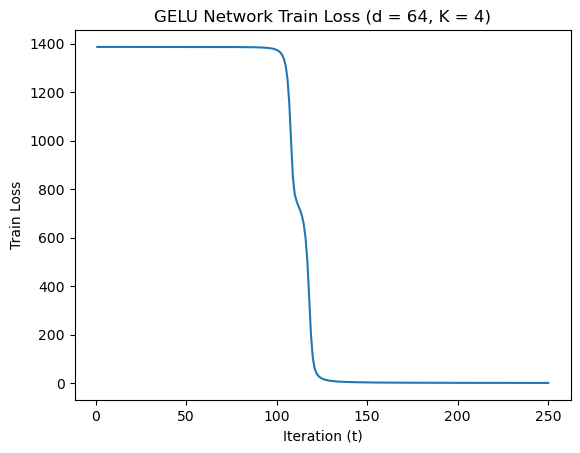

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:33:14,866 - INFO - Finish Epoch 1
2026-01-02 19:33:14,867 - INFO - Train loss: 1386.2961540222168, train accuracy: 20.6
2026-01-02 19:33:14,884 - INFO - Val loss: 1386.2954483032227, val accuracy: 21.9
2026-01-02 19:33:14,923 - INFO - Finish Epoch 2
2026-01-02 19:33:14,924 - INFO - Train loss: 1386.2950658798218, train accuracy: 22.3
2026-01-02 19:33:14,941 - INFO - Val loss: 1386.2943286895752, val accuracy: 23.6
  1%|          | 2/250 [00:00<00:14, 17.60it/s]2026-01-02 19:33:14,980 - INFO - Finish Epoch 3
2026-01-02 19:33:14,981 - INFO - Train loss: 1386.293957710266, train accuracy: 24.4
2026-01-02 19:33:14,998 - INFO - Val loss: 1386.2932176589966, val accuracy: 25.7
2026-01-02 19:33:15,036 - INFO - Finish Epoch 4
2026-01-02 19:33:15,037 - INFO - Train loss: 1386.2928190231323, train accuracy: 26.5
2026-01-02 19:33:15,054 - INFO - Val loss: 1386.292070388794, val accuracy: 28.4
  2%|▏         | 4/250 [00:00<00:13, 17.61it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.61it/s]2026-01-02 19:33:18,734 - INFO - Finish Epoch 69
2026-01-02 19:33:18,735 - INFO - Train loss: 1385.9048862457275, train accuracy: 99.4
2026-01-02 19:33:18,751 - INFO - Val loss: 1385.884298324585, val accuracy: 99.4
2026-01-02 19:33:18,789 - INFO - Finish Epoch 70
2026-01-02 19:33:18,790 - INFO - Train loss: 1385.870553970337, train accuracy: 99.4
2026-01-02 19:33:18,808 - INFO - Val loss: 1385.8474388122559, val accuracy: 99.4
 28%|██▊       | 70/250 [00:03<00:10, 17.64it/s]2026-01-02 19:33:18,847 - INFO - Finish Epoch 71
2026-01-02 19:33:18,848 - INFO - Train loss: 1385.8319177627563, train accuracy: 99.2
2026-01-02 19:33:18,865 - INFO - Val loss: 1385.8058986663818, val accuracy: 99.3
2026-01-02 19:33:18,903 - INFO - Finish Epoch 72
2026-01-02 19:33:18,904 - INFO - Train loss: 1385.7882986068726, train accuracy: 98.9
2026-01-02 19:33:18,921 - INFO - Val loss: 1385.758861541748, val accuracy: 99.1
 29%|██▉       | 72/250 [00:04<00:10, 1

 54%|█████▍    | 136/250 [00:07<00:06, 17.72it/s]2026-01-02 19:33:22,597 - INFO - Finish Epoch 137
2026-01-02 19:33:22,598 - INFO - Train loss: 4.778422925621271, train accuracy: 100.0
2026-01-02 19:33:22,615 - INFO - Val loss: 4.491257023066282, val accuracy: 100.0
2026-01-02 19:33:22,653 - INFO - Finish Epoch 138
2026-01-02 19:33:22,654 - INFO - Train loss: 4.51082669198513, train accuracy: 100.0
2026-01-02 19:33:22,670 - INFO - Val loss: 4.250664722174406, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.74it/s]2026-01-02 19:33:22,709 - INFO - Finish Epoch 139
2026-01-02 19:33:22,710 - INFO - Train loss: 4.26927755586803, train accuracy: 100.0
2026-01-02 19:33:22,727 - INFO - Val loss: 4.032551763579249, val accuracy: 100.0
2026-01-02 19:33:22,765 - INFO - Finish Epoch 140
2026-01-02 19:33:22,766 - INFO - Train loss: 4.050258308649063, train accuracy: 100.0
2026-01-02 19:33:22,782 - INFO - Val loss: 3.833982553333044, val accuracy: 100.0
 56%|█████▌    | 140/250 [00:07<

 68%|██████▊   | 170/250 [00:09<00:04, 17.70it/s]2026-01-02 19:33:24,521 - INFO - Finish Epoch 171
2026-01-02 19:33:24,522 - INFO - Train loss: 1.4551877561025321, train accuracy: 100.0
2026-01-02 19:33:24,539 - INFO - Val loss: 1.4182218885980546, val accuracy: 100.0
2026-01-02 19:33:24,577 - INFO - Finish Epoch 172
2026-01-02 19:33:24,578 - INFO - Train loss: 1.423198716249317, train accuracy: 100.0
2026-01-02 19:33:24,595 - INFO - Val loss: 1.3876265548169613, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.68it/s]2026-01-02 19:33:24,635 - INFO - Finish Epoch 173
2026-01-02 19:33:24,636 - INFO - Train loss: 1.392453030217439, train accuracy: 100.0
2026-01-02 19:33:24,653 - INFO - Val loss: 1.3582047349773347, val accuracy: 100.0
2026-01-02 19:33:24,692 - INFO - Finish Epoch 174
2026-01-02 19:33:24,693 - INFO - Train loss: 1.3628907361999154, train accuracy: 100.0
2026-01-02 19:33:24,710 - INFO - Val loss: 1.329897252842784, val accuracy: 100.0
 70%|██████▉   | 174/250 

2026-01-02 19:33:26,413 - INFO - Val loss: 0.8010947934817523, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.56it/s]2026-01-02 19:33:26,453 - INFO - Finish Epoch 205
2026-01-02 19:33:26,454 - INFO - Train loss: 0.8032656172290444, train accuracy: 100.0
2026-01-02 19:33:26,470 - INFO - Val loss: 0.79012551298365, val accuracy: 100.0
2026-01-02 19:33:26,509 - INFO - Finish Epoch 206
2026-01-02 19:33:26,510 - INFO - Train loss: 0.7922511326614767, train accuracy: 100.0
2026-01-02 19:33:26,526 - INFO - Val loss: 0.7794242305681109, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.60it/s]2026-01-02 19:33:26,565 - INFO - Finish Epoch 207
2026-01-02 19:33:26,567 - INFO - Train loss: 0.7815044759772718, train accuracy: 100.0
2026-01-02 19:33:26,583 - INFO - Val loss: 0.7689823186956346, val accuracy: 100.0
2026-01-02 19:33:26,621 - INFO - Finish Epoch 208
2026-01-02 19:33:26,623 - INFO - Train loss: 0.771019758656621, train accuracy: 100.0
2026-01-02 19:33:26,639 -

2026-01-02 19:33:28,324 - INFO - Train loss: 0.5438698672223836, train accuracy: 100.0
2026-01-02 19:33:28,341 - INFO - Val loss: 0.537233283277601, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.62it/s]2026-01-02 19:33:28,380 - INFO - Finish Epoch 239
2026-01-02 19:33:28,381 - INFO - Train loss: 0.5384055553004146, train accuracy: 100.0
2026-01-02 19:33:28,398 - INFO - Val loss: 0.5318805964197963, val accuracy: 100.0
2026-01-02 19:33:28,436 - INFO - Finish Epoch 240
2026-01-02 19:33:28,437 - INFO - Train loss: 0.5330392878968269, train accuracy: 100.0
2026-01-02 19:33:28,454 - INFO - Val loss: 0.5266288740094751, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.63it/s]2026-01-02 19:33:28,494 - INFO - Finish Epoch 241
2026-01-02 19:33:28,495 - INFO - Train loss: 0.5277648540213704, train accuracy: 100.0
2026-01-02 19:33:28,512 - INFO - Val loss: 0.5214676556643099, val accuracy: 100.0
2026-01-02 19:33:28,550 - INFO - Finish Epoch 242
2026-01-02 19:33:28,551

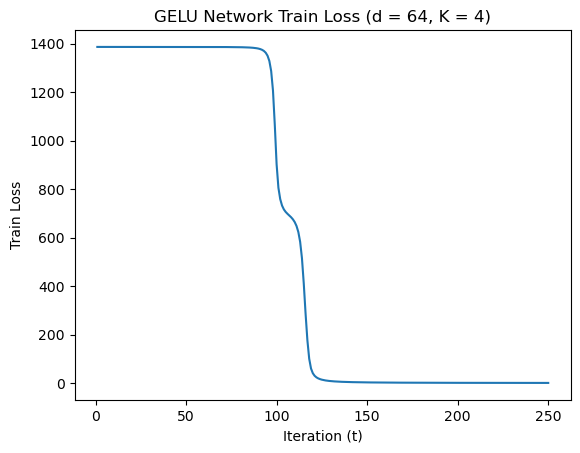

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:33:29,341 - INFO - Finish Epoch 1
2026-01-02 19:33:29,343 - INFO - Train loss: 1386.2905206680298, train accuracy: 33.0
2026-01-02 19:33:29,360 - INFO - Val loss: 1386.2898588180542, val accuracy: 34.6
2026-01-02 19:33:29,399 - INFO - Finish Epoch 2
2026-01-02 19:33:29,400 - INFO - Train loss: 1386.2895593643188, train accuracy: 35.5
2026-01-02 19:33:29,417 - INFO - Val loss: 1386.288872718811, val accuracy: 37.2
  1%|          | 2/250 [00:00<00:14, 17.44it/s]2026-01-02 19:33:29,456 - INFO - Finish Epoch 3
2026-01-02 19:33:29,457 - INFO - Train loss: 1386.2885494232178, train accuracy: 37.7
2026-01-02 19:33:29,474 - INFO - Val loss: 1386.2878694534302, val accuracy: 39.0
2026-01-02 19:33:29,513 - INFO - Finish Epoch 4
2026-01-02 19:33:29,514 - INFO - Train loss: 1386.2875547409058, train accuracy: 39.7
2026-01-02 19:33:29,531 - INFO - Val loss: 1386.2868671417236, val accuracy: 41.0
  2%|▏         | 4/250 [00:00<00:14, 17.47it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.42it/s]2026-01-02 19:33:33,305 - INFO - Finish Epoch 69
2026-01-02 19:33:33,306 - INFO - Train loss: 1385.9683799743652, train accuracy: 100.0
2026-01-02 19:33:33,323 - INFO - Val loss: 1385.9532566070557, val accuracy: 100.0
2026-01-02 19:33:33,361 - INFO - Finish Epoch 70
2026-01-02 19:33:33,362 - INFO - Train loss: 1385.944845199585, train accuracy: 100.0
2026-01-02 19:33:33,379 - INFO - Val loss: 1385.9282293319702, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.50it/s]2026-01-02 19:33:33,418 - INFO - Finish Epoch 71
2026-01-02 19:33:33,419 - INFO - Train loss: 1385.9189920425415, train accuracy: 100.0
2026-01-02 19:33:33,436 - INFO - Val loss: 1385.900712966919, val accuracy: 100.0
2026-01-02 19:33:33,474 - INFO - Finish Epoch 72
2026-01-02 19:33:33,476 - INFO - Train loss: 1385.8905792236328, train accuracy: 100.0
2026-01-02 19:33:33,492 - INFO - Val loss: 1385.8703994750977, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04

 41%|████      | 102/250 [00:05<00:08, 17.54it/s]2026-01-02 19:33:35,242 - INFO - Finish Epoch 103
2026-01-02 19:33:35,243 - INFO - Train loss: 1349.9783010482788, train accuracy: 94.4
2026-01-02 19:33:35,260 - INFO - Val loss: 1338.881838798523, val accuracy: 93.5
2026-01-02 19:33:35,298 - INFO - Finish Epoch 104
2026-01-02 19:33:35,299 - INFO - Train loss: 1332.8490505218506, train accuracy: 90.7
2026-01-02 19:33:35,316 - INFO - Val loss: 1313.7048711776733, val accuracy: 87.5
 42%|████▏     | 104/250 [00:06<00:08, 17.57it/s]2026-01-02 19:33:35,355 - INFO - Finish Epoch 105
2026-01-02 19:33:35,356 - INFO - Train loss: 1303.122579574585, train accuracy: 83.8
2026-01-02 19:33:35,373 - INFO - Val loss: 1268.0699062347412, val accuracy: 80.0
2026-01-02 19:33:35,411 - INFO - Finish Epoch 106
2026-01-02 19:33:35,412 - INFO - Train loss: 1248.6299266815186, train accuracy: 75.6
2026-01-02 19:33:35,429 - INFO - Val loss: 1182.57958984375, val accuracy: 70.1
 42%|████▏     | 106/250 [00:06<00

 54%|█████▍    | 136/250 [00:07<00:06, 17.51it/s]2026-01-02 19:33:37,169 - INFO - Finish Epoch 137
2026-01-02 19:33:37,170 - INFO - Train loss: 4.789188392460346, train accuracy: 100.0
2026-01-02 19:33:37,187 - INFO - Val loss: 4.583591591566801, val accuracy: 100.0
2026-01-02 19:33:37,226 - INFO - Finish Epoch 138
2026-01-02 19:33:37,228 - INFO - Train loss: 4.540014356374741, train accuracy: 100.0
2026-01-02 19:33:37,245 - INFO - Val loss: 4.352340390905738, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.45it/s]2026-01-02 19:33:37,285 - INFO - Finish Epoch 139
2026-01-02 19:33:37,287 - INFO - Train loss: 4.3132167384028435, train accuracy: 100.0
2026-01-02 19:33:37,304 - INFO - Val loss: 4.141278246417642, val accuracy: 100.0
2026-01-02 19:33:37,343 - INFO - Finish Epoch 140
2026-01-02 19:33:37,344 - INFO - Train loss: 4.106010161340237, train accuracy: 100.0
2026-01-02 19:33:37,361 - INFO - Val loss: 3.9479613341391087, val accuracy: 100.0
 56%|█████▌    | 140/250 [00

2026-01-02 19:33:39,058 - INFO - Val loss: 1.5374902421608567, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.72it/s]2026-01-02 19:33:39,098 - INFO - Finish Epoch 171
2026-01-02 19:33:39,099 - INFO - Train loss: 1.5330876293592155, train accuracy: 100.0
2026-01-02 19:33:39,115 - INFO - Val loss: 1.504182644188404, val accuracy: 100.0
2026-01-02 19:33:39,153 - INFO - Finish Epoch 172
2026-01-02 19:33:39,154 - INFO - Train loss: 1.4999841838143766, train accuracy: 100.0
2026-01-02 19:33:39,171 - INFO - Val loss: 1.472157440148294, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.73it/s]2026-01-02 19:33:39,209 - INFO - Finish Epoch 173
2026-01-02 19:33:39,211 - INFO - Train loss: 1.4681411902420223, train accuracy: 100.0
2026-01-02 19:33:39,227 - INFO - Val loss: 1.4413306494243443, val accuracy: 100.0
2026-01-02 19:33:39,265 - INFO - Finish Epoch 174
2026-01-02 19:33:39,266 - INFO - Train loss: 1.4374916683882475, train accuracy: 100.0
2026-01-02 19:33:39,282 

2026-01-02 19:33:40,948 - INFO - Train loss: 0.8640942238271236, train accuracy: 100.0
2026-01-02 19:33:40,965 - INFO - Val loss: 0.8534571090713143, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.78it/s]2026-01-02 19:33:41,004 - INFO - Finish Epoch 205
2026-01-02 19:33:41,005 - INFO - Train loss: 0.8521923103835434, train accuracy: 100.0
2026-01-02 19:33:41,021 - INFO - Val loss: 0.84181281295605, val accuracy: 100.0
2026-01-02 19:33:41,059 - INFO - Finish Epoch 206
2026-01-02 19:33:41,060 - INFO - Train loss: 0.8405834338627756, train accuracy: 100.0
2026-01-02 19:33:41,077 - INFO - Val loss: 0.8304436611942947, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.81it/s]2026-01-02 19:33:41,117 - INFO - Finish Epoch 207
2026-01-02 19:33:41,118 - INFO - Train loss: 0.8292518150992692, train accuracy: 100.0
2026-01-02 19:33:41,135 - INFO - Val loss: 0.8193540801294148, val accuracy: 100.0
2026-01-02 19:33:41,174 - INFO - Finish Epoch 208
2026-01-02 19:33:41,175 

2026-01-02 19:33:42,862 - INFO - Finish Epoch 238
2026-01-02 19:33:42,863 - INFO - Train loss: 0.5779476045863703, train accuracy: 100.0
2026-01-02 19:33:42,880 - INFO - Val loss: 0.5726951935794204, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.80it/s]2026-01-02 19:33:42,919 - INFO - Finish Epoch 239
2026-01-02 19:33:42,920 - INFO - Train loss: 0.572152019944042, train accuracy: 100.0
2026-01-02 19:33:42,936 - INFO - Val loss: 0.5669906414113939, val accuracy: 100.0
2026-01-02 19:33:42,974 - INFO - Finish Epoch 240
2026-01-02 19:33:42,975 - INFO - Train loss: 0.5664583262987435, train accuracy: 100.0
2026-01-02 19:33:42,992 - INFO - Val loss: 0.5613895683782175, val accuracy: 100.0
 96%|█████████▌| 240/250 [00:13<00:00, 17.84it/s]2026-01-02 19:33:43,030 - INFO - Finish Epoch 241
2026-01-02 19:33:43,032 - INFO - Train loss: 0.5608690581284463, train accuracy: 100.0
2026-01-02 19:33:43,048 - INFO - Val loss: 0.555887321010232, val accuracy: 100.0
2026-01-02 19:33:43,086 

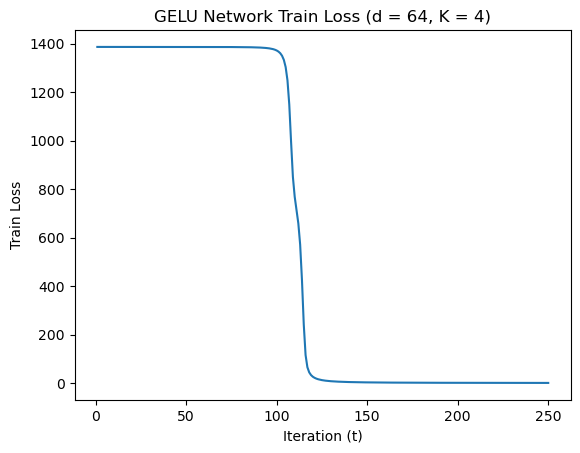

===== ACTIVATION FUNCTION:  Leaky-ReLU  =====
=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:33:43,880 - INFO - Finish Epoch 1
2026-01-02 19:33:43,882 - INFO - Train loss: 1386.2987842559814, train accuracy: 20.7
2026-01-02 19:33:43,903 - INFO - Val loss: 1386.2921504974365, val accuracy: 28.5
2026-01-02 19:33:43,943 - INFO - Finish Epoch 2
2026-01-02 19:33:43,945 - INFO - Train loss: 1386.295226097107, train accuracy: 24.5
2026-01-02 19:33:43,962 - INFO - Val loss: 1386.2899236679077, val accuracy: 29.9
  1%|          | 2/250 [00:00<00:14, 16.56it/s]2026-01-02 19:33:44,003 - INFO - Finish Epoch 3
2026-01-02 19:33:44,004 - INFO - Train loss: 1386.2929277420044, train accuracy: 26.4
2026-01-02 19:33:44,022 - INFO - Val loss: 1386.2876663208008, val accuracy: 31.5
2026-01-02 19:33:44,061 - INFO - Finish Epoch 4
2026-01-02 19:33:44,062 - INFO - Train loss: 1386.2906665802002, train accuracy: 28.0
2026-01-02 19:33:44,080 - INFO - Val loss: 1386.2853717803955, val accuracy: 32.8
  2%|▏         | 4/250 [00:00<00:14, 16.84it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.51it/s]2026-01-02 19:33:47,802 - INFO - Finish Epoch 69
2026-01-02 19:33:47,803 - INFO - Train loss: 1.8306811582297087, train accuracy: 100.0
2026-01-02 19:33:47,820 - INFO - Val loss: 1.6857325471937656, val accuracy: 100.0
2026-01-02 19:33:47,859 - INFO - Finish Epoch 70
2026-01-02 19:33:47,860 - INFO - Train loss: 1.647664307616651, train accuracy: 100.0
2026-01-02 19:33:47,877 - INFO - Val loss: 1.5292367041110992, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.52it/s]2026-01-02 19:33:47,916 - INFO - Finish Epoch 71
2026-01-02 19:33:47,917 - INFO - Train loss: 1.497514620423317, train accuracy: 100.0
2026-01-02 19:33:47,934 - INFO - Val loss: 1.3989473292604089, val accuracy: 100.0
2026-01-02 19:33:47,973 - INFO - Finish Epoch 72
2026-01-02 19:33:47,974 - INFO - Train loss: 1.372088460251689, train accuracy: 100.0
2026-01-02 19:33:47,990 - INFO - Val loss: 1.2888032402843237, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<

 41%|████      | 102/250 [00:05<00:08, 17.37it/s]2026-01-02 19:33:49,749 - INFO - Finish Epoch 103
2026-01-02 19:33:49,750 - INFO - Train loss: 0.36724649951793253, train accuracy: 100.0
2026-01-02 19:33:49,767 - INFO - Val loss: 0.3605487453751266, val accuracy: 100.0
2026-01-02 19:33:49,806 - INFO - Finish Epoch 104
2026-01-02 19:33:49,807 - INFO - Train loss: 0.3583822976797819, train accuracy: 100.0
2026-01-02 19:33:49,824 - INFO - Val loss: 0.35198789183050394, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.36it/s]2026-01-02 19:33:49,865 - INFO - Finish Epoch 105
2026-01-02 19:33:49,866 - INFO - Train loss: 0.34991477197036147, train accuracy: 100.0
2026-01-02 19:33:49,883 - INFO - Val loss: 0.3438046807423234, val accuracy: 100.0
2026-01-02 19:33:49,923 - INFO - Finish Epoch 106
2026-01-02 19:33:49,924 - INFO - Train loss: 0.3418202633038163, train accuracy: 100.0
2026-01-02 19:33:49,941 - INFO - Val loss: 0.33597236732020974, val accuracy: 100.0
 42%|████▏     | 1

2026-01-02 19:33:51,679 - INFO - Val loss: 0.19711804762482643, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.26it/s]2026-01-02 19:33:51,719 - INFO - Finish Epoch 137
2026-01-02 19:33:51,720 - INFO - Train loss: 0.19640888692811131, train accuracy: 100.0
2026-01-02 19:33:51,737 - INFO - Val loss: 0.194366917014122, val accuracy: 100.0
2026-01-02 19:33:51,776 - INFO - Finish Epoch 138
2026-01-02 19:33:51,777 - INFO - Train loss: 0.19368241354823112, train accuracy: 100.0
2026-01-02 19:33:51,794 - INFO - Val loss: 0.1916929631261155, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.30it/s]2026-01-02 19:33:51,833 - INFO - Finish Epoch 139
2026-01-02 19:33:51,834 - INFO - Train loss: 0.1910216842079535, train accuracy: 100.0
2026-01-02 19:33:51,851 - INFO - Val loss: 0.1890857060207054, val accuracy: 100.0
2026-01-02 19:33:51,890 - INFO - Finish Epoch 140
2026-01-02 19:33:51,891 - INFO - Train loss: 0.18843253119848669, train accuracy: 100.0
2026-01-02 19:33:51

2026-01-02 19:33:53,761 - INFO - Finish Epoch 170
2026-01-02 19:33:53,762 - INFO - Train loss: 0.13322071172297, train accuracy: 100.0
2026-01-02 19:33:53,779 - INFO - Val loss: 0.13224569777958095, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:05, 15.93it/s]2026-01-02 19:33:53,819 - INFO - Finish Epoch 171
2026-01-02 19:33:53,820 - INFO - Train loss: 0.13191274960990995, train accuracy: 100.0
2026-01-02 19:33:53,837 - INFO - Val loss: 0.13095059501938522, val accuracy: 100.0
2026-01-02 19:33:53,875 - INFO - Finish Epoch 172
2026-01-02 19:33:53,877 - INFO - Train loss: 0.13062312989495695, train accuracy: 100.0
2026-01-02 19:33:53,893 - INFO - Val loss: 0.12968480493873358, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 16.37it/s]2026-01-02 19:33:53,933 - INFO - Finish Epoch 173
2026-01-02 19:33:53,934 - INFO - Train loss: 0.1293625816470012, train accuracy: 100.0
2026-01-02 19:33:53,951 - INFO - Val loss: 0.12843533314298838, val accuracy: 100.0
2026-01-02 19:33:5

2026-01-02 19:33:55,642 - INFO - Train loss: 0.0999396963743493, train accuracy: 100.0
2026-01-02 19:33:55,658 - INFO - Val loss: 0.0993721173144877, val accuracy: 100.0
2026-01-02 19:33:55,697 - INFO - Finish Epoch 204
2026-01-02 19:33:55,698 - INFO - Train loss: 0.09917797998059541, train accuracy: 100.0
2026-01-02 19:33:55,715 - INFO - Val loss: 0.0986208866816014, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.63it/s]2026-01-02 19:33:55,754 - INFO - Finish Epoch 205
2026-01-02 19:33:55,755 - INFO - Train loss: 0.09842806070810184, train accuracy: 100.0
2026-01-02 19:33:55,772 - INFO - Val loss: 0.09787608683109283, val accuracy: 100.0
2026-01-02 19:33:55,810 - INFO - Finish Epoch 206
2026-01-02 19:33:55,811 - INFO - Train loss: 0.0976885054842569, train accuracy: 100.0
2026-01-02 19:33:55,828 - INFO - Val loss: 0.09714236983563751, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.65it/s]2026-01-02 19:33:55,867 - INFO - Finish Epoch 207
2026-01-02 19:33:5

 94%|█████████▍| 236/250 [00:13<00:00, 17.72it/s]2026-01-02 19:33:57,569 - INFO - Finish Epoch 237
2026-01-02 19:33:57,570 - INFO - Train loss: 0.07903019932564348, train accuracy: 100.0
2026-01-02 19:33:57,587 - INFO - Val loss: 0.07867005816660821, val accuracy: 100.0
2026-01-02 19:33:57,625 - INFO - Finish Epoch 238
2026-01-02 19:33:57,626 - INFO - Train loss: 0.07854241615859792, train accuracy: 100.0
2026-01-02 19:33:57,645 - INFO - Val loss: 0.07818310911534354, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.60it/s]2026-01-02 19:33:57,685 - INFO - Finish Epoch 239
2026-01-02 19:33:57,686 - INFO - Train loss: 0.0780589206260629, train accuracy: 100.0
2026-01-02 19:33:57,703 - INFO - Val loss: 0.07770318817347288, val accuracy: 100.0
2026-01-02 19:33:57,742 - INFO - Finish Epoch 240
2026-01-02 19:33:57,743 - INFO - Train loss: 0.0775799538823776, train accuracy: 100.0
2026-01-02 19:33:57,761 - INFO - Val loss: 0.07722851226571947, val accuracy: 100.0
 96%|█████████▌|

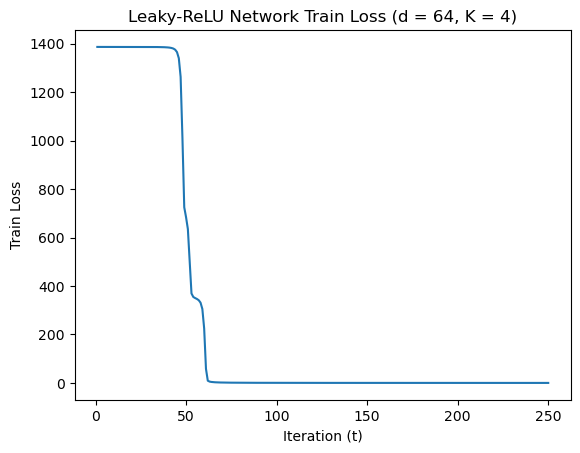

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:33:58,659 - INFO - Finish Epoch 1
2026-01-02 19:33:58,661 - INFO - Train loss: 1386.2996730804443, train accuracy: 24.7
2026-01-02 19:33:58,678 - INFO - Val loss: 1386.2911376953125, val accuracy: 25.9
2026-01-02 19:33:58,717 - INFO - Finish Epoch 2
2026-01-02 19:33:58,718 - INFO - Train loss: 1386.295030593872, train accuracy: 25.5
2026-01-02 19:33:58,735 - INFO - Val loss: 1386.288106918335, val accuracy: 26.3
  1%|          | 2/250 [00:00<00:14, 17.49it/s]2026-01-02 19:33:58,774 - INFO - Finish Epoch 3
2026-01-02 19:33:58,776 - INFO - Train loss: 1386.2918949127197, train accuracy: 25.7
2026-01-02 19:33:58,793 - INFO - Val loss: 1386.285057067871, val accuracy: 26.5
2026-01-02 19:33:58,832 - INFO - Finish Epoch 4
2026-01-02 19:33:58,833 - INFO - Train loss: 1386.2888317108154, train accuracy: 25.9
2026-01-02 19:33:58,850 - INFO - Val loss: 1386.2819213867188, val accuracy: 26.8
  2%|▏         | 4/250 [00:00<00:14, 17.39it/s]2026-0

 27%|██▋       | 68/250 [00:03<00:10, 17.56it/s]2026-01-02 19:34:02,549 - INFO - Finish Epoch 69
2026-01-02 19:34:02,550 - INFO - Train loss: 1.5325519675388932, train accuracy: 100.0
2026-01-02 19:34:02,567 - INFO - Val loss: 1.4470209488645196, val accuracy: 100.0
2026-01-02 19:34:02,606 - INFO - Finish Epoch 70
2026-01-02 19:34:02,607 - INFO - Train loss: 1.4238046603277326, train accuracy: 100.0
2026-01-02 19:34:02,624 - INFO - Val loss: 1.3492026664316654, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.50it/s]2026-01-02 19:34:02,664 - INFO - Finish Epoch 71
2026-01-02 19:34:02,665 - INFO - Train loss: 1.3288842467591166, train accuracy: 100.0
2026-01-02 19:34:02,682 - INFO - Val loss: 1.2632448626682162, val accuracy: 100.0
2026-01-02 19:34:02,721 - INFO - Finish Epoch 72
2026-01-02 19:34:02,722 - INFO - Train loss: 1.245295537635684, train accuracy: 100.0
2026-01-02 19:34:02,739 - INFO - Val loss: 1.1871305434033275, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:05<00:08, 17.51it/s]2026-01-02 19:34:04,486 - INFO - Finish Epoch 103
2026-01-02 19:34:04,487 - INFO - Train loss: 0.40138024976477027, train accuracy: 100.0
2026-01-02 19:34:04,504 - INFO - Val loss: 0.394361810060218, val accuracy: 100.0
2026-01-02 19:34:04,546 - INFO - Finish Epoch 104
2026-01-02 19:34:04,547 - INFO - Train loss: 0.39232005970552564, train accuracy: 100.0
2026-01-02 19:34:04,565 - INFO - Val loss: 0.3855988420546055, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.33it/s]2026-01-02 19:34:04,605 - INFO - Finish Epoch 105
2026-01-02 19:34:04,607 - INFO - Train loss: 0.3836425575427711, train accuracy: 100.0
2026-01-02 19:34:04,624 - INFO - Val loss: 0.37719643488526344, val accuracy: 100.0
2026-01-02 19:34:04,665 - INFO - Finish Epoch 106
2026-01-02 19:34:04,666 - INFO - Train loss: 0.37531657121144235, train accuracy: 100.0
2026-01-02 19:34:04,684 - INFO - Val loss: 0.369129722006619, val accuracy: 100.0
 42%|████▏     | 106

2026-01-02 19:34:06,410 - INFO - Val loss: 0.22188091289717704, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.48it/s]2026-01-02 19:34:06,450 - INFO - Finish Epoch 137
2026-01-02 19:34:06,451 - INFO - Train loss: 0.22118203539866954, train accuracy: 100.0
2026-01-02 19:34:06,468 - INFO - Val loss: 0.2188838836736977, val accuracy: 100.0
2026-01-02 19:34:06,506 - INFO - Finish Epoch 138
2026-01-02 19:34:06,507 - INFO - Train loss: 0.21820167871192098, train accuracy: 100.0
2026-01-02 19:34:06,524 - INFO - Val loss: 0.21596557064913213, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.51it/s]2026-01-02 19:34:06,564 - INFO - Finish Epoch 139
2026-01-02 19:34:06,565 - INFO - Train loss: 0.21529872715473175, train accuracy: 100.0
2026-01-02 19:34:06,582 - INFO - Val loss: 0.21311429131310433, val accuracy: 100.0
2026-01-02 19:34:06,620 - INFO - Finish Epoch 140
2026-01-02 19:34:06,621 - INFO - Train loss: 0.2124632919440046, train accuracy: 100.0
2026-01-02 19:34

2026-01-02 19:34:08,337 - INFO - Finish Epoch 170
2026-01-02 19:34:08,338 - INFO - Train loss: 0.1513848751783371, train accuracy: 100.0
2026-01-02 19:34:08,355 - INFO - Val loss: 0.15026003471575677, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.49it/s]2026-01-02 19:34:08,395 - INFO - Finish Epoch 171
2026-01-02 19:34:08,396 - INFO - Train loss: 0.14992209360934794, train accuracy: 100.0
2026-01-02 19:34:08,413 - INFO - Val loss: 0.14881439972668886, val accuracy: 100.0
2026-01-02 19:34:08,451 - INFO - Finish Epoch 172
2026-01-02 19:34:08,452 - INFO - Train loss: 0.14848193991929293, train accuracy: 100.0
2026-01-02 19:34:08,469 - INFO - Val loss: 0.14739532966632396, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.50it/s]2026-01-02 19:34:08,509 - INFO - Finish Epoch 173
2026-01-02 19:34:08,510 - INFO - Train loss: 0.14706810866482556, train accuracy: 100.0
2026-01-02 19:34:08,527 - INFO - Val loss: 0.14599877002183348, val accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:34:10,216 - INFO - Train loss: 0.11399031709879637, train accuracy: 100.0
2026-01-02 19:34:10,233 - INFO - Val loss: 0.11332636181032285, val accuracy: 100.0
2026-01-02 19:34:10,271 - INFO - Finish Epoch 204
2026-01-02 19:34:10,272 - INFO - Train loss: 0.11312782095046714, train accuracy: 100.0
2026-01-02 19:34:10,289 - INFO - Val loss: 0.11247744935099036, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.67it/s]2026-01-02 19:34:10,328 - INFO - Finish Epoch 205
2026-01-02 19:34:10,329 - INFO - Train loss: 0.11228093469981104, train accuracy: 100.0
2026-01-02 19:34:10,346 - INFO - Val loss: 0.11163675494026393, val accuracy: 100.0
2026-01-02 19:34:10,385 - INFO - Finish Epoch 206
2026-01-02 19:34:10,386 - INFO - Train loss: 0.11144286184571683, train accuracy: 100.0
2026-01-02 19:34:10,403 - INFO - Val loss: 0.11080618755659088, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.64it/s]2026-01-02 19:34:10,443 - INFO - Finish Epoch 207
2026-01-02 19:

 94%|█████████▍| 236/250 [00:13<00:00, 17.23it/s]2026-01-02 19:34:12,175 - INFO - Finish Epoch 237
2026-01-02 19:34:12,176 - INFO - Train loss: 0.09029644093243405, train accuracy: 100.0
2026-01-02 19:34:12,193 - INFO - Val loss: 0.08986791002098471, val accuracy: 100.0
2026-01-02 19:34:12,233 - INFO - Finish Epoch 238
2026-01-02 19:34:12,235 - INFO - Train loss: 0.08973907720064744, train accuracy: 100.0
2026-01-02 19:34:12,252 - INFO - Val loss: 0.08931459777522832, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.15it/s]2026-01-02 19:34:12,292 - INFO - Finish Epoch 239
2026-01-02 19:34:12,293 - INFO - Train loss: 0.08918898418778554, train accuracy: 100.0
2026-01-02 19:34:12,310 - INFO - Val loss: 0.08877272653626278, val accuracy: 100.0
2026-01-02 19:34:12,349 - INFO - Finish Epoch 240
2026-01-02 19:34:12,350 - INFO - Train loss: 0.08864591794554144, train accuracy: 100.0
2026-01-02 19:34:12,367 - INFO - Val loss: 0.08823061245493591, val accuracy: 100.0
 96%|█████████

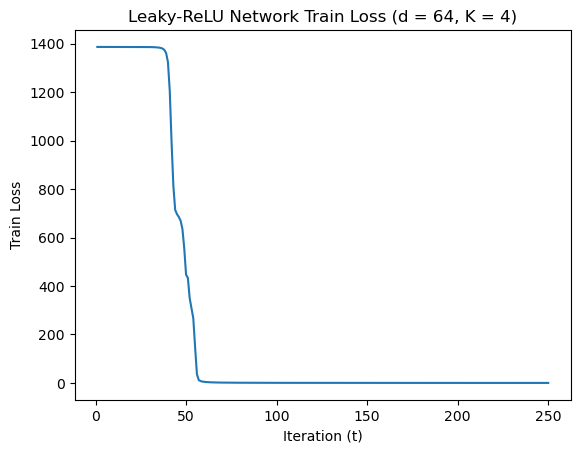

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:34:13,263 - INFO - Finish Epoch 1
2026-01-02 19:34:13,264 - INFO - Train loss: 1386.2969970703125, train accuracy: 25.7
2026-01-02 19:34:13,281 - INFO - Val loss: 1386.291696548462, val accuracy: 28.8
2026-01-02 19:34:13,320 - INFO - Finish Epoch 2
2026-01-02 19:34:13,321 - INFO - Train loss: 1386.2941513061523, train accuracy: 27.7
2026-01-02 19:34:13,338 - INFO - Val loss: 1386.2897930145264, val accuracy: 29.4
  1%|          | 2/250 [00:00<00:14, 17.64it/s]2026-01-02 19:34:13,377 - INFO - Finish Epoch 3
2026-01-02 19:34:13,378 - INFO - Train loss: 1386.292194366455, train accuracy: 28.9
2026-01-02 19:34:13,395 - INFO - Val loss: 1386.2878704071045, val accuracy: 31.1
2026-01-02 19:34:13,433 - INFO - Finish Epoch 4
2026-01-02 19:34:13,435 - INFO - Train loss: 1386.2902584075928, train accuracy: 29.7
2026-01-02 19:34:13,451 - INFO - Val loss: 1386.2859077453613, val accuracy: 32.4
  2%|▏         | 4/250 [00:00<00:13, 17.60it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.23it/s]2026-01-02 19:34:17,197 - INFO - Finish Epoch 69
2026-01-02 19:34:17,198 - INFO - Train loss: 1.4244689345359802, train accuracy: 100.0
2026-01-02 19:34:17,215 - INFO - Val loss: 1.347715513780713, val accuracy: 100.0
2026-01-02 19:34:17,253 - INFO - Finish Epoch 70
2026-01-02 19:34:17,255 - INFO - Train loss: 1.32337583322078, train accuracy: 100.0
2026-01-02 19:34:17,272 - INFO - Val loss: 1.2564037721604109, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.30it/s]2026-01-02 19:34:17,311 - INFO - Finish Epoch 71
2026-01-02 19:34:17,313 - INFO - Train loss: 1.2349954545497894, train accuracy: 100.0
2026-01-02 19:34:17,330 - INFO - Val loss: 1.1760853929445148, val accuracy: 100.0
2026-01-02 19:34:17,369 - INFO - Finish Epoch 72
2026-01-02 19:34:17,370 - INFO - Train loss: 1.1571283917874098, train accuracy: 100.0
2026-01-02 19:34:17,387 - INFO - Val loss: 1.1049092467874289, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<

 41%|████      | 102/250 [00:05<00:08, 17.36it/s]2026-01-02 19:34:19,157 - INFO - Finish Epoch 103
2026-01-02 19:34:19,158 - INFO - Train loss: 0.3694462371058762, train accuracy: 100.0
2026-01-02 19:34:19,175 - INFO - Val loss: 0.36319895554333925, val accuracy: 100.0
2026-01-02 19:34:19,213 - INFO - Finish Epoch 104
2026-01-02 19:34:19,214 - INFO - Train loss: 0.3610313702374697, train accuracy: 100.0
2026-01-02 19:34:19,231 - INFO - Val loss: 0.3550470375921577, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.41it/s]2026-01-02 19:34:19,271 - INFO - Finish Epoch 105
2026-01-02 19:34:19,272 - INFO - Train loss: 0.352968140039593, train accuracy: 100.0
2026-01-02 19:34:19,289 - INFO - Val loss: 0.34723415691405535, val accuracy: 100.0
2026-01-02 19:34:19,328 - INFO - Finish Epoch 106
2026-01-02 19:34:19,329 - INFO - Train loss: 0.34523919178172946, train accuracy: 100.0
2026-01-02 19:34:19,346 - INFO - Val loss: 0.3397335254121572, val accuracy: 100.0
 42%|████▏     | 106

2026-01-02 19:34:21,070 - INFO - Val loss: 0.203278255648911, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.33it/s]2026-01-02 19:34:21,109 - INFO - Finish Epoch 137
2026-01-02 19:34:21,111 - INFO - Train loss: 0.2025360045954585, train accuracy: 100.0
2026-01-02 19:34:21,128 - INFO - Val loss: 0.20051044505089521, val accuracy: 100.0
2026-01-02 19:34:21,166 - INFO - Finish Epoch 138
2026-01-02 19:34:21,167 - INFO - Train loss: 0.19979201490059495, train accuracy: 100.0
2026-01-02 19:34:21,184 - INFO - Val loss: 0.1978159996215254, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.37it/s]2026-01-02 19:34:21,223 - INFO - Finish Epoch 139
2026-01-02 19:34:21,225 - INFO - Train loss: 0.1971128147561103, train accuracy: 100.0
2026-01-02 19:34:21,242 - INFO - Val loss: 0.195184561656788, val accuracy: 100.0
2026-01-02 19:34:21,280 - INFO - Finish Epoch 140
2026-01-02 19:34:21,281 - INFO - Train loss: 0.19450198882259429, train accuracy: 100.0
2026-01-02 19:34:21,2

2026-01-02 19:34:22,983 - INFO - Finish Epoch 170
2026-01-02 19:34:22,985 - INFO - Train loss: 0.13829137035645545, train accuracy: 100.0
2026-01-02 19:34:23,001 - INFO - Val loss: 0.13729688548482955, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.58it/s]2026-01-02 19:34:23,041 - INFO - Finish Epoch 171
2026-01-02 19:34:23,042 - INFO - Train loss: 0.13694452703930438, train accuracy: 100.0
2026-01-02 19:34:23,059 - INFO - Val loss: 0.1359727996168658, val accuracy: 100.0
2026-01-02 19:34:23,098 - INFO - Finish Epoch 172
2026-01-02 19:34:23,099 - INFO - Train loss: 0.13562413293402642, train accuracy: 100.0
2026-01-02 19:34:23,116 - INFO - Val loss: 0.13466551015153527, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.53it/s]2026-01-02 19:34:23,156 - INFO - Finish Epoch 173
2026-01-02 19:34:23,157 - INFO - Train loss: 0.1343225612072274, train accuracy: 100.0
2026-01-02 19:34:23,174 - INFO - Val loss: 0.1333877685246989, val accuracy: 100.0
2026-01-02 19:34:

2026-01-02 19:34:24,861 - INFO - Train loss: 0.1039740142878145, train accuracy: 100.0
2026-01-02 19:34:24,878 - INFO - Val loss: 0.10339628718793392, val accuracy: 100.0
2026-01-02 19:34:24,917 - INFO - Finish Epoch 204
2026-01-02 19:34:24,918 - INFO - Train loss: 0.10318749980069697, train accuracy: 100.0
2026-01-02 19:34:24,935 - INFO - Val loss: 0.10261537157930434, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.53it/s]2026-01-02 19:34:24,975 - INFO - Finish Epoch 205
2026-01-02 19:34:24,976 - INFO - Train loss: 0.10240789351519197, train accuracy: 100.0
2026-01-02 19:34:24,993 - INFO - Val loss: 0.10184708470478654, val accuracy: 100.0
2026-01-02 19:34:25,031 - INFO - Finish Epoch 206
2026-01-02 19:34:25,033 - INFO - Train loss: 0.10164342098869383, train accuracy: 100.0
2026-01-02 19:34:25,049 - INFO - Val loss: 0.101085948292166, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.52it/s]2026-01-02 19:34:25,089 - INFO - Finish Epoch 207
2026-01-02 19:34:

 94%|█████████▍| 236/250 [00:13<00:00, 17.45it/s]2026-01-02 19:34:26,811 - INFO - Finish Epoch 237
2026-01-02 19:34:26,812 - INFO - Train loss: 0.08228233677800745, train accuracy: 100.0
2026-01-02 19:34:26,829 - INFO - Val loss: 0.08191146166063845, val accuracy: 100.0
2026-01-02 19:34:26,868 - INFO - Finish Epoch 238
2026-01-02 19:34:26,869 - INFO - Train loss: 0.08177476411219686, train accuracy: 100.0
2026-01-02 19:34:26,886 - INFO - Val loss: 0.08140531834214926, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.38it/s]2026-01-02 19:34:26,926 - INFO - Finish Epoch 239
2026-01-02 19:34:26,927 - INFO - Train loss: 0.08127350837457925, train accuracy: 100.0
2026-01-02 19:34:26,945 - INFO - Val loss: 0.08090572920627892, val accuracy: 100.0
2026-01-02 19:34:26,984 - INFO - Finish Epoch 240
2026-01-02 19:34:26,985 - INFO - Train loss: 0.08077403798233718, train accuracy: 100.0
2026-01-02 19:34:27,002 - INFO - Val loss: 0.08041078748647124, val accuracy: 100.0
 96%|█████████

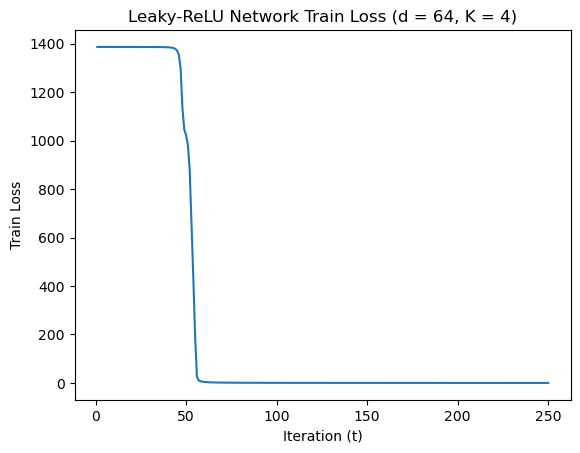

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:34:27,906 - INFO - Finish Epoch 1
2026-01-02 19:34:27,907 - INFO - Train loss: 1386.2970724105835, train accuracy: 23.5
2026-01-02 19:34:27,925 - INFO - Val loss: 1386.2914733886719, val accuracy: 27.5
2026-01-02 19:34:27,964 - INFO - Finish Epoch 2
2026-01-02 19:34:27,965 - INFO - Train loss: 1386.2939548492432, train accuracy: 25.6
2026-01-02 19:34:27,982 - INFO - Val loss: 1386.2893018722534, val accuracy: 28.6
  1%|          | 2/250 [00:00<00:14, 17.20it/s]2026-01-02 19:34:28,022 - INFO - Finish Epoch 3
2026-01-02 19:34:28,023 - INFO - Train loss: 1386.2917127609253, train accuracy: 26.4
2026-01-02 19:34:28,040 - INFO - Val loss: 1386.2870826721191, val accuracy: 30.0
2026-01-02 19:34:28,079 - INFO - Finish Epoch 4
2026-01-02 19:34:28,080 - INFO - Train loss: 1386.2894840240479, train accuracy: 27.7
2026-01-02 19:34:28,097 - INFO - Val loss: 1386.2848224639893, val accuracy: 31.2
  2%|▏         | 4/250 [00:00<00:14, 17.34it/s]202

 27%|██▋       | 68/250 [00:03<00:10, 17.42it/s]2026-01-02 19:34:31,829 - INFO - Finish Epoch 69
2026-01-02 19:34:31,830 - INFO - Train loss: 1.8190575875341892, train accuracy: 100.0
2026-01-02 19:34:31,847 - INFO - Val loss: 1.6785493921488523, val accuracy: 100.0
2026-01-02 19:34:31,886 - INFO - Finish Epoch 70
2026-01-02 19:34:31,888 - INFO - Train loss: 1.6502977777272463, train accuracy: 100.0
2026-01-02 19:34:31,905 - INFO - Val loss: 1.534147247672081, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.42it/s]2026-01-02 19:34:31,947 - INFO - Finish Epoch 71
2026-01-02 19:34:31,948 - INFO - Train loss: 1.5097806192934513, train accuracy: 100.0
2026-01-02 19:34:31,966 - INFO - Val loss: 1.4121355712413788, val accuracy: 100.0
2026-01-02 19:34:32,005 - INFO - Finish Epoch 72
2026-01-02 19:34:32,006 - INFO - Train loss: 1.3908755332231522, train accuracy: 100.0
2026-01-02 19:34:32,023 - INFO - Val loss: 1.3076400198042393, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:05<00:08, 17.42it/s]2026-01-02 19:34:33,785 - INFO - Finish Epoch 103
2026-01-02 19:34:33,786 - INFO - Train loss: 0.38521841540932655, train accuracy: 100.0
2026-01-02 19:34:33,803 - INFO - Val loss: 0.37814008886925876, val accuracy: 100.0
2026-01-02 19:34:33,841 - INFO - Finish Epoch 104
2026-01-02 19:34:33,842 - INFO - Train loss: 0.3759697596542537, train accuracy: 100.0
2026-01-02 19:34:33,859 - INFO - Val loss: 0.3692131226416677, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.45it/s]2026-01-02 19:34:33,899 - INFO - Finish Epoch 105
2026-01-02 19:34:33,900 - INFO - Train loss: 0.3671305547468364, train accuracy: 100.0
2026-01-02 19:34:33,917 - INFO - Val loss: 0.3606723095290363, val accuracy: 100.0
2026-01-02 19:34:33,956 - INFO - Finish Epoch 106
2026-01-02 19:34:33,957 - INFO - Train loss: 0.35867392597720027, train accuracy: 100.0
2026-01-02 19:34:33,975 - INFO - Val loss: 0.352492896374315, val accuracy: 100.0
 42%|████▏     | 106

2026-01-02 19:34:35,863 - INFO - Val loss: 0.2068707903381437, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:08, 12.97it/s]2026-01-02 19:34:35,904 - INFO - Finish Epoch 137
2026-01-02 19:34:35,905 - INFO - Train loss: 0.2061452321941033, train accuracy: 100.0
2026-01-02 19:34:35,922 - INFO - Val loss: 0.20397931430488825, val accuracy: 100.0
2026-01-02 19:34:35,961 - INFO - Finish Epoch 138
2026-01-02 19:34:35,962 - INFO - Train loss: 0.20327269786503166, train accuracy: 100.0
2026-01-02 19:34:35,979 - INFO - Val loss: 0.20116547937504947, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:08<00:07, 14.02it/s]2026-01-02 19:34:36,019 - INFO - Finish Epoch 139
2026-01-02 19:34:36,020 - INFO - Train loss: 0.20047506550326943, train accuracy: 100.0
2026-01-02 19:34:36,037 - INFO - Val loss: 0.19841940491460264, val accuracy: 100.0
2026-01-02 19:34:36,075 - INFO - Finish Epoch 140
2026-01-02 19:34:36,076 - INFO - Train loss: 0.19774590665474534, train accuracy: 100.0
2026-01-02 19:34

2026-01-02 19:34:37,795 - INFO - Finish Epoch 170
2026-01-02 19:34:37,796 - INFO - Train loss: 0.13952199066989124, train accuracy: 100.0
2026-01-02 19:34:37,813 - INFO - Val loss: 0.13848113222047687, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.43it/s]2026-01-02 19:34:37,852 - INFO - Finish Epoch 171
2026-01-02 19:34:37,853 - INFO - Train loss: 0.13813481258694082, train accuracy: 100.0
2026-01-02 19:34:37,870 - INFO - Val loss: 0.13711277511902153, val accuracy: 100.0
2026-01-02 19:34:37,909 - INFO - Finish Epoch 172
2026-01-02 19:34:37,910 - INFO - Train loss: 0.13676979369483888, train accuracy: 100.0
2026-01-02 19:34:37,926 - INFO - Val loss: 0.1357641884824261, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 17.48it/s]2026-01-02 19:34:37,966 - INFO - Finish Epoch 173
2026-01-02 19:34:37,967 - INFO - Train loss: 0.13543252740055323, train accuracy: 100.0
2026-01-02 19:34:37,984 - INFO - Val loss: 0.13444574899040163, val accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:34:39,678 - INFO - Train loss: 0.10432258120272309, train accuracy: 100.0
2026-01-02 19:34:39,695 - INFO - Val loss: 0.10372069833101705, val accuracy: 100.0
2026-01-02 19:34:39,734 - INFO - Finish Epoch 204
2026-01-02 19:34:39,735 - INFO - Train loss: 0.10351630218792707, train accuracy: 100.0
2026-01-02 19:34:39,752 - INFO - Val loss: 0.1029237155453302, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.53it/s]2026-01-02 19:34:39,791 - INFO - Finish Epoch 205
2026-01-02 19:34:39,792 - INFO - Train loss: 0.10272467986214906, train accuracy: 100.0
2026-01-02 19:34:39,809 - INFO - Val loss: 0.10213995398953557, val accuracy: 100.0
2026-01-02 19:34:39,847 - INFO - Finish Epoch 206
2026-01-02 19:34:39,848 - INFO - Train loss: 0.10194485302781686, train accuracy: 100.0
2026-01-02 19:34:39,865 - INFO - Val loss: 0.10136655968381092, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.55it/s]2026-01-02 19:34:39,905 - INFO - Finish Epoch 207
2026-01-02 19:3

 94%|█████████▍| 236/250 [00:13<00:00, 17.59it/s]2026-01-02 19:34:41,613 - INFO - Finish Epoch 237
2026-01-02 19:34:41,614 - INFO - Train loss: 0.08228454075288028, train accuracy: 100.0
2026-01-02 19:34:41,631 - INFO - Val loss: 0.08190355263650417, val accuracy: 100.0
2026-01-02 19:34:41,669 - INFO - Finish Epoch 238
2026-01-02 19:34:41,670 - INFO - Train loss: 0.0817751880385913, train accuracy: 100.0
2026-01-02 19:34:41,687 - INFO - Val loss: 0.08139038516674191, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.59it/s]2026-01-02 19:34:41,727 - INFO - Finish Epoch 239
2026-01-02 19:34:41,728 - INFO - Train loss: 0.08126369002275169, train accuracy: 100.0
2026-01-02 19:34:41,745 - INFO - Val loss: 0.08088603522628546, val accuracy: 100.0
2026-01-02 19:34:41,785 - INFO - Finish Epoch 240
2026-01-02 19:34:41,786 - INFO - Train loss: 0.08075767161790282, train accuracy: 100.0
2026-01-02 19:34:41,803 - INFO - Val loss: 0.08038991095963866, val accuracy: 100.0
 96%|█████████▌

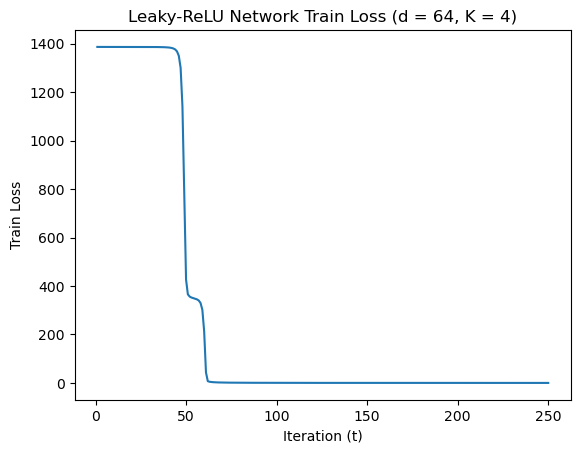

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:34:42,699 - INFO - Finish Epoch 1
2026-01-02 19:34:42,700 - INFO - Train loss: 1386.2950868606567, train accuracy: 23.3
2026-01-02 19:34:42,717 - INFO - Val loss: 1386.28955078125, val accuracy: 27.9
2026-01-02 19:34:42,756 - INFO - Finish Epoch 2
2026-01-02 19:34:42,757 - INFO - Train loss: 1386.2918548583984, train accuracy: 25.9
2026-01-02 19:34:42,774 - INFO - Val loss: 1386.2873363494873, val accuracy: 29.9
  1%|          | 2/250 [00:00<00:14, 17.53it/s]2026-01-02 19:34:42,813 - INFO - Finish Epoch 3
2026-01-02 19:34:42,814 - INFO - Train loss: 1386.2895708084106, train accuracy: 28.1
2026-01-02 19:34:42,831 - INFO - Val loss: 1386.2851066589355, val accuracy: 32.0
2026-01-02 19:34:42,870 - INFO - Finish Epoch 4
2026-01-02 19:34:42,871 - INFO - Train loss: 1386.2873678207397, train accuracy: 30.2
2026-01-02 19:34:42,888 - INFO - Val loss: 1386.2828350067139, val accuracy: 33.6
  2%|▏         | 4/250 [00:00<00:14, 17.52it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.37it/s]2026-01-02 19:34:46,626 - INFO - Finish Epoch 69
2026-01-02 19:34:46,627 - INFO - Train loss: 1.3661811109632254, train accuracy: 100.0
2026-01-02 19:34:46,644 - INFO - Val loss: 1.2985326014459133, val accuracy: 100.0
2026-01-02 19:34:46,683 - INFO - Finish Epoch 70
2026-01-02 19:34:46,684 - INFO - Train loss: 1.271600168198347, train accuracy: 100.0
2026-01-02 19:34:46,701 - INFO - Val loss: 1.2123616468161345, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.36it/s]2026-01-02 19:34:46,741 - INFO - Finish Epoch 71
2026-01-02 19:34:46,742 - INFO - Train loss: 1.1886985320597887, train accuracy: 100.0
2026-01-02 19:34:46,759 - INFO - Val loss: 1.1364321820437908, val accuracy: 100.0
2026-01-02 19:34:46,797 - INFO - Finish Epoch 72
2026-01-02 19:34:46,798 - INFO - Train loss: 1.1154874442145228, train accuracy: 100.0
2026-01-02 19:34:46,815 - INFO - Val loss: 1.069023816846311, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04

 41%|████      | 102/250 [00:05<00:08, 17.51it/s]2026-01-02 19:34:48,565 - INFO - Finish Epoch 103
2026-01-02 19:34:48,566 - INFO - Train loss: 0.3641126719303429, train accuracy: 100.0
2026-01-02 19:34:48,583 - INFO - Val loss: 0.3583142696879804, val accuracy: 100.0
2026-01-02 19:34:48,622 - INFO - Finish Epoch 104
2026-01-02 19:34:48,623 - INFO - Train loss: 0.35593246342614293, train accuracy: 100.0
2026-01-02 19:34:48,640 - INFO - Val loss: 0.35037471912801266, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.52it/s]2026-01-02 19:34:48,679 - INFO - Finish Epoch 105
2026-01-02 19:34:48,680 - INFO - Train loss: 0.348088595084846, train accuracy: 100.0
2026-01-02 19:34:48,697 - INFO - Val loss: 0.3427554527297616, val accuracy: 100.0
2026-01-02 19:34:48,736 - INFO - Finish Epoch 106
2026-01-02 19:34:48,737 - INFO - Train loss: 0.34056452568620443, train accuracy: 100.0
2026-01-02 19:34:48,754 - INFO - Val loss: 0.33544493559747934, val accuracy: 100.0
 42%|████▏     | 10

2026-01-02 19:34:50,473 - INFO - Val loss: 0.20175415789708495, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.45it/s]2026-01-02 19:34:50,512 - INFO - Finish Epoch 137
2026-01-02 19:34:50,514 - INFO - Train loss: 0.20094662252813578, train accuracy: 100.0
2026-01-02 19:34:50,530 - INFO - Val loss: 0.19903145148418844, val accuracy: 100.0
2026-01-02 19:34:50,569 - INFO - Finish Epoch 138
2026-01-02 19:34:50,570 - INFO - Train loss: 0.19824463338591158, train accuracy: 100.0
2026-01-02 19:34:50,587 - INFO - Val loss: 0.19637530902400613, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.48it/s]2026-01-02 19:34:50,626 - INFO - Finish Epoch 139
2026-01-02 19:34:50,628 - INFO - Train loss: 0.1956088598817587, train accuracy: 100.0
2026-01-02 19:34:50,645 - INFO - Val loss: 0.19378515682183206, val accuracy: 100.0
2026-01-02 19:34:50,683 - INFO - Finish Epoch 140
2026-01-02 19:34:50,684 - INFO - Train loss: 0.1930375169031322, train accuracy: 100.0
2026-01-02 19:34

2026-01-02 19:34:52,404 - INFO - Finish Epoch 170
2026-01-02 19:34:52,405 - INFO - Train loss: 0.13755002338439226, train accuracy: 100.0
2026-01-02 19:34:52,422 - INFO - Val loss: 0.13660620583686978, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.57it/s]2026-01-02 19:34:52,466 - INFO - Finish Epoch 171
2026-01-02 19:34:52,467 - INFO - Train loss: 0.13621968333609402, train accuracy: 100.0
2026-01-02 19:34:52,485 - INFO - Val loss: 0.1352933773305267, val accuracy: 100.0
2026-01-02 19:34:52,525 - INFO - Finish Epoch 172
2026-01-02 19:34:52,526 - INFO - Train loss: 0.13491496024653316, train accuracy: 100.0
2026-01-02 19:34:52,544 - INFO - Val loss: 0.13400008797179908, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.20it/s]2026-01-02 19:34:52,585 - INFO - Finish Epoch 173
2026-01-02 19:34:52,586 - INFO - Train loss: 0.13362774695269763, train accuracy: 100.0
2026-01-02 19:34:52,604 - INFO - Val loss: 0.13273312838282436, val accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:34:54,314 - INFO - Train loss: 0.10355135949794203, train accuracy: 100.0
2026-01-02 19:34:54,331 - INFO - Val loss: 0.1029943764442578, val accuracy: 100.0
2026-01-02 19:34:54,369 - INFO - Finish Epoch 204
2026-01-02 19:34:54,370 - INFO - Train loss: 0.10276617994531989, train accuracy: 100.0
2026-01-02 19:34:54,387 - INFO - Val loss: 0.10221884748898447, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.46it/s]2026-01-02 19:34:54,426 - INFO - Finish Epoch 205
2026-01-02 19:34:54,427 - INFO - Train loss: 0.1019956567324698, train accuracy: 100.0
2026-01-02 19:34:54,444 - INFO - Val loss: 0.10145142092369497, val accuracy: 100.0
2026-01-02 19:34:54,483 - INFO - Finish Epoch 206
2026-01-02 19:34:54,484 - INFO - Train loss: 0.10123120772186667, train accuracy: 100.0
2026-01-02 19:34:54,501 - INFO - Val loss: 0.10069960437249392, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.47it/s]2026-01-02 19:34:54,541 - INFO - Finish Epoch 207
2026-01-02 19:34

 94%|█████████▍| 236/250 [00:13<00:00, 17.59it/s]2026-01-02 19:34:56,251 - INFO - Finish Epoch 237
2026-01-02 19:34:56,252 - INFO - Train loss: 0.08200547320302576, train accuracy: 100.0
2026-01-02 19:34:56,269 - INFO - Val loss: 0.0816411558771506, val accuracy: 100.0
2026-01-02 19:34:56,307 - INFO - Finish Epoch 238
2026-01-02 19:34:56,309 - INFO - Train loss: 0.08149386174045503, train accuracy: 100.0
2026-01-02 19:34:56,326 - INFO - Val loss: 0.08114134310744703, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.56it/s]2026-01-02 19:34:56,365 - INFO - Finish Epoch 239
2026-01-02 19:34:56,366 - INFO - Train loss: 0.08099726459477097, train accuracy: 100.0
2026-01-02 19:34:56,383 - INFO - Val loss: 0.08064391172956675, val accuracy: 100.0
2026-01-02 19:34:56,421 - INFO - Finish Epoch 240
2026-01-02 19:34:56,422 - INFO - Train loss: 0.08049959549680352, train accuracy: 100.0
2026-01-02 19:34:56,439 - INFO - Val loss: 0.080153749557212, val accuracy: 100.0
 96%|█████████▌| 

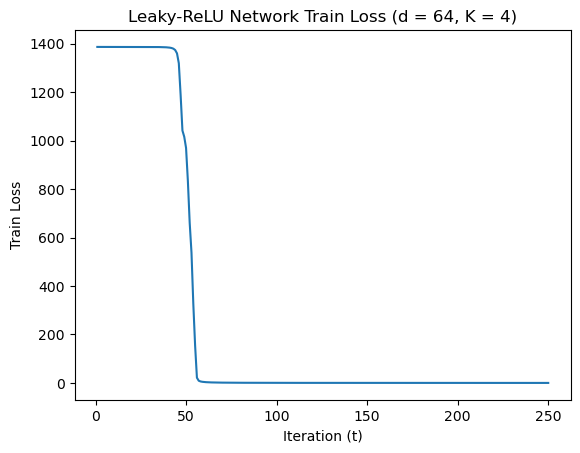

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:34:57,328 - INFO - Finish Epoch 1
2026-01-02 19:34:57,329 - INFO - Train loss: 1386.2990970611572, train accuracy: 23.6
2026-01-02 19:34:57,346 - INFO - Val loss: 1386.2925758361816, val accuracy: 25.8
2026-01-02 19:34:57,385 - INFO - Finish Epoch 2
2026-01-02 19:34:57,386 - INFO - Train loss: 1386.2950744628906, train accuracy: 24.5
2026-01-02 19:34:57,403 - INFO - Val loss: 1386.289969444275, val accuracy: 27.4
  1%|          | 2/250 [00:00<00:14, 17.57it/s]2026-01-02 19:34:57,442 - INFO - Finish Epoch 3
2026-01-02 19:34:57,443 - INFO - Train loss: 1386.2924098968506, train accuracy: 26.4
2026-01-02 19:34:57,460 - INFO - Val loss: 1386.2873620986938, val accuracy: 28.8
2026-01-02 19:34:57,498 - INFO - Finish Epoch 4
2026-01-02 19:34:57,499 - INFO - Train loss: 1386.2898235321045, train accuracy: 27.2
2026-01-02 19:34:57,516 - INFO - Val loss: 1386.2847185134888, val accuracy: 30.6
  2%|▏         | 4/250 [00:00<00:13, 17.59it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.53it/s]2026-01-02 19:35:01,230 - INFO - Finish Epoch 69
2026-01-02 19:35:01,231 - INFO - Train loss: 1.3971022078767419, train accuracy: 100.0
2026-01-02 19:35:01,248 - INFO - Val loss: 1.3268885780125856, val accuracy: 100.0
2026-01-02 19:35:01,286 - INFO - Finish Epoch 70
2026-01-02 19:35:01,287 - INFO - Train loss: 1.3114904053509235, train accuracy: 100.0
2026-01-02 19:35:01,304 - INFO - Val loss: 1.2490580286830664, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.56it/s]2026-01-02 19:35:01,343 - INFO - Finish Epoch 71
2026-01-02 19:35:01,344 - INFO - Train loss: 1.235239151865244, train accuracy: 100.0
2026-01-02 19:35:01,361 - INFO - Val loss: 1.1793768145143986, val accuracy: 100.0
2026-01-02 19:35:01,399 - INFO - Finish Epoch 72
2026-01-02 19:35:01,400 - INFO - Train loss: 1.166918721050024, train accuracy: 100.0
2026-01-02 19:35:01,417 - INFO - Val loss: 1.1166613968089223, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04

 41%|████      | 102/250 [00:05<00:08, 17.58it/s]2026-01-02 19:35:03,165 - INFO - Finish Epoch 103
2026-01-02 19:35:03,166 - INFO - Train loss: 0.4082879521884024, train accuracy: 100.0
2026-01-02 19:35:03,183 - INFO - Val loss: 0.4011557837948203, val accuracy: 100.0
2026-01-02 19:35:03,221 - INFO - Finish Epoch 104
2026-01-02 19:35:03,222 - INFO - Train loss: 0.3994019008241594, train accuracy: 100.0
2026-01-02 19:35:03,239 - INFO - Val loss: 0.39255500538274646, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.58it/s]2026-01-02 19:35:03,278 - INFO - Finish Epoch 105
2026-01-02 19:35:03,280 - INFO - Train loss: 0.3908686204813421, train accuracy: 100.0
2026-01-02 19:35:03,297 - INFO - Val loss: 0.384292121976614, val accuracy: 100.0
2026-01-02 19:35:03,335 - INFO - Finish Epoch 106
2026-01-02 19:35:03,336 - INFO - Train loss: 0.3826705012470484, train accuracy: 100.0
2026-01-02 19:35:03,353 - INFO - Val loss: 0.37634428730234504, val accuracy: 100.0
 42%|████▏     | 106/

2026-01-02 19:35:05,068 - INFO - Val loss: 0.22893619118258357, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.46it/s]2026-01-02 19:35:05,108 - INFO - Finish Epoch 137
2026-01-02 19:35:05,109 - INFO - Train loss: 0.22831012634560466, train accuracy: 100.0
2026-01-02 19:35:05,126 - INFO - Val loss: 0.2258941177278757, val accuracy: 100.0
2026-01-02 19:35:05,164 - INFO - Finish Epoch 138
2026-01-02 19:35:05,165 - INFO - Train loss: 0.22528389375656843, train accuracy: 100.0
2026-01-02 19:35:05,182 - INFO - Val loss: 0.22292624367401004, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.50it/s]2026-01-02 19:35:05,221 - INFO - Finish Epoch 139
2026-01-02 19:35:05,222 - INFO - Train loss: 0.22232732828706503, train accuracy: 100.0
2026-01-02 19:35:05,239 - INFO - Val loss: 0.2200325638987124, val accuracy: 100.0
2026-01-02 19:35:05,277 - INFO - Finish Epoch 140
2026-01-02 19:35:05,278 - INFO - Train loss: 0.21944996854290366, train accuracy: 100.0
2026-01-02 19:35

2026-01-02 19:35:06,994 - INFO - Finish Epoch 170
2026-01-02 19:35:06,995 - INFO - Train loss: 0.15693678823299706, train accuracy: 100.0
2026-01-02 19:35:07,012 - INFO - Val loss: 0.1557357630226761, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.60it/s]2026-01-02 19:35:07,051 - INFO - Finish Epoch 171
2026-01-02 19:35:07,052 - INFO - Train loss: 0.15542892937082797, train accuracy: 100.0
2026-01-02 19:35:07,069 - INFO - Val loss: 0.15425029722973704, val accuracy: 100.0
2026-01-02 19:35:07,108 - INFO - Finish Epoch 172
2026-01-02 19:35:07,109 - INFO - Train loss: 0.15394846815615892, train accuracy: 100.0
2026-01-02 19:35:07,126 - INFO - Val loss: 0.15279175667092204, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.57it/s]2026-01-02 19:35:07,166 - INFO - Finish Epoch 173
2026-01-02 19:35:07,167 - INFO - Train loss: 0.15249612159095705, train accuracy: 100.0
2026-01-02 19:35:07,184 - INFO - Val loss: 0.15135775320231915, val accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:35:08,899 - INFO - Val loss: 0.11763875256292522, val accuracy: 100.0
2026-01-02 19:35:08,938 - INFO - Finish Epoch 204
2026-01-02 19:35:08,939 - INFO - Train loss: 0.1174543978413567, train accuracy: 100.0
2026-01-02 19:35:08,956 - INFO - Val loss: 0.11675443383865058, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.45it/s]2026-01-02 19:35:08,995 - INFO - Finish Epoch 205
2026-01-02 19:35:08,996 - INFO - Train loss: 0.11657484609168023, train accuracy: 100.0
2026-01-02 19:35:09,013 - INFO - Val loss: 0.11588763061445206, val accuracy: 100.0
2026-01-02 19:35:09,051 - INFO - Finish Epoch 206
2026-01-02 19:35:09,052 - INFO - Train loss: 0.11571078223641962, train accuracy: 100.0
2026-01-02 19:35:09,069 - INFO - Val loss: 0.11502785503398627, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.51it/s]2026-01-02 19:35:09,109 - INFO - Finish Epoch 207
2026-01-02 19:35:09,110 - INFO - Train loss: 0.11485470121260732, train accuracy: 100.0
2026-01-02 19:3

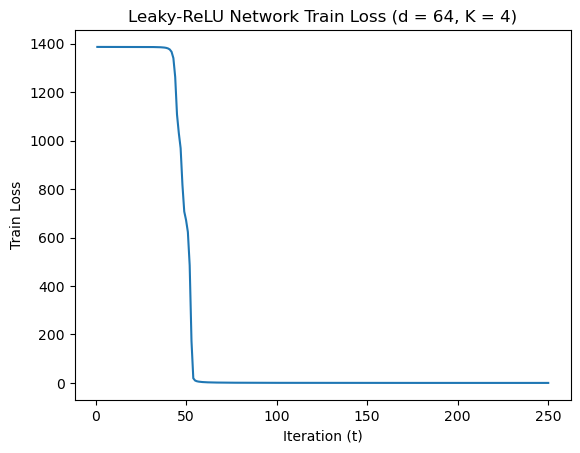

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:35:11,898 - INFO - Finish Epoch 1
2026-01-02 19:35:11,899 - INFO - Train loss: 1386.2952270507812, train accuracy: 19.3
2026-01-02 19:35:11,916 - INFO - Val loss: 1386.2898426055908, val accuracy: 25.4
2026-01-02 19:35:11,956 - INFO - Finish Epoch 2
2026-01-02 19:35:11,957 - INFO - Train loss: 1386.2923212051392, train accuracy: 22.6
2026-01-02 19:35:11,975 - INFO - Val loss: 1386.2875986099243, val accuracy: 27.7
  1%|          | 2/250 [00:00<00:14, 17.13it/s]2026-01-02 19:35:12,015 - INFO - Finish Epoch 3
2026-01-02 19:35:12,016 - INFO - Train loss: 1386.2900428771973, train accuracy: 25.5
2026-01-02 19:35:12,034 - INFO - Val loss: 1386.2852802276611, val accuracy: 30.2
2026-01-02 19:35:12,073 - INFO - Finish Epoch 4
2026-01-02 19:35:12,074 - INFO - Train loss: 1386.28773021698, train accuracy: 27.6
2026-01-02 19:35:12,092 - INFO - Val loss: 1386.2829084396362, val accuracy: 32.9
  2%|▏         | 4/250 [00:00<00:14, 17.11it/s]2026-

 27%|██▋       | 68/250 [00:04<00:10, 17.35it/s]2026-01-02 19:35:15,965 - INFO - Finish Epoch 69
2026-01-02 19:35:15,966 - INFO - Train loss: 1.4048227909952402, train accuracy: 100.0
2026-01-02 19:35:15,983 - INFO - Val loss: 1.3417989276349545, val accuracy: 100.0
2026-01-02 19:35:16,022 - INFO - Finish Epoch 70
2026-01-02 19:35:16,023 - INFO - Train loss: 1.3183506396599114, train accuracy: 100.0
2026-01-02 19:35:16,040 - INFO - Val loss: 1.2621432626619935, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.38it/s]2026-01-02 19:35:16,079 - INFO - Finish Epoch 71
2026-01-02 19:35:16,081 - INFO - Train loss: 1.2412379970774055, train accuracy: 100.0
2026-01-02 19:35:16,097 - INFO - Val loss: 1.1908207517117262, val accuracy: 100.0
2026-01-02 19:35:16,136 - INFO - Finish Epoch 72
2026-01-02 19:35:16,137 - INFO - Train loss: 1.1720885946415365, train accuracy: 100.0
2026-01-02 19:35:16,154 - INFO - Val loss: 1.126609679311514, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:06<00:08, 17.52it/s]2026-01-02 19:35:17,906 - INFO - Finish Epoch 103
2026-01-02 19:35:17,908 - INFO - Train loss: 0.4048634839709848, train accuracy: 100.0
2026-01-02 19:35:17,924 - INFO - Val loss: 0.3983073777053505, val accuracy: 100.0
2026-01-02 19:35:17,963 - INFO - Finish Epoch 104
2026-01-02 19:35:17,964 - INFO - Train loss: 0.3959479371551424, train accuracy: 100.0
2026-01-02 19:35:17,981 - INFO - Val loss: 0.3896511357743293, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.53it/s]2026-01-02 19:35:18,021 - INFO - Finish Epoch 105
2026-01-02 19:35:18,023 - INFO - Train loss: 0.38738965056836605, train accuracy: 100.0
2026-01-02 19:35:18,039 - INFO - Val loss: 0.38133966946043074, val accuracy: 100.0
2026-01-02 19:35:18,078 - INFO - Finish Epoch 106
2026-01-02 19:35:18,079 - INFO - Train loss: 0.37916709668934345, train accuracy: 100.0
2026-01-02 19:35:18,095 - INFO - Val loss: 0.37335180619265884, val accuracy: 100.0
 42%|████▏     | 1

2026-01-02 19:35:19,810 - INFO - Val loss: 0.22560159879503772, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.43it/s]2026-01-02 19:35:19,850 - INFO - Finish Epoch 137
2026-01-02 19:35:19,851 - INFO - Train loss: 0.2247944868868217, train accuracy: 100.0
2026-01-02 19:35:19,869 - INFO - Val loss: 0.22255933564156294, val accuracy: 100.0
2026-01-02 19:35:19,908 - INFO - Finish Epoch 138
2026-01-02 19:35:19,909 - INFO - Train loss: 0.22177413536701351, train accuracy: 100.0
2026-01-02 19:35:19,930 - INFO - Val loss: 0.21959078108193353, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:08<00:06, 17.22it/s]2026-01-02 19:35:19,971 - INFO - Finish Epoch 139
2026-01-02 19:35:19,972 - INFO - Train loss: 0.2188265521544963, train accuracy: 100.0
2026-01-02 19:35:19,990 - INFO - Val loss: 0.21670059947064146, val accuracy: 100.0
2026-01-02 19:35:20,030 - INFO - Finish Epoch 140
2026-01-02 19:35:20,031 - INFO - Train loss: 0.21595280012115836, train accuracy: 100.0
2026-01-02 19:35

2026-01-02 19:35:21,747 - INFO - Finish Epoch 170
2026-01-02 19:35:21,748 - INFO - Train loss: 0.1538231048907619, train accuracy: 100.0
2026-01-02 19:35:21,764 - INFO - Val loss: 0.15271275286795571, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.50it/s]2026-01-02 19:35:21,804 - INFO - Finish Epoch 171
2026-01-02 19:35:21,805 - INFO - Train loss: 0.15232597786234692, train accuracy: 100.0
2026-01-02 19:35:21,821 - INFO - Val loss: 0.1512395735771861, val accuracy: 100.0
2026-01-02 19:35:21,860 - INFO - Finish Epoch 172
2026-01-02 19:35:21,861 - INFO - Train loss: 0.15085899276891723, train accuracy: 100.0
2026-01-02 19:35:21,878 - INFO - Val loss: 0.14979152951855212, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 17.54it/s]2026-01-02 19:35:21,917 - INFO - Finish Epoch 173
2026-01-02 19:35:21,918 - INFO - Train loss: 0.14942107474780641, train accuracy: 100.0
2026-01-02 19:35:21,935 - INFO - Val loss: 0.14836695036501624, val accuracy: 100.0
2026-01-02 19:35

2026-01-02 19:35:23,623 - INFO - Train loss: 0.1156599770183675, train accuracy: 100.0
2026-01-02 19:35:23,640 - INFO - Val loss: 0.11500827566487715, val accuracy: 100.0
2026-01-02 19:35:23,679 - INFO - Finish Epoch 204
2026-01-02 19:35:23,680 - INFO - Train loss: 0.11478400777559727, train accuracy: 100.0
2026-01-02 19:35:23,697 - INFO - Val loss: 0.11413790652295575, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.59it/s]2026-01-02 19:35:23,737 - INFO - Finish Epoch 205
2026-01-02 19:35:23,738 - INFO - Train loss: 0.11391851989901625, train accuracy: 100.0
2026-01-02 19:35:23,755 - INFO - Val loss: 0.11327909061219543, val accuracy: 100.0
2026-01-02 19:35:23,793 - INFO - Finish Epoch 206
2026-01-02 19:35:23,794 - INFO - Train loss: 0.11306018228060566, train accuracy: 100.0
2026-01-02 19:35:23,811 - INFO - Val loss: 0.11242992465849966, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.57it/s]2026-01-02 19:35:23,851 - INFO - Finish Epoch 207
2026-01-02 19:3

 94%|█████████▍| 236/250 [00:13<00:00, 17.68it/s]2026-01-02 19:35:25,552 - INFO - Finish Epoch 237
2026-01-02 19:35:25,553 - INFO - Train loss: 0.09146669681649655, train accuracy: 100.0
2026-01-02 19:35:25,569 - INFO - Val loss: 0.0910453082760796, val accuracy: 100.0
2026-01-02 19:35:25,607 - INFO - Finish Epoch 238
2026-01-02 19:35:25,608 - INFO - Train loss: 0.09089777022018097, train accuracy: 100.0
2026-01-02 19:35:25,625 - INFO - Val loss: 0.09047888172790408, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.71it/s]2026-01-02 19:35:25,664 - INFO - Finish Epoch 239
2026-01-02 19:35:25,665 - INFO - Train loss: 0.09033909026766196, train accuracy: 100.0
2026-01-02 19:35:25,682 - INFO - Val loss: 0.08992377723916434, val accuracy: 100.0
2026-01-02 19:35:25,720 - INFO - Finish Epoch 240
2026-01-02 19:35:25,721 - INFO - Train loss: 0.08978255378315225, train accuracy: 100.0
2026-01-02 19:35:25,737 - INFO - Val loss: 0.0893749882816337, val accuracy: 100.0
 96%|█████████▌|

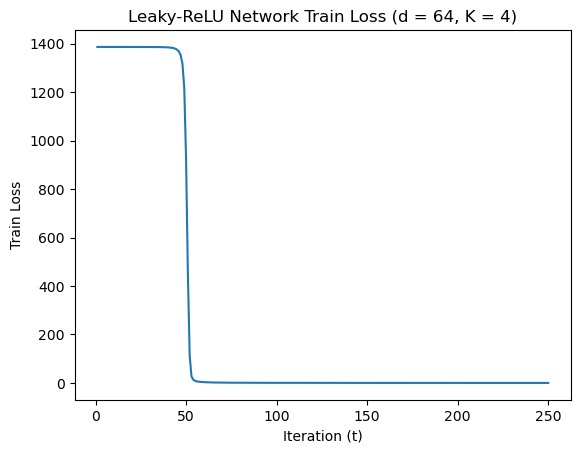

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:35:26,637 - INFO - Finish Epoch 1
2026-01-02 19:35:26,638 - INFO - Train loss: 1386.3019285202026, train accuracy: 24.3
2026-01-02 19:35:26,655 - INFO - Val loss: 1386.295937538147, val accuracy: 26.3
2026-01-02 19:35:26,693 - INFO - Finish Epoch 2
2026-01-02 19:35:26,695 - INFO - Train loss: 1386.298635482788, train accuracy: 25.7
2026-01-02 19:35:26,712 - INFO - Val loss: 1386.2938709259033, val accuracy: 26.5
  1%|          | 2/250 [00:00<00:14, 17.58it/s]2026-01-02 19:35:26,751 - INFO - Finish Epoch 3
2026-01-02 19:35:26,752 - INFO - Train loss: 1386.296513557434, train accuracy: 26.0
2026-01-02 19:35:26,769 - INFO - Val loss: 1386.2918491363525, val accuracy: 26.7
2026-01-02 19:35:26,811 - INFO - Finish Epoch 4
2026-01-02 19:35:26,812 - INFO - Train loss: 1386.2944736480713, train accuracy: 26.1
2026-01-02 19:35:26,829 - INFO - Val loss: 1386.2898693084717, val accuracy: 27.0
  2%|▏         | 4/250 [00:00<00:14, 17.24it/s]2026-0

 27%|██▋       | 68/250 [00:03<00:10, 17.45it/s]2026-01-02 19:35:30,561 - INFO - Finish Epoch 69
2026-01-02 19:35:30,562 - INFO - Train loss: 6.228341035544872, train accuracy: 100.0
2026-01-02 19:35:30,578 - INFO - Val loss: 5.324732795357704, val accuracy: 100.0
2026-01-02 19:35:30,617 - INFO - Finish Epoch 70
2026-01-02 19:35:30,618 - INFO - Train loss: 4.657146159559488, train accuracy: 100.0
2026-01-02 19:35:30,635 - INFO - Val loss: 4.109829798340797, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.46it/s]2026-01-02 19:35:30,676 - INFO - Finish Epoch 71
2026-01-02 19:35:30,677 - INFO - Train loss: 3.7185575123876333, train accuracy: 100.0
2026-01-02 19:35:30,694 - INFO - Val loss: 3.3512426260858774, val accuracy: 100.0
2026-01-02 19:35:30,734 - INFO - Finish Epoch 72
2026-01-02 19:35:30,735 - INFO - Train loss: 3.0937997736036777, train accuracy: 100.0
2026-01-02 19:35:30,752 - INFO - Val loss: 2.8290034625679255, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<0

 41%|████      | 102/250 [00:05<00:08, 17.35it/s]2026-01-02 19:35:32,517 - INFO - Finish Epoch 103
2026-01-02 19:35:32,519 - INFO - Train loss: 0.46505392296239734, train accuracy: 100.0
2026-01-02 19:35:32,536 - INFO - Val loss: 0.45629126159474254, val accuracy: 100.0
2026-01-02 19:35:32,574 - INFO - Finish Epoch 104
2026-01-02 19:35:32,575 - INFO - Train loss: 0.4518590741790831, train accuracy: 100.0
2026-01-02 19:35:32,592 - INFO - Val loss: 0.44354676315560937, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.36it/s]2026-01-02 19:35:32,632 - INFO - Finish Epoch 105
2026-01-02 19:35:32,633 - INFO - Train loss: 0.4393563778139651, train accuracy: 100.0
2026-01-02 19:35:32,650 - INFO - Val loss: 0.431456970050931, val accuracy: 100.0
2026-01-02 19:35:32,689 - INFO - Finish Epoch 106
2026-01-02 19:35:32,690 - INFO - Train loss: 0.42749329190701246, train accuracy: 100.0
2026-01-02 19:35:32,706 - INFO - Val loss: 0.41997714107856154, val accuracy: 100.0
 42%|████▏     | 1

2026-01-02 19:35:34,438 - INFO - Val loss: 0.22952328075189143, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.31it/s]2026-01-02 19:35:34,478 - INFO - Finish Epoch 137
2026-01-02 19:35:34,479 - INFO - Train loss: 0.22838984767440706, train accuracy: 100.0
2026-01-02 19:35:34,496 - INFO - Val loss: 0.22599310555960983, val accuracy: 100.0
2026-01-02 19:35:34,535 - INFO - Finish Epoch 138
2026-01-02 19:35:34,536 - INFO - Train loss: 0.22489063581451774, train accuracy: 100.0
2026-01-02 19:35:34,553 - INFO - Val loss: 0.2225641671102494, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.33it/s]2026-01-02 19:35:34,593 - INFO - Finish Epoch 139
2026-01-02 19:35:34,594 - INFO - Train loss: 0.2214956395328045, train accuracy: 100.0
2026-01-02 19:35:34,611 - INFO - Val loss: 0.21922908490523696, val accuracy: 100.0
2026-01-02 19:35:34,650 - INFO - Finish Epoch 140
2026-01-02 19:35:34,651 - INFO - Train loss: 0.2181889060884714, train accuracy: 100.0
2026-01-02 19:35:

2026-01-02 19:35:36,385 - INFO - Finish Epoch 170
2026-01-02 19:35:36,386 - INFO - Train loss: 0.14957475196570158, train accuracy: 100.0
2026-01-02 19:35:36,403 - INFO - Val loss: 0.148475008783862, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.41it/s]2026-01-02 19:35:36,442 - INFO - Finish Epoch 171
2026-01-02 19:35:36,443 - INFO - Train loss: 0.14799003535881639, train accuracy: 100.0
2026-01-02 19:35:36,460 - INFO - Val loss: 0.14690982666797936, val accuracy: 100.0
2026-01-02 19:35:36,500 - INFO - Finish Epoch 172
2026-01-02 19:35:36,501 - INFO - Train loss: 0.14643116830848157, train accuracy: 100.0
2026-01-02 19:35:36,519 - INFO - Val loss: 0.1453733627567999, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.36it/s]2026-01-02 19:35:36,558 - INFO - Finish Epoch 173
2026-01-02 19:35:36,560 - INFO - Train loss: 0.1449084016494453, train accuracy: 100.0
2026-01-02 19:35:36,577 - INFO - Val loss: 0.14386917726369575, val accuracy: 100.0
2026-01-02 19:35:3

2026-01-02 19:35:38,308 - INFO - Val loss: 0.10926179436501116, val accuracy: 100.0
2026-01-02 19:35:38,346 - INFO - Finish Epoch 204
2026-01-02 19:35:38,347 - INFO - Train loss: 0.10899354258435778, train accuracy: 100.0
2026-01-02 19:35:38,364 - INFO - Val loss: 0.10837538845953532, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.47it/s]2026-01-02 19:35:38,403 - INFO - Finish Epoch 205
2026-01-02 19:35:38,404 - INFO - Train loss: 0.10811309167183936, train accuracy: 100.0
2026-01-02 19:35:38,421 - INFO - Val loss: 0.10750506783369929, val accuracy: 100.0
2026-01-02 19:35:38,460 - INFO - Finish Epoch 206
2026-01-02 19:35:38,461 - INFO - Train loss: 0.10724193838541396, train accuracy: 100.0
2026-01-02 19:35:38,477 - INFO - Val loss: 0.10664571012603119, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.53it/s]2026-01-02 19:35:38,517 - INFO - Finish Epoch 207
2026-01-02 19:35:38,518 - INFO - Train loss: 0.1063893722021021, train accuracy: 100.0
2026-01-02 19:3

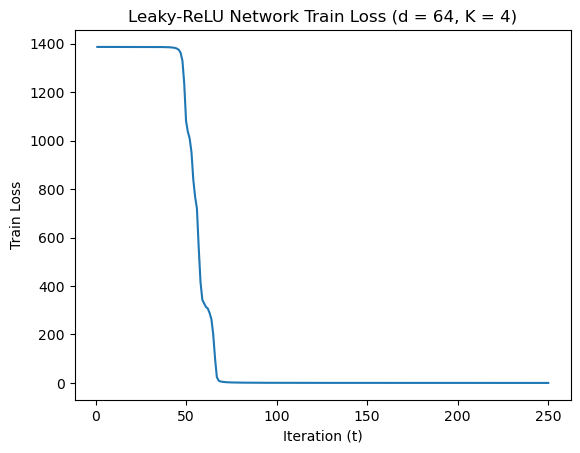

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:35:41,326 - INFO - Finish Epoch 1
2026-01-02 19:35:41,327 - INFO - Train loss: 1386.298355102539, train accuracy: 22.1
2026-01-02 19:35:41,344 - INFO - Val loss: 1386.2931985855103, val accuracy: 26.7
2026-01-02 19:35:41,383 - INFO - Finish Epoch 2
2026-01-02 19:35:41,384 - INFO - Train loss: 1386.2952966690063, train accuracy: 24.9
2026-01-02 19:35:41,401 - INFO - Val loss: 1386.2912092208862, val accuracy: 28.7
  1%|          | 2/250 [00:00<00:14, 17.51it/s]2026-01-02 19:35:41,441 - INFO - Finish Epoch 3
2026-01-02 19:35:41,442 - INFO - Train loss: 1386.2932682037354, train accuracy: 27.0
2026-01-02 19:35:41,459 - INFO - Val loss: 1386.2892150878906, val accuracy: 31.4
2026-01-02 19:35:41,498 - INFO - Finish Epoch 4
2026-01-02 19:35:41,499 - INFO - Train loss: 1386.2912788391113, train accuracy: 29.5
2026-01-02 19:35:41,516 - INFO - Val loss: 1386.2871913909912, val accuracy: 33.7
  2%|▏         | 4/250 [00:00<00:14, 17.50it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.45it/s]2026-01-02 19:35:45,242 - INFO - Finish Epoch 69
2026-01-02 19:35:45,243 - INFO - Train loss: 1.6187720969319344, train accuracy: 100.0
2026-01-02 19:35:45,260 - INFO - Val loss: 1.5347551107406616, val accuracy: 100.0
2026-01-02 19:35:45,298 - INFO - Finish Epoch 70
2026-01-02 19:35:45,299 - INFO - Train loss: 1.4966868292540312, train accuracy: 100.0
2026-01-02 19:35:45,315 - INFO - Val loss: 1.4237111955881119, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.54it/s]2026-01-02 19:35:45,354 - INFO - Finish Epoch 71
2026-01-02 19:35:45,355 - INFO - Train loss: 1.3907349780201912, train accuracy: 100.0
2026-01-02 19:35:45,372 - INFO - Val loss: 1.3268175832927227, val accuracy: 100.0
2026-01-02 19:35:45,410 - INFO - Finish Epoch 72
2026-01-02 19:35:45,411 - INFO - Train loss: 1.2979908026754856, train accuracy: 100.0
2026-01-02 19:35:45,428 - INFO - Val loss: 1.241557877510786, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:05<00:08, 17.57it/s]2026-01-02 19:35:47,177 - INFO - Finish Epoch 103
2026-01-02 19:35:47,178 - INFO - Train loss: 0.3961369302123785, train accuracy: 100.0
2026-01-02 19:35:47,195 - INFO - Val loss: 0.3896525423042476, val accuracy: 100.0
2026-01-02 19:35:47,234 - INFO - Finish Epoch 104
2026-01-02 19:35:47,235 - INFO - Train loss: 0.38687855703756213, train accuracy: 100.0
2026-01-02 19:35:47,252 - INFO - Val loss: 0.3806740753352642, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.55it/s]2026-01-02 19:35:47,291 - INFO - Finish Epoch 105
2026-01-02 19:35:47,292 - INFO - Train loss: 0.37801579432561994, train accuracy: 100.0
2026-01-02 19:35:47,309 - INFO - Val loss: 0.3720695534721017, val accuracy: 100.0
2026-01-02 19:35:47,349 - INFO - Finish Epoch 106
2026-01-02 19:35:47,351 - INFO - Train loss: 0.36953056417405605, train accuracy: 100.0
2026-01-02 19:35:47,368 - INFO - Val loss: 0.36383044719696045, val accuracy: 100.0
 42%|████▏     | 1

2026-01-02 19:35:49,088 - INFO - Val loss: 0.21519690682180226, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.50it/s]2026-01-02 19:35:49,127 - INFO - Finish Epoch 137
2026-01-02 19:35:49,128 - INFO - Train loss: 0.21430560597218573, train accuracy: 100.0
2026-01-02 19:35:49,145 - INFO - Val loss: 0.212212348356843, val accuracy: 100.0
2026-01-02 19:35:49,184 - INFO - Finish Epoch 138
2026-01-02 19:35:49,185 - INFO - Train loss: 0.2113452209159732, train accuracy: 100.0
2026-01-02 19:35:49,202 - INFO - Val loss: 0.2093046037480235, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.51it/s]2026-01-02 19:35:49,241 - INFO - Finish Epoch 139
2026-01-02 19:35:49,242 - INFO - Train loss: 0.20845844154246151, train accuracy: 100.0
2026-01-02 19:35:49,259 - INFO - Val loss: 0.20646986877545714, val accuracy: 100.0
2026-01-02 19:35:49,298 - INFO - Finish Epoch 140
2026-01-02 19:35:49,299 - INFO - Train loss: 0.20564252487383783, train accuracy: 100.0
2026-01-02 19:35:4

2026-01-02 19:35:51,025 - INFO - Finish Epoch 170
2026-01-02 19:35:51,026 - INFO - Train loss: 0.14534935192205012, train accuracy: 100.0
2026-01-02 19:35:51,043 - INFO - Val loss: 0.14433122938498855, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.34it/s]2026-01-02 19:35:51,083 - INFO - Finish Epoch 171
2026-01-02 19:35:51,084 - INFO - Train loss: 0.143914278363809, train accuracy: 100.0
2026-01-02 19:35:51,102 - INFO - Val loss: 0.14291164092719555, val accuracy: 100.0
2026-01-02 19:35:51,141 - INFO - Finish Epoch 172
2026-01-02 19:35:51,142 - INFO - Train loss: 0.1425001723691821, train accuracy: 100.0
2026-01-02 19:35:51,160 - INFO - Val loss: 0.1415187418460846, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.29it/s]2026-01-02 19:35:51,200 - INFO - Finish Epoch 173
2026-01-02 19:35:51,201 - INFO - Train loss: 0.14111525053158402, train accuracy: 100.0
2026-01-02 19:35:51,219 - INFO - Val loss: 0.14015121129341424, val accuracy: 100.0
2026-01-02 19:35:5

2026-01-02 19:35:52,937 - INFO - Val loss: 0.10822075535543263, val accuracy: 100.0
2026-01-02 19:35:52,976 - INFO - Finish Epoch 204
2026-01-02 19:35:52,977 - INFO - Train loss: 0.10797954839654267, train accuracy: 100.0
2026-01-02 19:35:52,994 - INFO - Val loss: 0.10739112738519907, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.34it/s]2026-01-02 19:35:53,034 - INFO - Finish Epoch 205
2026-01-02 19:35:53,035 - INFO - Train loss: 0.10715445119421929, train accuracy: 100.0
2026-01-02 19:35:53,052 - INFO - Val loss: 0.10657424700912088, val accuracy: 100.0
2026-01-02 19:35:53,089 - INFO - Finish Epoch 206
2026-01-02 19:35:53,091 - INFO - Train loss: 0.10634114337153733, train accuracy: 100.0
2026-01-02 19:35:53,108 - INFO - Val loss: 0.10577249992638826, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.43it/s]2026-01-02 19:35:53,147 - INFO - Finish Epoch 207
2026-01-02 19:35:53,148 - INFO - Train loss: 0.10554046812467277, train accuracy: 100.0
2026-01-02 19:

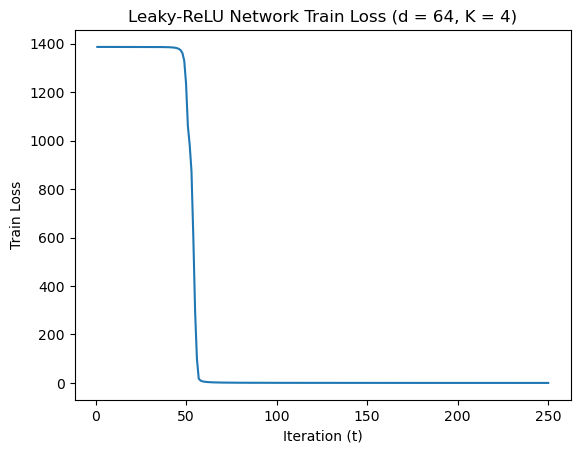

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:35:56,087 - INFO - Finish Epoch 1
2026-01-02 19:35:56,088 - INFO - Train loss: 1386.3011493682861, train accuracy: 24.9
2026-01-02 19:35:56,106 - INFO - Val loss: 1386.2940979003906, val accuracy: 31.3
2026-01-02 19:35:56,145 - INFO - Finish Epoch 2
2026-01-02 19:35:56,146 - INFO - Train loss: 1386.2970943450928, train accuracy: 27.0
2026-01-02 19:35:56,163 - INFO - Val loss: 1386.2916374206543, val accuracy: 33.5
  1%|          | 2/250 [00:00<00:14, 17.18it/s]2026-01-02 19:35:56,204 - INFO - Finish Epoch 3
2026-01-02 19:35:56,205 - INFO - Train loss: 1386.2946014404297, train accuracy: 29.9
2026-01-02 19:35:56,222 - INFO - Val loss: 1386.289174079895, val accuracy: 35.6
2026-01-02 19:35:56,261 - INFO - Finish Epoch 4
2026-01-02 19:35:56,262 - INFO - Train loss: 1386.2921743392944, train accuracy: 32.3
2026-01-02 19:35:56,280 - INFO - Val loss: 1386.2867059707642, val accuracy: 37.1
  2%|▏         | 4/250 [00:00<00:14, 17.19it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.67it/s]2026-01-02 19:35:59,973 - INFO - Finish Epoch 69
2026-01-02 19:35:59,974 - INFO - Train loss: 1.3276246972382069, train accuracy: 100.0
2026-01-02 19:35:59,991 - INFO - Val loss: 1.270819904282689, val accuracy: 100.0
2026-01-02 19:36:00,029 - INFO - Finish Epoch 70
2026-01-02 19:36:00,030 - INFO - Train loss: 1.241439014673233, train accuracy: 100.0
2026-01-02 19:36:00,047 - INFO - Val loss: 1.1910777427256107, val accuracy: 100.0
 28%|██▊       | 70/250 [00:03<00:10, 17.68it/s]2026-01-02 19:36:00,086 - INFO - Finish Epoch 71
2026-01-02 19:36:00,087 - INFO - Train loss: 1.1652713026851416, train accuracy: 100.0
2026-01-02 19:36:00,104 - INFO - Val loss: 1.1203290596604347, val accuracy: 100.0
2026-01-02 19:36:00,142 - INFO - Finish Epoch 72
2026-01-02 19:36:00,143 - INFO - Train loss: 1.097494582645595, train accuracy: 100.0
2026-01-02 19:36:00,160 - INFO - Val loss: 1.057142609730363, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<0

 41%|████      | 102/250 [00:05<00:08, 17.53it/s]2026-01-02 19:36:01,914 - INFO - Finish Epoch 103
2026-01-02 19:36:01,915 - INFO - Train loss: 0.37226552516222, train accuracy: 100.0
2026-01-02 19:36:01,932 - INFO - Val loss: 0.3665679399855435, val accuracy: 100.0
2026-01-02 19:36:01,970 - INFO - Finish Epoch 104
2026-01-02 19:36:01,971 - INFO - Train loss: 0.3640503156930208, train accuracy: 100.0
2026-01-02 19:36:01,988 - INFO - Val loss: 0.3585749655030668, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.55it/s]2026-01-02 19:36:02,027 - INFO - Finish Epoch 105
2026-01-02 19:36:02,028 - INFO - Train loss: 0.3561626961454749, train accuracy: 100.0
2026-01-02 19:36:02,045 - INFO - Val loss: 0.3509074575267732, val accuracy: 100.0
2026-01-02 19:36:02,084 - INFO - Finish Epoch 106
2026-01-02 19:36:02,085 - INFO - Train loss: 0.34859102172777057, train accuracy: 100.0
2026-01-02 19:36:02,102 - INFO - Val loss: 0.34353720489889383, val accuracy: 100.0
 42%|████▏     | 106/2

2026-01-02 19:36:03,803 - INFO - Val loss: 0.2078292164951563, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.54it/s]2026-01-02 19:36:03,842 - INFO - Finish Epoch 137
2026-01-02 19:36:03,843 - INFO - Train loss: 0.20699127856642008, train accuracy: 100.0
2026-01-02 19:36:03,860 - INFO - Val loss: 0.20504812197759748, val accuracy: 100.0
2026-01-02 19:36:03,898 - INFO - Finish Epoch 138
2026-01-02 19:36:03,899 - INFO - Train loss: 0.20423031318932772, train accuracy: 100.0
2026-01-02 19:36:03,916 - INFO - Val loss: 0.20233086217194796, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.56it/s]2026-01-02 19:36:03,955 - INFO - Finish Epoch 139
2026-01-02 19:36:03,956 - INFO - Train loss: 0.2015333087183535, train accuracy: 100.0
2026-01-02 19:36:03,973 - INFO - Val loss: 0.19968197424896061, val accuracy: 100.0
2026-01-02 19:36:04,011 - INFO - Finish Epoch 140
2026-01-02 19:36:04,013 - INFO - Train loss: 0.19890848197974265, train accuracy: 100.0
2026-01-02 19:36

2026-01-02 19:36:05,713 - INFO - Finish Epoch 170
2026-01-02 19:36:05,714 - INFO - Train loss: 0.14203685254324228, train accuracy: 100.0
2026-01-02 19:36:05,731 - INFO - Val loss: 0.14106094115413725, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.66it/s]2026-01-02 19:36:05,770 - INFO - Finish Epoch 171
2026-01-02 19:36:05,771 - INFO - Train loss: 0.1406641297508031, train accuracy: 100.0
2026-01-02 19:36:05,788 - INFO - Val loss: 0.1397114486899227, val accuracy: 100.0
2026-01-02 19:36:05,826 - INFO - Finish Epoch 172
2026-01-02 19:36:05,827 - INFO - Train loss: 0.13932440569624305, train accuracy: 100.0
2026-01-02 19:36:05,844 - INFO - Val loss: 0.13838351622689515, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.67it/s]2026-01-02 19:36:05,883 - INFO - Finish Epoch 173
2026-01-02 19:36:05,884 - INFO - Train loss: 0.1380019570933655, train accuracy: 100.0
2026-01-02 19:36:05,901 - INFO - Val loss: 0.13708060595672578, val accuracy: 100.0
2026-01-02 19:36:

2026-01-02 19:36:07,599 - INFO - Train loss: 0.10704259702470154, train accuracy: 100.0
2026-01-02 19:36:07,616 - INFO - Val loss: 0.10646640649065375, val accuracy: 100.0
2026-01-02 19:36:07,654 - INFO - Finish Epoch 204
2026-01-02 19:36:07,655 - INFO - Train loss: 0.10623580729588866, train accuracy: 100.0
2026-01-02 19:36:07,672 - INFO - Val loss: 0.10566867352463305, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.49it/s]2026-01-02 19:36:07,711 - INFO - Finish Epoch 205
2026-01-02 19:36:07,712 - INFO - Train loss: 0.10543878749012947, train accuracy: 100.0
2026-01-02 19:36:07,729 - INFO - Val loss: 0.10487892339006066, val accuracy: 100.0
2026-01-02 19:36:07,767 - INFO - Finish Epoch 206
2026-01-02 19:36:07,768 - INFO - Train loss: 0.10465344483964145, train accuracy: 100.0
2026-01-02 19:36:07,786 - INFO - Val loss: 0.1040990628534928, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.52it/s]2026-01-02 19:36:07,825 - INFO - Finish Epoch 207
2026-01-02 19:3

2026-01-02 19:36:09,482 - INFO - Val loss: 0.08496669086162001, val accuracy: 100.0
 94%|█████████▍| 236/250 [00:13<00:00, 17.72it/s]2026-01-02 19:36:09,521 - INFO - Finish Epoch 237
2026-01-02 19:36:09,522 - INFO - Train loss: 0.08481544943060726, train accuracy: 100.0
2026-01-02 19:36:09,538 - INFO - Val loss: 0.08444087533280253, val accuracy: 100.0
2026-01-02 19:36:09,577 - INFO - Finish Epoch 238
2026-01-02 19:36:09,578 - INFO - Train loss: 0.0842945235199295, train accuracy: 100.0
2026-01-02 19:36:09,594 - INFO - Val loss: 0.08392757491674274, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.72it/s]2026-01-02 19:36:09,633 - INFO - Finish Epoch 239
2026-01-02 19:36:09,635 - INFO - Train loss: 0.08378014818299562, train accuracy: 100.0
2026-01-02 19:36:09,651 - INFO - Val loss: 0.08341653604293242, val accuracy: 100.0
2026-01-02 19:36:09,689 - INFO - Finish Epoch 240
2026-01-02 19:36:09,690 - INFO - Train loss: 0.08326910925097764, train accuracy: 100.0
2026-01-02 19:3

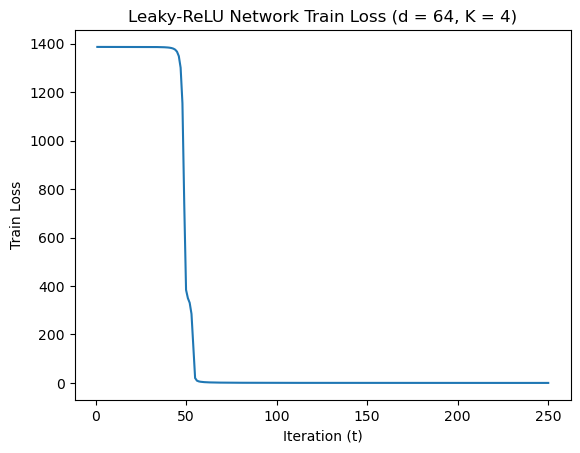

===== ACTIVATION FUNCTION:  ReLU  =====
=== TRIAL 0 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:36:10,620 - INFO - Finish Epoch 1
2026-01-02 19:36:10,621 - INFO - Train loss: 1386.3003616333008, train accuracy: 15.4
2026-01-02 19:36:10,638 - INFO - Val loss: 1386.2933053970337, val accuracy: 21.7
2026-01-02 19:36:10,677 - INFO - Finish Epoch 2
2026-01-02 19:36:10,678 - INFO - Train loss: 1386.2962646484375, train accuracy: 19.2
2026-01-02 19:36:10,696 - INFO - Val loss: 1386.2907066345215, val accuracy: 24.6
  1%|          | 2/250 [00:00<00:14, 17.30it/s]2026-01-02 19:36:10,736 - INFO - Finish Epoch 3
2026-01-02 19:36:10,737 - INFO - Train loss: 1386.2935428619385, train accuracy: 21.9
2026-01-02 19:36:10,754 - INFO - Val loss: 1386.2881031036377, val accuracy: 26.3
2026-01-02 19:36:10,793 - INFO - Finish Epoch 4
2026-01-02 19:36:10,794 - INFO - Train loss: 1386.2909355163574, train accuracy: 24.0
2026-01-02 19:36:10,811 - INFO - Val loss: 1386.285472869873, val accuracy: 28.4
  2%|▏         | 4/250 [00:00<00:14, 17.34it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.24it/s]2026-01-02 19:36:14,543 - INFO - Finish Epoch 69
2026-01-02 19:36:14,544 - INFO - Train loss: 1.2399584429804236, train accuracy: 100.0
2026-01-02 19:36:14,561 - INFO - Val loss: 1.1802780290599912, val accuracy: 100.0
2026-01-02 19:36:14,600 - INFO - Finish Epoch 70
2026-01-02 19:36:14,601 - INFO - Train loss: 1.1608063590247184, train accuracy: 100.0
2026-01-02 19:36:14,621 - INFO - Val loss: 1.108014480676502, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.17it/s]2026-01-02 19:36:14,662 - INFO - Finish Epoch 71
2026-01-02 19:36:14,663 - INFO - Train loss: 1.0906993767712265, train accuracy: 100.0
2026-01-02 19:36:14,680 - INFO - Val loss: 1.0436887913383543, val accuracy: 100.0
2026-01-02 19:36:14,720 - INFO - Finish Epoch 72
2026-01-02 19:36:14,721 - INFO - Train loss: 1.0282045197673142, train accuracy: 100.0
2026-01-02 19:36:14,738 - INFO - Val loss: 0.9860727111808956, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

2026-01-02 19:36:16,461 - INFO - Val loss: 0.35458030295558274, val accuracy: 100.0
 41%|████      | 102/250 [00:05<00:08, 17.49it/s]2026-01-02 19:36:16,501 - INFO - Finish Epoch 103
2026-01-02 19:36:16,502 - INFO - Train loss: 0.3525225999765098, train accuracy: 100.0
2026-01-02 19:36:16,519 - INFO - Val loss: 0.3467719848267734, val accuracy: 100.0
2026-01-02 19:36:16,558 - INFO - Finish Epoch 104
2026-01-02 19:36:16,559 - INFO - Train loss: 0.34480369079392403, train accuracy: 100.0
2026-01-02 19:36:16,576 - INFO - Val loss: 0.33928715833462775, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.49it/s]2026-01-02 19:36:16,615 - INFO - Finish Epoch 105
2026-01-02 19:36:16,616 - INFO - Train loss: 0.3373961293254979, train accuracy: 100.0
2026-01-02 19:36:16,633 - INFO - Val loss: 0.33209667791379616, val accuracy: 100.0
2026-01-02 19:36:16,672 - INFO - Finish Epoch 106
2026-01-02 19:36:16,673 - INFO - Train loss: 0.3302776792552322, train accuracy: 100.0
2026-01-02 19:36:1

2026-01-02 19:36:18,382 - INFO - Finish Epoch 136
2026-01-02 19:36:18,383 - INFO - Train loss: 0.1997094122634735, train accuracy: 100.0
2026-01-02 19:36:18,400 - INFO - Val loss: 0.19772385005489923, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.50it/s]2026-01-02 19:36:18,439 - INFO - Finish Epoch 137
2026-01-02 19:36:18,440 - INFO - Train loss: 0.19703912700060755, train accuracy: 100.0
2026-01-02 19:36:18,457 - INFO - Val loss: 0.19510167205589823, val accuracy: 100.0
2026-01-02 19:36:18,496 - INFO - Finish Epoch 138
2026-01-02 19:36:18,497 - INFO - Train loss: 0.194434938399354, train accuracy: 100.0
2026-01-02 19:36:18,514 - INFO - Val loss: 0.19254869408905506, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.49it/s]2026-01-02 19:36:18,554 - INFO - Finish Epoch 139
2026-01-02 19:36:18,555 - INFO - Train loss: 0.19189839731552638, train accuracy: 100.0
2026-01-02 19:36:18,572 - INFO - Val loss: 0.19005502364598215, val accuracy: 100.0
2026-01-02 19:36:

2026-01-02 19:36:20,287 - INFO - Val loss: 0.1360670764115639, val accuracy: 100.0
2026-01-02 19:36:20,325 - INFO - Finish Epoch 170
2026-01-02 19:36:20,326 - INFO - Train loss: 0.13572770229075104, train accuracy: 100.0
2026-01-02 19:36:20,343 - INFO - Val loss: 0.13476652957615443, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.55it/s]2026-01-02 19:36:20,382 - INFO - Finish Epoch 171
2026-01-02 19:36:20,383 - INFO - Train loss: 0.1344354983593803, train accuracy: 100.0
2026-01-02 19:36:20,400 - INFO - Val loss: 0.13349052495323122, val accuracy: 100.0
2026-01-02 19:36:20,439 - INFO - Finish Epoch 172
2026-01-02 19:36:20,440 - INFO - Train loss: 0.13316211110213771, train accuracy: 100.0
2026-01-02 19:36:20,457 - INFO - Val loss: 0.13223441259469837, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.55it/s]2026-01-02 19:36:20,496 - INFO - Finish Epoch 173
2026-01-02 19:36:20,497 - INFO - Train loss: 0.13191398038179614, train accuracy: 100.0
2026-01-02 19:36

2026-01-02 19:36:24,136 - INFO - Train loss: 0.08198247183463536, train accuracy: 100.0
2026-01-02 19:36:24,153 - INFO - Val loss: 0.08160696516279131, val accuracy: 100.0
 94%|█████████▍| 236/250 [00:13<00:00, 16.53it/s]2026-01-02 19:36:24,193 - INFO - Finish Epoch 237
2026-01-02 19:36:24,194 - INFO - Train loss: 0.08147884668142069, train accuracy: 100.0
2026-01-02 19:36:24,211 - INFO - Val loss: 0.0811094196542399, val accuracy: 100.0
2026-01-02 19:36:24,250 - INFO - Finish Epoch 238
2026-01-02 19:36:24,251 - INFO - Train loss: 0.08098416138091125, train accuracy: 100.0
2026-01-02 19:36:24,268 - INFO - Val loss: 0.08061782985168975, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 16.78it/s]2026-01-02 19:36:24,308 - INFO - Finish Epoch 239
2026-01-02 19:36:24,309 - INFO - Train loss: 0.08049149937869515, train accuracy: 100.0
2026-01-02 19:36:24,326 - INFO - Val loss: 0.08013184227456804, val accuracy: 100.0
2026-01-02 19:36:24,364 - INFO - Finish Epoch 240
2026-01-02 19:3

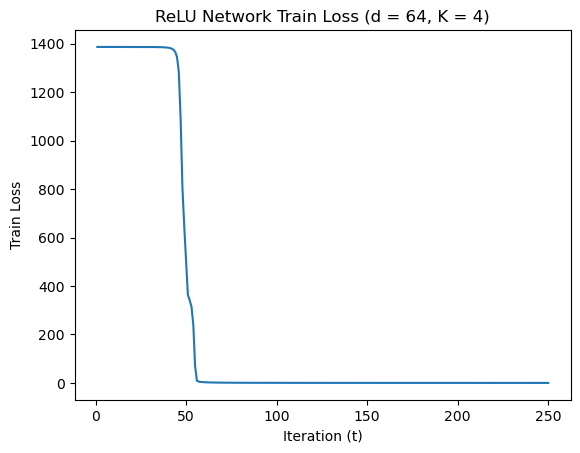

=== TRIAL 1 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:36:25,287 - INFO - Finish Epoch 1
2026-01-02 19:36:25,288 - INFO - Train loss: 1386.3035068511963, train accuracy: 21.0
2026-01-02 19:36:25,306 - INFO - Val loss: 1386.293848991394, val accuracy: 26.8
2026-01-02 19:36:25,344 - INFO - Finish Epoch 2
2026-01-02 19:36:25,345 - INFO - Train loss: 1386.2983779907227, train accuracy: 23.4
2026-01-02 19:36:25,363 - INFO - Val loss: 1386.290364265442, val accuracy: 29.6
  1%|          | 2/250 [00:00<00:14, 17.47it/s]2026-01-02 19:36:25,402 - INFO - Finish Epoch 3
2026-01-02 19:36:25,403 - INFO - Train loss: 1386.294750213623, train accuracy: 25.6
2026-01-02 19:36:25,420 - INFO - Val loss: 1386.2868852615356, val accuracy: 32.5
2026-01-02 19:36:25,459 - INFO - Finish Epoch 4
2026-01-02 19:36:25,460 - INFO - Train loss: 1386.2912521362305, train accuracy: 27.8
2026-01-02 19:36:25,477 - INFO - Val loss: 1386.2834091186523, val accuracy: 34.7
  2%|▏         | 4/250 [00:00<00:14, 17.52it/s]2026-0

 27%|██▋       | 68/250 [00:03<00:10, 16.99it/s]2026-01-02 19:36:29,229 - INFO - Finish Epoch 69
2026-01-02 19:36:29,230 - INFO - Train loss: 53.07606495451182, train accuracy: 100.0
2026-01-02 19:36:29,247 - INFO - Val loss: 7.823381510563195, val accuracy: 100.0
2026-01-02 19:36:29,285 - INFO - Finish Epoch 70
2026-01-02 19:36:29,287 - INFO - Train loss: 7.120745305437595, train accuracy: 100.0
2026-01-02 19:36:29,304 - INFO - Val loss: 4.107334349770099, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.11it/s]2026-01-02 19:36:29,343 - INFO - Finish Epoch 71
2026-01-02 19:36:29,345 - INFO - Train loss: 3.9393889168277383, train accuracy: 100.0
2026-01-02 19:36:29,362 - INFO - Val loss: 2.984568275511265, val accuracy: 100.0
2026-01-02 19:36:29,400 - INFO - Finish Epoch 72
2026-01-02 19:36:29,402 - INFO - Train loss: 2.898394239600748, train accuracy: 100.0
2026-01-02 19:36:29,419 - INFO - Val loss: 2.3890643790364265, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<00:

 41%|████      | 102/250 [00:05<00:08, 17.38it/s]2026-01-02 19:36:31,188 - INFO - Finish Epoch 103
2026-01-02 19:36:31,189 - INFO - Train loss: 0.3954745556693524, train accuracy: 100.0
2026-01-02 19:36:31,206 - INFO - Val loss: 0.38731741439551115, val accuracy: 100.0
2026-01-02 19:36:31,244 - INFO - Finish Epoch 104
2026-01-02 19:36:31,245 - INFO - Train loss: 0.3847491950727999, train accuracy: 100.0
2026-01-02 19:36:31,263 - INFO - Val loss: 0.3770188525086269, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.42it/s]2026-01-02 19:36:31,302 - INFO - Finish Epoch 105
2026-01-02 19:36:31,304 - INFO - Train loss: 0.37457417347468436, train accuracy: 100.0
2026-01-02 19:36:31,321 - INFO - Val loss: 0.3672304239589721, val accuracy: 100.0
2026-01-02 19:36:31,359 - INFO - Finish Epoch 106
2026-01-02 19:36:31,360 - INFO - Train loss: 0.36489643109962344, train accuracy: 100.0
2026-01-02 19:36:31,377 - INFO - Val loss: 0.35792265099007636, val accuracy: 100.0
 42%|████▏     | 1

2026-01-02 19:36:33,100 - INFO - Val loss: 0.20058152358978987, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.44it/s]2026-01-02 19:36:33,140 - INFO - Finish Epoch 137
2026-01-02 19:36:33,141 - INFO - Train loss: 0.19981294474564493, train accuracy: 100.0
2026-01-02 19:36:33,158 - INFO - Val loss: 0.1976110398536548, val accuracy: 100.0
2026-01-02 19:36:33,197 - INFO - Finish Epoch 138
2026-01-02 19:36:33,198 - INFO - Train loss: 0.19686056394129992, train accuracy: 100.0
2026-01-02 19:36:33,215 - INFO - Val loss: 0.19471927609993145, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.44it/s]2026-01-02 19:36:33,255 - INFO - Finish Epoch 139
2026-01-02 19:36:33,256 - INFO - Train loss: 0.1939914335962385, train accuracy: 100.0
2026-01-02 19:36:33,273 - INFO - Val loss: 0.19190707232337445, val accuracy: 100.0
2026-01-02 19:36:33,311 - INFO - Finish Epoch 140
2026-01-02 19:36:33,312 - INFO - Train loss: 0.19119506608694792, train accuracy: 100.0
2026-01-02 19:36

2026-01-02 19:36:35,149 - INFO - Finish Epoch 170
2026-01-02 19:36:35,150 - INFO - Train loss: 0.1326933336094953, train accuracy: 100.0
2026-01-02 19:36:35,168 - INFO - Val loss: 0.13168276962824166, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 16.25it/s]2026-01-02 19:36:35,208 - INFO - Finish Epoch 171
2026-01-02 19:36:35,209 - INFO - Train loss: 0.13133051892509684, train accuracy: 100.0
2026-01-02 19:36:35,226 - INFO - Val loss: 0.13033507973887026, val accuracy: 100.0
2026-01-02 19:36:35,269 - INFO - Finish Epoch 172
2026-01-02 19:36:35,271 - INFO - Train loss: 0.12999296037014574, train accuracy: 100.0
2026-01-02 19:36:35,288 - INFO - Val loss: 0.1290238555520773, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 16.34it/s]2026-01-02 19:36:35,330 - INFO - Finish Epoch 173
2026-01-02 19:36:35,331 - INFO - Train loss: 0.12868483184138313, train accuracy: 100.0
2026-01-02 19:36:35,348 - INFO - Val loss: 0.1277269177371636, val accuracy: 100.0
2026-01-02 19:36:

2026-01-02 19:36:37,061 - INFO - Train loss: 0.09846848162123933, train accuracy: 100.0
2026-01-02 19:36:37,078 - INFO - Val loss: 0.0978939633932896, val accuracy: 100.0
2026-01-02 19:36:37,117 - INFO - Finish Epoch 204
2026-01-02 19:36:37,118 - INFO - Train loss: 0.09769089065957814, train accuracy: 100.0
2026-01-02 19:36:37,135 - INFO - Val loss: 0.0971257877536118, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.36it/s]2026-01-02 19:36:37,175 - INFO - Finish Epoch 205
2026-01-02 19:36:37,176 - INFO - Train loss: 0.09692986286245286, train accuracy: 100.0
2026-01-02 19:36:37,193 - INFO - Val loss: 0.09637429122813046, val accuracy: 100.0
2026-01-02 19:36:37,232 - INFO - Finish Epoch 206
2026-01-02 19:36:37,233 - INFO - Train loss: 0.09617824788438156, train accuracy: 100.0
2026-01-02 19:36:37,250 - INFO - Val loss: 0.09562839748105034, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:12<00:02, 17.36it/s]2026-01-02 19:36:37,290 - INFO - Finish Epoch 207
2026-01-02 19:36

 94%|█████████▍| 236/250 [00:13<00:00, 17.51it/s]2026-01-02 19:36:39,016 - INFO - Finish Epoch 237
2026-01-02 19:36:39,017 - INFO - Train loss: 0.07733845309121534, train accuracy: 100.0
2026-01-02 19:36:39,034 - INFO - Val loss: 0.07697841775370762, val accuracy: 100.0
2026-01-02 19:36:39,072 - INFO - Finish Epoch 238
2026-01-02 19:36:39,073 - INFO - Train loss: 0.07684922503540292, train accuracy: 100.0
2026-01-02 19:36:39,090 - INFO - Val loss: 0.07649038027739152, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.52it/s]2026-01-02 19:36:39,130 - INFO - Finish Epoch 239
2026-01-02 19:36:39,131 - INFO - Train loss: 0.07636202071444131, train accuracy: 100.0
2026-01-02 19:36:39,148 - INFO - Val loss: 0.07600746690877713, val accuracy: 100.0
2026-01-02 19:36:39,187 - INFO - Finish Epoch 240
2026-01-02 19:36:39,188 - INFO - Train loss: 0.07588470817427151, train accuracy: 100.0
2026-01-02 19:36:39,205 - INFO - Val loss: 0.07553134484624024, val accuracy: 100.0
 96%|█████████

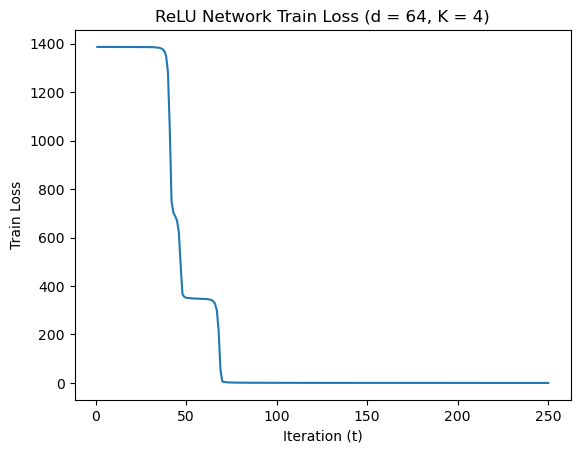

=== TRIAL 2 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:36:40,099 - INFO - Finish Epoch 1
2026-01-02 19:36:40,100 - INFO - Train loss: 1386.2995042800903, train accuracy: 23.5
2026-01-02 19:36:40,118 - INFO - Val loss: 1386.2929439544678, val accuracy: 29.0
2026-01-02 19:36:40,157 - INFO - Finish Epoch 2
2026-01-02 19:36:40,158 - INFO - Train loss: 1386.296025276184, train accuracy: 25.2
2026-01-02 19:36:40,176 - INFO - Val loss: 1386.2908267974854, val accuracy: 30.5
  1%|          | 2/250 [00:00<00:14, 17.15it/s]2026-01-02 19:36:40,216 - INFO - Finish Epoch 3
2026-01-02 19:36:40,217 - INFO - Train loss: 1386.2938346862793, train accuracy: 26.9
2026-01-02 19:36:40,234 - INFO - Val loss: 1386.2887020111084, val accuracy: 32.4
2026-01-02 19:36:40,273 - INFO - Finish Epoch 4
2026-01-02 19:36:40,274 - INFO - Train loss: 1386.291742324829, train accuracy: 28.6
2026-01-02 19:36:40,291 - INFO - Val loss: 1386.2865962982178, val accuracy: 34.4
  2%|▏         | 4/250 [00:00<00:14, 17.30it/s]2026-

 27%|██▋       | 68/250 [00:03<00:10, 17.39it/s]2026-01-02 19:36:44,008 - INFO - Finish Epoch 69
2026-01-02 19:36:44,009 - INFO - Train loss: 1.8098265016451478, train accuracy: 100.0
2026-01-02 19:36:44,026 - INFO - Val loss: 1.7029367722570896, val accuracy: 100.0
2026-01-02 19:36:44,065 - INFO - Finish Epoch 70
2026-01-02 19:36:44,066 - INFO - Train loss: 1.6609000600874424, train accuracy: 100.0
2026-01-02 19:36:44,083 - INFO - Val loss: 1.5695584984496236, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.41it/s]2026-01-02 19:36:44,138 - INFO - Finish Epoch 71
2026-01-02 19:36:44,139 - INFO - Train loss: 1.5334914708510041, train accuracy: 100.0
2026-01-02 19:36:44,156 - INFO - Val loss: 1.454573255032301, val accuracy: 100.0
2026-01-02 19:36:44,195 - INFO - Finish Epoch 72
2026-01-02 19:36:44,196 - INFO - Train loss: 1.4233137099072337, train accuracy: 100.0
2026-01-02 19:36:44,213 - INFO - Val loss: 1.3544969744980335, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:05<00:08, 17.61it/s]2026-01-02 19:36:45,960 - INFO - Finish Epoch 103
2026-01-02 19:36:45,962 - INFO - Train loss: 0.4117462115827948, train accuracy: 100.0
2026-01-02 19:36:45,978 - INFO - Val loss: 0.40472827618941665, val accuracy: 100.0
2026-01-02 19:36:46,017 - INFO - Finish Epoch 104
2026-01-02 19:36:46,018 - INFO - Train loss: 0.4018741713371128, train accuracy: 100.0
2026-01-02 19:36:46,035 - INFO - Val loss: 0.3951657493598759, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.63it/s]2026-01-02 19:36:46,074 - INFO - Finish Epoch 105
2026-01-02 19:36:46,075 - INFO - Train loss: 0.39243603497743607, train accuracy: 100.0
2026-01-02 19:36:46,092 - INFO - Val loss: 0.38601690880022943, val accuracy: 100.0
2026-01-02 19:36:46,132 - INFO - Finish Epoch 106
2026-01-02 19:36:46,133 - INFO - Train loss: 0.3834045461844653, train accuracy: 100.0
2026-01-02 19:36:46,149 - INFO - Val loss: 0.3772526883985847, val accuracy: 100.0
 42%|████▏     | 10

2026-01-02 19:36:47,863 - INFO - Val loss: 0.2206652204040438, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.57it/s]2026-01-02 19:36:47,903 - INFO - Finish Epoch 137
2026-01-02 19:36:47,904 - INFO - Train loss: 0.21974643727298826, train accuracy: 100.0
2026-01-02 19:36:47,921 - INFO - Val loss: 0.2175526178907603, val accuracy: 100.0
2026-01-02 19:36:47,960 - INFO - Finish Epoch 138
2026-01-02 19:36:47,961 - INFO - Train loss: 0.21665539301466197, train accuracy: 100.0
2026-01-02 19:36:47,978 - INFO - Val loss: 0.21451456635259092, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.50it/s]2026-01-02 19:36:48,018 - INFO - Finish Epoch 139
2026-01-02 19:36:48,019 - INFO - Train loss: 0.21364474145229906, train accuracy: 100.0
2026-01-02 19:36:48,037 - INFO - Val loss: 0.21156026341486722, val accuracy: 100.0
2026-01-02 19:36:48,076 - INFO - Finish Epoch 140
2026-01-02 19:36:48,077 - INFO - Train loss: 0.2107110433280468, train accuracy: 100.0
2026-01-02 19:36:

2026-01-02 19:36:49,797 - INFO - Finish Epoch 170
2026-01-02 19:36:49,798 - INFO - Train loss: 0.14809215941932052, train accuracy: 100.0
2026-01-02 19:36:49,815 - INFO - Val loss: 0.14703314693178982, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.22it/s]2026-01-02 19:36:49,855 - INFO - Finish Epoch 171
2026-01-02 19:36:49,856 - INFO - Train loss: 0.14660655881743878, train accuracy: 100.0
2026-01-02 19:36:49,873 - INFO - Val loss: 0.14556899247691035, val accuracy: 100.0
2026-01-02 19:36:49,912 - INFO - Finish Epoch 172
2026-01-02 19:36:49,913 - INFO - Train loss: 0.14514764631167054, train accuracy: 100.0
2026-01-02 19:36:49,930 - INFO - Val loss: 0.14412926055956632, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.29it/s]2026-01-02 19:36:49,970 - INFO - Finish Epoch 173
2026-01-02 19:36:49,971 - INFO - Train loss: 0.14371470361948013, train accuracy: 100.0
2026-01-02 19:36:49,988 - INFO - Val loss: 0.1427172864205204, val accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:36:51,722 - INFO - Train loss: 0.11042735923547298, train accuracy: 100.0
2026-01-02 19:36:51,739 - INFO - Val loss: 0.10981039085891098, val accuracy: 100.0
2026-01-02 19:36:51,778 - INFO - Finish Epoch 204
2026-01-02 19:36:51,779 - INFO - Train loss: 0.10956597374752164, train accuracy: 100.0
2026-01-02 19:36:51,796 - INFO - Val loss: 0.10896116041112691, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.30it/s]2026-01-02 19:36:51,835 - INFO - Finish Epoch 205
2026-01-02 19:36:51,837 - INFO - Train loss: 0.10871698055416346, train accuracy: 100.0
2026-01-02 19:36:51,853 - INFO - Val loss: 0.10812158073531464, val accuracy: 100.0
2026-01-02 19:36:51,892 - INFO - Finish Epoch 206
2026-01-02 19:36:51,893 - INFO - Train loss: 0.10788240499095991, train accuracy: 100.0
2026-01-02 19:36:51,910 - INFO - Val loss: 0.10729534609708935, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.35it/s]2026-01-02 19:36:51,950 - INFO - Finish Epoch 207
2026-01-02 19:

 94%|█████████▍| 236/250 [00:13<00:00, 17.31it/s]2026-01-02 19:36:53,682 - INFO - Finish Epoch 237
2026-01-02 19:36:53,683 - INFO - Train loss: 0.08686157994088717, train accuracy: 100.0
2026-01-02 19:36:53,700 - INFO - Val loss: 0.08646947241504677, val accuracy: 100.0
2026-01-02 19:36:53,739 - INFO - Finish Epoch 238
2026-01-02 19:36:53,741 - INFO - Train loss: 0.08631001284811646, train accuracy: 100.0
2026-01-02 19:36:53,758 - INFO - Val loss: 0.08592279304866679, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.30it/s]2026-01-02 19:36:53,798 - INFO - Finish Epoch 239
2026-01-02 19:36:53,799 - INFO - Train loss: 0.08576762207667343, train accuracy: 100.0
2026-01-02 19:36:53,816 - INFO - Val loss: 0.08538576296996325, val accuracy: 100.0
2026-01-02 19:36:53,855 - INFO - Finish Epoch 240
2026-01-02 19:36:53,856 - INFO - Train loss: 0.08523285842966288, train accuracy: 100.0
2026-01-02 19:36:53,873 - INFO - Val loss: 0.08485231135273352, val accuracy: 100.0
 96%|█████████

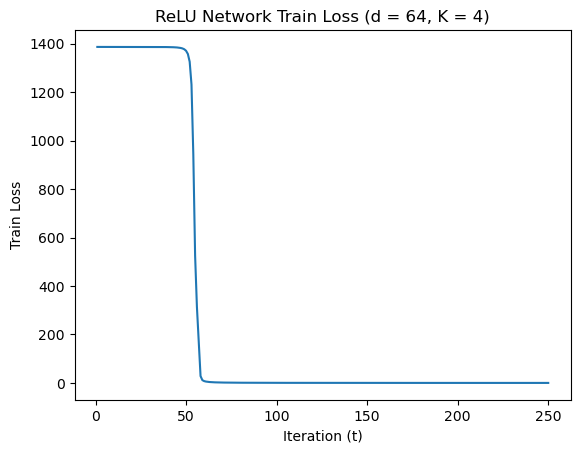

=== TRIAL 3 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:36:54,778 - INFO - Finish Epoch 1
2026-01-02 19:36:54,780 - INFO - Train loss: 1386.2957067489624, train accuracy: 27.4
2026-01-02 19:36:54,797 - INFO - Val loss: 1386.2856512069702, val accuracy: 32.5
2026-01-02 19:36:54,835 - INFO - Finish Epoch 2
2026-01-02 19:36:54,836 - INFO - Train loss: 1386.2905855178833, train accuracy: 30.3
2026-01-02 19:36:54,854 - INFO - Val loss: 1386.2821350097656, val accuracy: 35.4
  1%|          | 2/250 [00:00<00:14, 17.50it/s]2026-01-02 19:36:54,893 - INFO - Finish Epoch 3
2026-01-02 19:36:54,895 - INFO - Train loss: 1386.2869853973389, train accuracy: 32.4
2026-01-02 19:36:54,912 - INFO - Val loss: 1386.2784824371338, val accuracy: 38.3
2026-01-02 19:36:54,951 - INFO - Finish Epoch 4
2026-01-02 19:36:54,952 - INFO - Train loss: 1386.2833776474, train accuracy: 34.6
2026-01-02 19:36:54,969 - INFO - Val loss: 1386.2747020721436, val accuracy: 41.0
  2%|▏         | 4/250 [00:00<00:14, 17.36it/s]2026-0

 27%|██▋       | 68/250 [00:03<00:10, 17.43it/s]2026-01-02 19:36:58,700 - INFO - Finish Epoch 69
2026-01-02 19:36:58,701 - INFO - Train loss: 0.8785354308784008, train accuracy: 100.0
2026-01-02 19:36:58,718 - INFO - Val loss: 0.8492698119953275, val accuracy: 100.0
2026-01-02 19:36:58,756 - INFO - Finish Epoch 70
2026-01-02 19:36:58,757 - INFO - Train loss: 0.838352638296783, train accuracy: 100.0
2026-01-02 19:36:58,774 - INFO - Val loss: 0.8115070508792996, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.47it/s]2026-01-02 19:36:58,814 - INFO - Finish Epoch 71
2026-01-02 19:36:58,815 - INFO - Train loss: 0.8014687108807266, train accuracy: 100.0
2026-01-02 19:36:58,833 - INFO - Val loss: 0.7767582628875971, val accuracy: 100.0
2026-01-02 19:36:58,871 - INFO - Finish Epoch 72
2026-01-02 19:36:58,873 - INFO - Train loss: 0.7674997691065073, train accuracy: 100.0
2026-01-02 19:36:58,890 - INFO - Val loss: 0.7446870098356158, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

2026-01-02 19:37:00,616 - INFO - Val loss: 0.32040054351091385, val accuracy: 100.0
 41%|████      | 102/250 [00:05<00:08, 17.37it/s]2026-01-02 19:37:00,656 - INFO - Finish Epoch 103
2026-01-02 19:37:00,657 - INFO - Train loss: 0.3186194602167234, train accuracy: 100.0
2026-01-02 19:37:00,675 - INFO - Val loss: 0.3141284795710817, val accuracy: 100.0
2026-01-02 19:37:00,714 - INFO - Finish Epoch 104
2026-01-02 19:37:00,715 - INFO - Train loss: 0.3124105101451278, train accuracy: 100.0
2026-01-02 19:37:00,732 - INFO - Val loss: 0.30808145296759903, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.31it/s]2026-01-02 19:37:00,772 - INFO - Finish Epoch 105
2026-01-02 19:37:00,774 - INFO - Train loss: 0.30642600229475647, train accuracy: 100.0
2026-01-02 19:37:00,791 - INFO - Val loss: 0.30224791762884706, val accuracy: 100.0
2026-01-02 19:37:00,830 - INFO - Finish Epoch 106
2026-01-02 19:37:00,831 - INFO - Train loss: 0.30065082130022347, train accuracy: 100.0
2026-01-02 19:37:

2026-01-02 19:37:02,565 - INFO - Finish Epoch 136
2026-01-02 19:37:02,567 - INFO - Train loss: 0.18971641146345064, train accuracy: 100.0
2026-01-02 19:37:02,584 - INFO - Val loss: 0.18800096481572837, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.13it/s]2026-01-02 19:37:02,624 - INFO - Finish Epoch 137
2026-01-02 19:37:02,625 - INFO - Train loss: 0.18734585971105844, train accuracy: 100.0
2026-01-02 19:37:02,642 - INFO - Val loss: 0.18566757370717824, val accuracy: 100.0
2026-01-02 19:37:02,681 - INFO - Finish Epoch 138
2026-01-02 19:37:02,682 - INFO - Train loss: 0.18502974323928356, train accuracy: 100.0
2026-01-02 19:37:02,699 - INFO - Val loss: 0.18339327140711248, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.18it/s]2026-01-02 19:37:02,739 - INFO - Finish Epoch 139
2026-01-02 19:37:02,740 - INFO - Train loss: 0.18276699632406235, train accuracy: 100.0
2026-01-02 19:37:02,758 - INFO - Val loss: 0.18116709403693676, val accuracy: 100.0
2026-01-02 19:

2026-01-02 19:37:04,494 - INFO - Train loss: 0.13290530646918342, train accuracy: 100.0
2026-01-02 19:37:04,511 - INFO - Val loss: 0.1320180289912969, val accuracy: 100.0
2026-01-02 19:37:04,550 - INFO - Finish Epoch 170
2026-01-02 19:37:04,552 - INFO - Train loss: 0.1316829266725108, train accuracy: 100.0
2026-01-02 19:37:04,569 - INFO - Val loss: 0.1308126842486672, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.14it/s]2026-01-02 19:37:04,609 - INFO - Finish Epoch 171
2026-01-02 19:37:04,610 - INFO - Train loss: 0.13047913182526827, train accuracy: 100.0
2026-01-02 19:37:04,628 - INFO - Val loss: 0.12962616613367572, val accuracy: 100.0
2026-01-02 19:37:04,667 - INFO - Finish Epoch 172
2026-01-02 19:37:04,668 - INFO - Train loss: 0.12930059526115656, train accuracy: 100.0
2026-01-02 19:37:04,685 - INFO - Val loss: 0.12846323917619884, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.16it/s]2026-01-02 19:37:04,726 - INFO - Finish Epoch 173
2026-01-02 19:37:

 81%|████████  | 202/250 [00:11<00:02, 17.15it/s]2026-01-02 19:37:06,565 - INFO - Finish Epoch 203
2026-01-02 19:37:06,566 - INFO - Train loss: 0.10060317273018882, train accuracy: 100.0
2026-01-02 19:37:06,583 - INFO - Val loss: 0.10007774265250191, val accuracy: 100.0
2026-01-02 19:37:06,621 - INFO - Finish Epoch 204
2026-01-02 19:37:06,623 - INFO - Train loss: 0.09987549736979418, train accuracy: 100.0
2026-01-02 19:37:06,640 - INFO - Val loss: 0.09935888648033142, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.26it/s]2026-01-02 19:37:06,679 - INFO - Finish Epoch 205
2026-01-02 19:37:06,680 - INFO - Train loss: 0.09916093430365436, train accuracy: 100.0
2026-01-02 19:37:06,697 - INFO - Val loss: 0.0986482524604071, val accuracy: 100.0
2026-01-02 19:37:06,736 - INFO - Finish Epoch 206
2026-01-02 19:37:06,737 - INFO - Train loss: 0.09845423258957453, train accuracy: 100.0
2026-01-02 19:37:06,754 - INFO - Val loss: 0.0979469130106736, val accuracy: 100.0
 82%|████████▏ |

2026-01-02 19:37:08,469 - INFO - Train loss: 0.08091975082061253, train accuracy: 100.0
2026-01-02 19:37:08,487 - INFO - Val loss: 0.08056817424949259, val accuracy: 100.0
 94%|█████████▍| 236/250 [00:13<00:00, 17.16it/s]2026-01-02 19:37:08,528 - INFO - Finish Epoch 237
2026-01-02 19:37:08,529 - INFO - Train loss: 0.0804334974673111, train accuracy: 100.0
2026-01-02 19:37:08,546 - INFO - Val loss: 0.08008907170733437, val accuracy: 100.0
2026-01-02 19:37:08,587 - INFO - Finish Epoch 238
2026-01-02 19:37:08,588 - INFO - Train loss: 0.07995773217407987, train accuracy: 100.0
2026-01-02 19:37:08,606 - INFO - Val loss: 0.07961235212860629, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.06it/s]2026-01-02 19:37:08,645 - INFO - Finish Epoch 239
2026-01-02 19:37:08,646 - INFO - Train loss: 0.07948577956994995, train accuracy: 100.0
2026-01-02 19:37:08,663 - INFO - Val loss: 0.07914516629534774, val accuracy: 100.0
2026-01-02 19:37:08,701 - INFO - Finish Epoch 240
2026-01-02 19:3

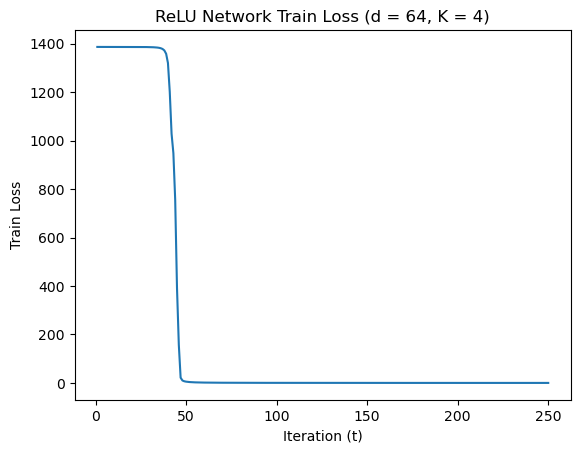

=== TRIAL 4 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:37:09,616 - INFO - Finish Epoch 1
2026-01-02 19:37:09,617 - INFO - Train loss: 1386.2996921539307, train accuracy: 21.2
2026-01-02 19:37:09,634 - INFO - Val loss: 1386.2925100326538, val accuracy: 28.3
2026-01-02 19:37:09,673 - INFO - Finish Epoch 2
2026-01-02 19:37:09,674 - INFO - Train loss: 1386.2958679199219, train accuracy: 25.1
2026-01-02 19:37:09,691 - INFO - Val loss: 1386.290138244629, val accuracy: 30.1
  1%|          | 2/250 [00:00<00:14, 17.44it/s]2026-01-02 19:37:09,731 - INFO - Finish Epoch 3
2026-01-02 19:37:09,732 - INFO - Train loss: 1386.2934246063232, train accuracy: 27.5
2026-01-02 19:37:09,749 - INFO - Val loss: 1386.2877216339111, val accuracy: 32.5
2026-01-02 19:37:09,788 - INFO - Finish Epoch 4
2026-01-02 19:37:09,789 - INFO - Train loss: 1386.2910318374634, train accuracy: 30.0
2026-01-02 19:37:09,806 - INFO - Val loss: 1386.2852792739868, val accuracy: 34.8
  2%|▏         | 4/250 [00:00<00:14, 17.47it/s]2026

 27%|██▋       | 68/250 [00:03<00:10, 17.40it/s]2026-01-02 19:37:13,525 - INFO - Finish Epoch 69
2026-01-02 19:37:13,526 - INFO - Train loss: 1.5186469368636608, train accuracy: 100.0
2026-01-02 19:37:13,543 - INFO - Val loss: 1.4471102841198444, val accuracy: 100.0
2026-01-02 19:37:13,582 - INFO - Finish Epoch 70
2026-01-02 19:37:13,583 - INFO - Train loss: 1.4084258507937193, train accuracy: 100.0
2026-01-02 19:37:13,600 - INFO - Val loss: 1.3460876755416393, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.41it/s]2026-01-02 19:37:13,641 - INFO - Finish Epoch 71
2026-01-02 19:37:13,642 - INFO - Train loss: 1.3125429209321737, train accuracy: 100.0
2026-01-02 19:37:13,659 - INFO - Val loss: 1.257755883038044, val accuracy: 100.0
2026-01-02 19:37:13,698 - INFO - Finish Epoch 72
2026-01-02 19:37:13,699 - INFO - Train loss: 1.2283895574510098, train accuracy: 100.0
2026-01-02 19:37:13,716 - INFO - Val loss: 1.1798728536814451, val accuracy: 100.0
 29%|██▉       | 72/250 [00:0

 41%|████      | 102/250 [00:05<00:08, 17.26it/s]2026-01-02 19:37:15,511 - INFO - Finish Epoch 103
2026-01-02 19:37:15,512 - INFO - Train loss: 0.3922208803705871, train accuracy: 100.0
2026-01-02 19:37:15,529 - INFO - Val loss: 0.386265738401562, val accuracy: 100.0
2026-01-02 19:37:15,568 - INFO - Finish Epoch 104
2026-01-02 19:37:15,569 - INFO - Train loss: 0.3833698914386332, train accuracy: 100.0
2026-01-02 19:37:15,586 - INFO - Val loss: 0.3776592444628477, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.31it/s]2026-01-02 19:37:15,626 - INFO - Finish Epoch 105
2026-01-02 19:37:15,627 - INFO - Train loss: 0.37489214166998863, train accuracy: 100.0
2026-01-02 19:37:15,644 - INFO - Val loss: 0.3694108962081373, val accuracy: 100.0
2026-01-02 19:37:15,683 - INFO - Finish Epoch 106
2026-01-02 19:37:15,684 - INFO - Train loss: 0.3667551577091217, train accuracy: 100.0
2026-01-02 19:37:15,701 - INFO - Val loss: 0.3614924969151616, val accuracy: 100.0
 42%|████▏     | 106/2

2026-01-02 19:37:17,558 - INFO - Val loss: 0.21719115995801985, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:08, 12.88it/s]2026-01-02 19:37:17,598 - INFO - Finish Epoch 137
2026-01-02 19:37:17,600 - INFO - Train loss: 0.21624513971619308, train accuracy: 100.0
2026-01-02 19:37:17,617 - INFO - Val loss: 0.21425401465967298, val accuracy: 100.0
2026-01-02 19:37:17,656 - INFO - Finish Epoch 138
2026-01-02 19:37:17,657 - INFO - Train loss: 0.21333597670309246, train accuracy: 100.0
2026-01-02 19:37:17,674 - INFO - Val loss: 0.21139867324382067, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:08<00:08, 13.95it/s]2026-01-02 19:37:17,714 - INFO - Finish Epoch 139
2026-01-02 19:37:17,715 - INFO - Train loss: 0.21050481242127717, train accuracy: 100.0
2026-01-02 19:37:17,732 - INFO - Val loss: 0.20861215749755502, val accuracy: 100.0
2026-01-02 19:37:17,771 - INFO - Finish Epoch 140
2026-01-02 19:37:17,772 - INFO - Train loss: 0.2077402037102729, train accuracy: 100.0
2026-01-02 19:3

2026-01-02 19:37:19,504 - INFO - Finish Epoch 170
2026-01-02 19:37:19,505 - INFO - Train loss: 0.14811175991781056, train accuracy: 100.0
2026-01-02 19:37:19,522 - INFO - Val loss: 0.14712848770432174, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.28it/s]2026-01-02 19:37:19,563 - INFO - Finish Epoch 171
2026-01-02 19:37:19,564 - INFO - Train loss: 0.1466836028266698, train accuracy: 100.0
2026-01-02 19:37:19,582 - INFO - Val loss: 0.1457143798470497, val accuracy: 100.0
2026-01-02 19:37:19,622 - INFO - Finish Epoch 172
2026-01-02 19:37:19,623 - INFO - Train loss: 0.1452784282155335, train accuracy: 100.0
2026-01-02 19:37:19,641 - INFO - Val loss: 0.14432695764116943, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 17.15it/s]2026-01-02 19:37:19,681 - INFO - Finish Epoch 173
2026-01-02 19:37:19,682 - INFO - Train loss: 0.14389886567369103, train accuracy: 100.0
2026-01-02 19:37:19,699 - INFO - Val loss: 0.14296049275435507, val accuracy: 100.0
2026-01-02 19:37:

2026-01-02 19:37:21,446 - INFO - Val loss: 0.11098996072541922, val accuracy: 100.0
2026-01-02 19:37:21,485 - INFO - Finish Epoch 204
2026-01-02 19:37:21,486 - INFO - Train loss: 0.11073222104460001, train accuracy: 100.0
2026-01-02 19:37:21,503 - INFO - Val loss: 0.11015621514525265, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.13it/s]2026-01-02 19:37:21,543 - INFO - Finish Epoch 205
2026-01-02 19:37:21,544 - INFO - Train loss: 0.10990347701590508, train accuracy: 100.0
2026-01-02 19:37:21,561 - INFO - Val loss: 0.1093341438099742, val accuracy: 100.0
2026-01-02 19:37:21,599 - INFO - Finish Epoch 206
2026-01-02 19:37:21,601 - INFO - Train loss: 0.1090843859128654, train accuracy: 100.0
2026-01-02 19:37:21,618 - INFO - Val loss: 0.10852482297923416, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:12<00:02, 17.22it/s]2026-01-02 19:37:21,657 - INFO - Finish Epoch 207
2026-01-02 19:37:21,659 - INFO - Train loss: 0.10827970842365175, train accuracy: 100.0
2026-01-02 19:37

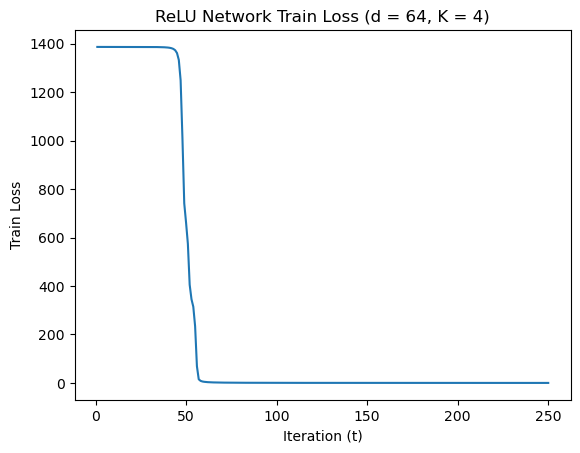

=== TRIAL 5 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:37:24,462 - INFO - Finish Epoch 1
2026-01-02 19:37:24,463 - INFO - Train loss: 1386.2999572753906, train accuracy: 23.9
2026-01-02 19:37:24,481 - INFO - Val loss: 1386.2907581329346, val accuracy: 29.6
2026-01-02 19:37:24,520 - INFO - Finish Epoch 2
2026-01-02 19:37:24,521 - INFO - Train loss: 1386.2949361801147, train accuracy: 26.2
2026-01-02 19:37:24,539 - INFO - Val loss: 1386.2875328063965, val accuracy: 32.3
  1%|          | 2/250 [00:00<00:14, 17.15it/s]2026-01-02 19:37:24,579 - INFO - Finish Epoch 3
2026-01-02 19:37:24,580 - INFO - Train loss: 1386.2916278839111, train accuracy: 28.6
2026-01-02 19:37:24,598 - INFO - Val loss: 1386.2842330932617, val accuracy: 35.1
2026-01-02 19:37:24,636 - INFO - Finish Epoch 4
2026-01-02 19:37:24,638 - INFO - Train loss: 1386.2883415222168, train accuracy: 31.5
2026-01-02 19:37:24,655 - INFO - Val loss: 1386.2808246612549, val accuracy: 37.6
  2%|▏         | 4/250 [00:00<00:14, 17.22it/s]202

 27%|██▋       | 68/250 [00:03<00:10, 17.38it/s]2026-01-02 19:37:28,385 - INFO - Finish Epoch 69
2026-01-02 19:37:28,386 - INFO - Train loss: 0.9116860684007406, train accuracy: 100.0
2026-01-02 19:37:28,403 - INFO - Val loss: 0.8790212692692876, val accuracy: 100.0
2026-01-02 19:37:28,442 - INFO - Finish Epoch 70
2026-01-02 19:37:28,443 - INFO - Train loss: 0.8679100144654512, train accuracy: 100.0
2026-01-02 19:37:28,460 - INFO - Val loss: 0.8380591282621026, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.39it/s]2026-01-02 19:37:28,500 - INFO - Finish Epoch 71
2026-01-02 19:37:28,501 - INFO - Train loss: 0.8279243786819279, train accuracy: 100.0
2026-01-02 19:37:28,519 - INFO - Val loss: 0.8005514671094716, val accuracy: 100.0
2026-01-02 19:37:28,558 - INFO - Finish Epoch 72
2026-01-02 19:37:28,559 - INFO - Train loss: 0.7912749843671918, train accuracy: 100.0
2026-01-02 19:37:28,577 - INFO - Val loss: 0.7660845532082021, val accuracy: 100.0
 29%|██▉       | 72/250 [00:

2026-01-02 19:37:30,302 - INFO - Val loss: 0.32265987002756447, val accuracy: 100.0
 41%|████      | 102/250 [00:05<00:08, 17.49it/s]2026-01-02 19:37:30,342 - INFO - Finish Epoch 103
2026-01-02 19:37:30,343 - INFO - Train loss: 0.3210367080755532, train accuracy: 100.0
2026-01-02 19:37:30,360 - INFO - Val loss: 0.3162630951264873, val accuracy: 100.0
2026-01-02 19:37:30,398 - INFO - Finish Epoch 104
2026-01-02 19:37:30,399 - INFO - Train loss: 0.31470196950249374, train accuracy: 100.0
2026-01-02 19:37:30,416 - INFO - Val loss: 0.3100958263967186, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.50it/s]2026-01-02 19:37:30,456 - INFO - Finish Epoch 105
2026-01-02 19:37:30,457 - INFO - Train loss: 0.30859318003058434, train accuracy: 100.0
2026-01-02 19:37:30,474 - INFO - Val loss: 0.3041518973186612, val accuracy: 100.0
2026-01-02 19:37:30,512 - INFO - Finish Epoch 106
2026-01-02 19:37:30,514 - INFO - Train loss: 0.3027060532476753, train accuracy: 100.0
2026-01-02 19:37:30

2026-01-02 19:37:32,233 - INFO - Finish Epoch 136
2026-01-02 19:37:32,234 - INFO - Train loss: 0.19023504108190536, train accuracy: 100.0
2026-01-02 19:37:32,251 - INFO - Val loss: 0.18842327408492565, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.48it/s]2026-01-02 19:37:32,291 - INFO - Finish Epoch 137
2026-01-02 19:37:32,292 - INFO - Train loss: 0.1878414339153096, train accuracy: 100.0
2026-01-02 19:37:32,309 - INFO - Val loss: 0.1860756417736411, val accuracy: 100.0
2026-01-02 19:37:32,348 - INFO - Finish Epoch 138
2026-01-02 19:37:32,349 - INFO - Train loss: 0.18550833582412452, train accuracy: 100.0
2026-01-02 19:37:32,366 - INFO - Val loss: 0.1837782704969868, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.43it/s]2026-01-02 19:37:32,407 - INFO - Finish Epoch 139
2026-01-02 19:37:32,408 - INFO - Train loss: 0.18322430981788784, train accuracy: 100.0
2026-01-02 19:37:32,425 - INFO - Val loss: 0.18153342488221824, val accuracy: 100.0
2026-01-02 19:37:

2026-01-02 19:37:34,160 - INFO - Val loss: 0.13214918097946793, val accuracy: 100.0
2026-01-02 19:37:34,199 - INFO - Finish Epoch 170
2026-01-02 19:37:34,200 - INFO - Train loss: 0.13185578328557312, train accuracy: 100.0
2026-01-02 19:37:34,217 - INFO - Val loss: 0.13093663105973974, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.22it/s]2026-01-02 19:37:34,256 - INFO - Finish Epoch 171
2026-01-02 19:37:34,258 - INFO - Train loss: 0.1306514527532272, train accuracy: 100.0
2026-01-02 19:37:34,274 - INFO - Val loss: 0.12974802614189684, val accuracy: 100.0
2026-01-02 19:37:34,313 - INFO - Finish Epoch 172
2026-01-02 19:37:34,314 - INFO - Train loss: 0.12946773413568735, train accuracy: 100.0
2026-01-02 19:37:34,331 - INFO - Val loss: 0.1285803896607831, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.30it/s]2026-01-02 19:37:34,370 - INFO - Finish Epoch 173
2026-01-02 19:37:34,372 - INFO - Train loss: 0.12830450583714992, train accuracy: 100.0
2026-01-02 19:37

2026-01-02 19:37:37,997 - INFO - Train loss: 0.08100281350198202, train accuracy: 100.0
2026-01-02 19:37:38,014 - INFO - Val loss: 0.08063444960862398, val accuracy: 100.0
 94%|█████████▍| 236/250 [00:13<00:00, 17.40it/s]2026-01-02 19:37:38,054 - INFO - Finish Epoch 237
2026-01-02 19:37:38,055 - INFO - Train loss: 0.08052241531549953, train accuracy: 100.0
2026-01-02 19:37:38,072 - INFO - Val loss: 0.08015178400091827, val accuracy: 100.0
2026-01-02 19:37:38,110 - INFO - Finish Epoch 238
2026-01-02 19:37:38,112 - INFO - Train loss: 0.08004118199460208, train accuracy: 100.0
2026-01-02 19:37:38,129 - INFO - Val loss: 0.07967996635125019, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.43it/s]2026-01-02 19:37:38,168 - INFO - Finish Epoch 239
2026-01-02 19:37:38,169 - INFO - Train loss: 0.07957043522037566, train accuracy: 100.0
2026-01-02 19:37:38,186 - INFO - Val loss: 0.07921100570820272, val accuracy: 100.0
2026-01-02 19:37:38,224 - INFO - Finish Epoch 240
2026-01-02 19:

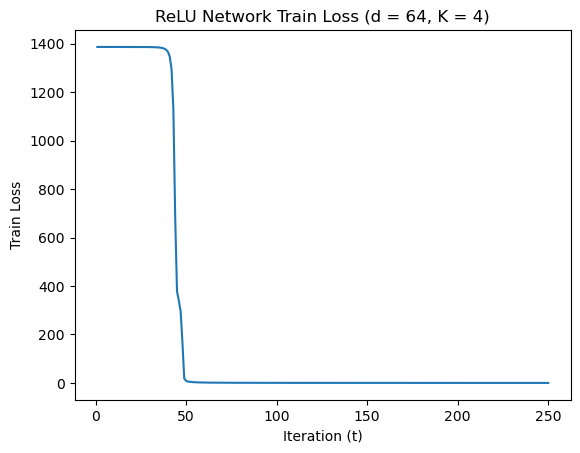

=== TRIAL 6 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:37:39,142 - INFO - Finish Epoch 1
2026-01-02 19:37:39,143 - INFO - Train loss: 1386.2946147918701, train accuracy: 22.9
2026-01-02 19:37:39,160 - INFO - Val loss: 1386.2890129089355, val accuracy: 24.5
2026-01-02 19:37:39,199 - INFO - Finish Epoch 2
2026-01-02 19:37:39,200 - INFO - Train loss: 1386.2915534973145, train accuracy: 23.8
2026-01-02 19:37:39,218 - INFO - Val loss: 1386.2868766784668, val accuracy: 25.6
  1%|          | 2/250 [00:00<00:14, 17.32it/s]2026-01-02 19:37:39,258 - INFO - Finish Epoch 3
2026-01-02 19:37:39,259 - INFO - Train loss: 1386.2894306182861, train accuracy: 24.5
2026-01-02 19:37:39,276 - INFO - Val loss: 1386.2846870422363, val accuracy: 26.5
2026-01-02 19:37:39,315 - INFO - Finish Epoch 4
2026-01-02 19:37:39,316 - INFO - Train loss: 1386.2872772216797, train accuracy: 25.4
2026-01-02 19:37:39,333 - INFO - Val loss: 1386.2824306488037, val accuracy: 27.5
  2%|▏         | 4/250 [00:00<00:14, 17.32it/s]202

 27%|██▋       | 68/250 [00:03<00:10, 17.40it/s]2026-01-02 19:37:43,079 - INFO - Finish Epoch 69
2026-01-02 19:37:43,080 - INFO - Train loss: 1.302739143371582, train accuracy: 100.0
2026-01-02 19:37:43,097 - INFO - Val loss: 1.2477715574204922, val accuracy: 100.0
2026-01-02 19:37:43,136 - INFO - Finish Epoch 70
2026-01-02 19:37:43,137 - INFO - Train loss: 1.2172273192554712, train accuracy: 100.0
2026-01-02 19:37:43,154 - INFO - Val loss: 1.1685746740549803, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.42it/s]2026-01-02 19:37:43,194 - INFO - Finish Epoch 71
2026-01-02 19:37:43,195 - INFO - Train loss: 1.141841416247189, train accuracy: 100.0
2026-01-02 19:37:43,212 - INFO - Val loss: 1.0984646594151855, val accuracy: 100.0
2026-01-02 19:37:43,250 - INFO - Finish Epoch 72
2026-01-02 19:37:43,252 - INFO - Train loss: 1.0748791228979826, train accuracy: 100.0
2026-01-02 19:37:43,269 - INFO - Val loss: 1.0359746096655726, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04

 41%|████      | 102/250 [00:05<00:08, 17.35it/s]2026-01-02 19:37:45,052 - INFO - Finish Epoch 103
2026-01-02 19:37:45,053 - INFO - Train loss: 0.3652824079617858, train accuracy: 100.0
2026-01-02 19:37:45,070 - INFO - Val loss: 0.359825674444437, val accuracy: 100.0
2026-01-02 19:37:45,109 - INFO - Finish Epoch 104
2026-01-02 19:37:45,110 - INFO - Train loss: 0.357289427658543, train accuracy: 100.0
2026-01-02 19:37:45,128 - INFO - Val loss: 0.352053077891469, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.32it/s]2026-01-02 19:37:45,168 - INFO - Finish Epoch 105
2026-01-02 19:37:45,169 - INFO - Train loss: 0.3496216800995171, train accuracy: 100.0
2026-01-02 19:37:45,186 - INFO - Val loss: 0.34458811208605766, val accuracy: 100.0
2026-01-02 19:37:45,224 - INFO - Finish Epoch 106
2026-01-02 19:37:45,225 - INFO - Train loss: 0.3422621649224311, train accuracy: 100.0
2026-01-02 19:37:45,242 - INFO - Val loss: 0.33742745523341, val accuracy: 100.0
 42%|████▏     | 106/250 [

2026-01-02 19:37:46,966 - INFO - Val loss: 0.20530611113645136, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.38it/s]2026-01-02 19:37:47,006 - INFO - Finish Epoch 137
2026-01-02 19:37:47,007 - INFO - Train loss: 0.2044612483587116, train accuracy: 100.0
2026-01-02 19:37:47,024 - INFO - Val loss: 0.2025895423721522, val accuracy: 100.0
2026-01-02 19:37:47,062 - INFO - Finish Epoch 138
2026-01-02 19:37:47,063 - INFO - Train loss: 0.20176826731767505, train accuracy: 100.0
2026-01-02 19:37:47,080 - INFO - Val loss: 0.1999400241766125, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.44it/s]2026-01-02 19:37:47,120 - INFO - Finish Epoch 139
2026-01-02 19:37:47,121 - INFO - Train loss: 0.19913744390942156, train accuracy: 100.0
2026-01-02 19:37:47,138 - INFO - Val loss: 0.19735481194220483, val accuracy: 100.0
2026-01-02 19:37:47,176 - INFO - Finish Epoch 140
2026-01-02 19:37:47,177 - INFO - Train loss: 0.19657616969197989, train accuracy: 100.0
2026-01-02 19:37:

2026-01-02 19:37:48,895 - INFO - Finish Epoch 170
2026-01-02 19:37:48,896 - INFO - Train loss: 0.14092647703364491, train accuracy: 100.0
2026-01-02 19:37:48,913 - INFO - Val loss: 0.1399804214015603, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.46it/s]2026-01-02 19:37:48,953 - INFO - Finish Epoch 171
2026-01-02 19:37:48,954 - INFO - Train loss: 0.13958185783121735, train accuracy: 100.0
2026-01-02 19:37:48,971 - INFO - Val loss: 0.13865117239765823, val accuracy: 100.0
2026-01-02 19:37:49,010 - INFO - Finish Epoch 172
2026-01-02 19:37:49,011 - INFO - Train loss: 0.13826452277135104, train accuracy: 100.0
2026-01-02 19:37:49,028 - INFO - Val loss: 0.1373531314311549, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.46it/s]2026-01-02 19:37:49,067 - INFO - Finish Epoch 173
2026-01-02 19:37:49,069 - INFO - Train loss: 0.1369686241960153, train accuracy: 100.0
2026-01-02 19:37:49,086 - INFO - Val loss: 0.13607165135908872, val accuracy: 100.0
2026-01-02 19:37:

2026-01-02 19:37:50,796 - INFO - Train loss: 0.10653052211273462, train accuracy: 100.0
2026-01-02 19:37:50,813 - INFO - Val loss: 0.10596580535639077, val accuracy: 100.0
2026-01-02 19:37:50,852 - INFO - Finish Epoch 204
2026-01-02 19:37:50,853 - INFO - Train loss: 0.10573462472530082, train accuracy: 100.0
2026-01-02 19:37:50,870 - INFO - Val loss: 0.10517800942761824, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.37it/s]2026-01-02 19:37:50,910 - INFO - Finish Epoch 205
2026-01-02 19:37:50,911 - INFO - Train loss: 0.10494956863112748, train accuracy: 100.0
2026-01-02 19:37:50,928 - INFO - Val loss: 0.10440117487451062, val accuracy: 100.0
2026-01-02 19:37:50,967 - INFO - Finish Epoch 206
2026-01-02 19:37:50,969 - INFO - Train loss: 0.10417833435349166, train accuracy: 100.0
2026-01-02 19:37:50,986 - INFO - Val loss: 0.10363685199990869, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.35it/s]2026-01-02 19:37:51,026 - INFO - Finish Epoch 207
2026-01-02 19:

 94%|█████████▍| 236/250 [00:13<00:00, 17.37it/s]2026-01-02 19:37:52,746 - INFO - Finish Epoch 237
2026-01-02 19:37:52,747 - INFO - Train loss: 0.0845980592421256, train accuracy: 100.0
2026-01-02 19:37:52,764 - INFO - Val loss: 0.08423219819087535, val accuracy: 100.0
2026-01-02 19:37:52,805 - INFO - Finish Epoch 238
2026-01-02 19:37:52,806 - INFO - Train loss: 0.08408335171407089, train accuracy: 100.0
2026-01-02 19:37:52,823 - INFO - Val loss: 0.08372094784863293, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.25it/s]2026-01-02 19:37:52,864 - INFO - Finish Epoch 239
2026-01-02 19:37:52,865 - INFO - Train loss: 0.08357460226397961, train accuracy: 100.0
2026-01-02 19:37:52,883 - INFO - Val loss: 0.08321016986155882, val accuracy: 100.0
2026-01-02 19:37:52,923 - INFO - Finish Epoch 240
2026-01-02 19:37:52,924 - INFO - Train loss: 0.08306501590413973, train accuracy: 100.0
2026-01-02 19:37:52,942 - INFO - Val loss: 0.082710595743265, val accuracy: 100.0
 96%|█████████▌| 

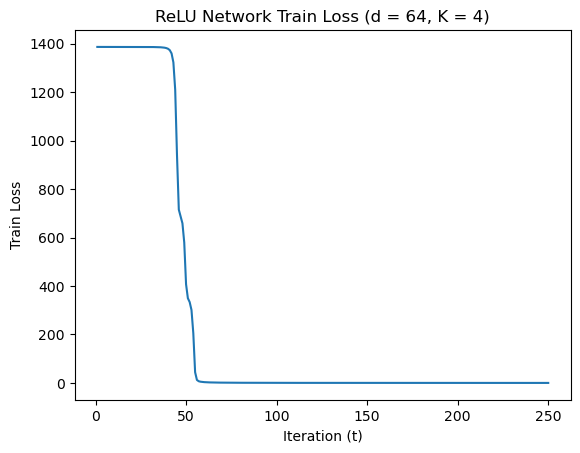

=== TRIAL 7 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:37:53,857 - INFO - Finish Epoch 1
2026-01-02 19:37:53,858 - INFO - Train loss: 1386.2991619110107, train accuracy: 20.7
2026-01-02 19:37:53,875 - INFO - Val loss: 1386.2934703826904, val accuracy: 24.7
2026-01-02 19:37:53,914 - INFO - Finish Epoch 2
2026-01-02 19:37:53,915 - INFO - Train loss: 1386.2958526611328, train accuracy: 22.6
2026-01-02 19:37:53,933 - INFO - Val loss: 1386.2911930084229, val accuracy: 26.4
  1%|          | 2/250 [00:00<00:14, 17.34it/s]2026-01-02 19:37:53,973 - INFO - Finish Epoch 3
2026-01-02 19:37:53,974 - INFO - Train loss: 1386.2935152053833, train accuracy: 24.4
2026-01-02 19:37:53,991 - INFO - Val loss: 1386.2888946533203, val accuracy: 27.4
2026-01-02 19:37:54,030 - INFO - Finish Epoch 4
2026-01-02 19:37:54,031 - INFO - Train loss: 1386.2912197113037, train accuracy: 25.5
2026-01-02 19:37:54,048 - INFO - Val loss: 1386.2866077423096, val accuracy: 29.8
  2%|▏         | 4/250 [00:00<00:14, 17.36it/s]202

 27%|██▋       | 68/250 [00:04<00:10, 17.27it/s]2026-01-02 19:37:57,889 - INFO - Finish Epoch 69
2026-01-02 19:37:57,890 - INFO - Train loss: 337.4251589179039, train accuracy: 100.0
2026-01-02 19:37:57,908 - INFO - Val loss: 335.0891886074096, val accuracy: 100.0
2026-01-02 19:37:57,946 - INFO - Finish Epoch 70
2026-01-02 19:37:57,948 - INFO - Train loss: 327.8836557455361, train accuracy: 100.0
2026-01-02 19:37:57,964 - INFO - Val loss: 322.30127475224435, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.28it/s]2026-01-02 19:37:58,004 - INFO - Finish Epoch 71
2026-01-02 19:37:58,005 - INFO - Train loss: 303.5404031686485, train accuracy: 100.0
2026-01-02 19:37:58,022 - INFO - Val loss: 287.5529478248209, val accuracy: 100.0
2026-01-02 19:37:58,060 - INFO - Finish Epoch 72
2026-01-02 19:37:58,061 - INFO - Train loss: 230.96867548301816, train accuracy: 100.0
2026-01-02 19:37:58,078 - INFO - Val loss: 182.88687547668815, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<00

 41%|████      | 102/250 [00:05<00:08, 17.35it/s]2026-01-02 19:37:59,848 - INFO - Finish Epoch 103
2026-01-02 19:37:59,849 - INFO - Train loss: 0.4841536642052233, train accuracy: 100.0
2026-01-02 19:37:59,866 - INFO - Val loss: 0.47520937537774444, val accuracy: 100.0
2026-01-02 19:37:59,905 - INFO - Finish Epoch 104
2026-01-02 19:37:59,906 - INFO - Train loss: 0.46996725210919976, train accuracy: 100.0
2026-01-02 19:37:59,923 - INFO - Val loss: 0.46148291043937206, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 17.38it/s]2026-01-02 19:37:59,964 - INFO - Finish Epoch 105
2026-01-02 19:37:59,965 - INFO - Train loss: 0.45656703785061836, train accuracy: 100.0
2026-01-02 19:37:59,982 - INFO - Val loss: 0.44850484654307365, val accuracy: 100.0
2026-01-02 19:38:00,021 - INFO - Finish Epoch 106
2026-01-02 19:38:00,022 - INFO - Train loss: 0.4438766702078283, train accuracy: 100.0
2026-01-02 19:38:00,039 - INFO - Val loss: 0.4362038145773113, val accuracy: 100.0
 42%|████▏     | 

2026-01-02 19:38:01,760 - INFO - Val loss: 0.23591132159344852, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.43it/s]2026-01-02 19:38:01,800 - INFO - Finish Epoch 137
2026-01-02 19:38:01,801 - INFO - Train loss: 0.234695975901559, train accuracy: 100.0
2026-01-02 19:38:01,818 - INFO - Val loss: 0.232248020125553, val accuracy: 100.0
2026-01-02 19:38:01,857 - INFO - Finish Epoch 138
2026-01-02 19:38:01,858 - INFO - Train loss: 0.2310732831247151, train accuracy: 100.0
2026-01-02 19:38:01,875 - INFO - Val loss: 0.22869831672869623, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:08<00:06, 17.45it/s]2026-01-02 19:38:01,914 - INFO - Finish Epoch 139
2026-01-02 19:38:01,916 - INFO - Train loss: 0.22755835833959281, train accuracy: 100.0
2026-01-02 19:38:01,932 - INFO - Val loss: 0.2252500681206584, val accuracy: 100.0
2026-01-02 19:38:01,971 - INFO - Finish Epoch 140
2026-01-02 19:38:01,972 - INFO - Train loss: 0.2241438147611916, train accuracy: 100.0
2026-01-02 19:38:01,9

2026-01-02 19:38:03,690 - INFO - Finish Epoch 170
2026-01-02 19:38:03,691 - INFO - Train loss: 0.1534478416433558, train accuracy: 100.0
2026-01-02 19:38:03,708 - INFO - Val loss: 0.15231766435317695, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.42it/s]2026-01-02 19:38:03,748 - INFO - Finish Epoch 171
2026-01-02 19:38:03,749 - INFO - Train loss: 0.15181661816313863, train accuracy: 100.0
2026-01-02 19:38:03,766 - INFO - Val loss: 0.15071407821960747, val accuracy: 100.0
2026-01-02 19:38:03,804 - INFO - Finish Epoch 172
2026-01-02 19:38:03,806 - INFO - Train loss: 0.1502185114659369, train accuracy: 100.0
2026-01-02 19:38:03,823 - INFO - Val loss: 0.1491369348950684, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:10<00:04, 17.44it/s]2026-01-02 19:38:03,862 - INFO - Finish Epoch 173
2026-01-02 19:38:03,863 - INFO - Train loss: 0.14865518757142127, train accuracy: 100.0
2026-01-02 19:38:03,880 - INFO - Val loss: 0.147596244700253, val accuracy: 100.0
2026-01-02 19:38:03

2026-01-02 19:38:05,605 - INFO - Val loss: 0.11214538180502132, val accuracy: 100.0
2026-01-02 19:38:05,644 - INFO - Finish Epoch 204
2026-01-02 19:38:05,645 - INFO - Train loss: 0.11187189200427383, train accuracy: 100.0
2026-01-02 19:38:05,662 - INFO - Val loss: 0.11124166491208598, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.35it/s]2026-01-02 19:38:05,702 - INFO - Finish Epoch 205
2026-01-02 19:38:05,703 - INFO - Train loss: 0.1109704370610416, train accuracy: 100.0
2026-01-02 19:38:05,721 - INFO - Val loss: 0.1103508158121258, val accuracy: 100.0
2026-01-02 19:38:05,760 - INFO - Finish Epoch 206
2026-01-02 19:38:05,761 - INFO - Train loss: 0.11008399300044402, train accuracy: 100.0
2026-01-02 19:38:05,778 - INFO - Val loss: 0.10947342618601397, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.31it/s]2026-01-02 19:38:05,819 - INFO - Finish Epoch 207
2026-01-02 19:38:05,820 - INFO - Train loss: 0.10921005927957594, train accuracy: 100.0
2026-01-02 19:38

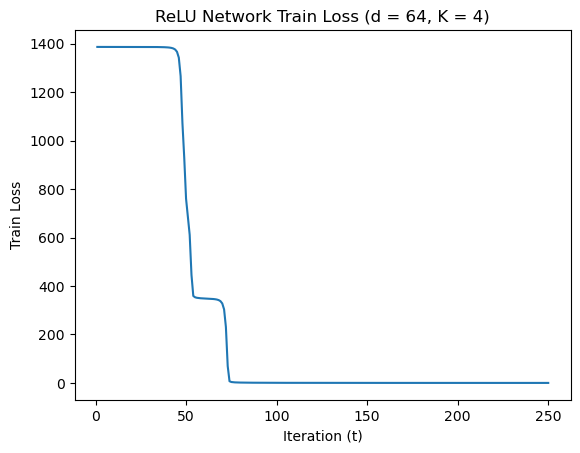

=== TRIAL 8 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:38:08,631 - INFO - Finish Epoch 1
2026-01-02 19:38:08,632 - INFO - Train loss: 1386.2974014282227, train accuracy: 22.9
2026-01-02 19:38:08,650 - INFO - Val loss: 1386.2919511795044, val accuracy: 26.2
2026-01-02 19:38:08,689 - INFO - Finish Epoch 2
2026-01-02 19:38:08,690 - INFO - Train loss: 1386.2944049835205, train accuracy: 24.3
2026-01-02 19:38:08,707 - INFO - Val loss: 1386.2899436950684, val accuracy: 28.3
  1%|          | 2/250 [00:00<00:14, 17.43it/s]2026-01-02 19:38:08,747 - INFO - Finish Epoch 3
2026-01-02 19:38:08,748 - INFO - Train loss: 1386.2923221588135, train accuracy: 26.3
2026-01-02 19:38:08,766 - INFO - Val loss: 1386.2879543304443, val accuracy: 30.4
2026-01-02 19:38:08,805 - INFO - Finish Epoch 4
2026-01-02 19:38:08,806 - INFO - Train loss: 1386.2903051376343, train accuracy: 28.8
2026-01-02 19:38:08,823 - INFO - Val loss: 1386.2859077453613, val accuracy: 31.9
  2%|▏         | 4/250 [00:00<00:14, 17.31it/s]202

 27%|██▋       | 68/250 [00:03<00:10, 17.33it/s]2026-01-02 19:38:12,541 - INFO - Finish Epoch 69
2026-01-02 19:38:12,542 - INFO - Train loss: 1.830463433638215, train accuracy: 100.0
2026-01-02 19:38:12,559 - INFO - Val loss: 1.7140258690342307, val accuracy: 100.0
2026-01-02 19:38:12,598 - INFO - Finish Epoch 70
2026-01-02 19:38:12,599 - INFO - Train loss: 1.6873392830602825, train accuracy: 100.0
2026-01-02 19:38:12,616 - INFO - Val loss: 1.5874264622107148, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.36it/s]2026-01-02 19:38:12,656 - INFO - Finish Epoch 71
2026-01-02 19:38:12,657 - INFO - Train loss: 1.5641353745013475, train accuracy: 100.0
2026-01-02 19:38:12,674 - INFO - Val loss: 1.4774852665141225, val accuracy: 100.0
2026-01-02 19:38:12,712 - INFO - Finish Epoch 72
2026-01-02 19:38:12,713 - INFO - Train loss: 1.4569828920066357, train accuracy: 100.0
2026-01-02 19:38:12,731 - INFO - Val loss: 1.381152207031846, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04

 41%|████      | 102/250 [00:05<00:08, 16.77it/s]2026-01-02 19:38:14,550 - INFO - Finish Epoch 103
2026-01-02 19:38:14,552 - INFO - Train loss: 0.43917427118867636, train accuracy: 100.0
2026-01-02 19:38:14,569 - INFO - Val loss: 0.4311454379931092, val accuracy: 100.0
2026-01-02 19:38:14,607 - INFO - Finish Epoch 104
2026-01-02 19:38:14,608 - INFO - Train loss: 0.4288716474547982, train accuracy: 100.0
2026-01-02 19:38:14,625 - INFO - Val loss: 0.4211891181766987, val accuracy: 100.0
 42%|████▏     | 104/250 [00:06<00:08, 16.98it/s]2026-01-02 19:38:14,665 - INFO - Finish Epoch 105
2026-01-02 19:38:14,666 - INFO - Train loss: 0.41900792764499784, train accuracy: 100.0
2026-01-02 19:38:14,683 - INFO - Val loss: 0.411650882801041, val accuracy: 100.0
2026-01-02 19:38:14,721 - INFO - Finish Epoch 106
2026-01-02 19:38:14,722 - INFO - Train loss: 0.40955945826135576, train accuracy: 100.0
2026-01-02 19:38:14,739 - INFO - Val loss: 0.402511281426996, val accuracy: 100.0
 42%|████▏     | 106/

2026-01-02 19:38:16,450 - INFO - Val loss: 0.23775247146841139, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.62it/s]2026-01-02 19:38:16,489 - INFO - Finish Epoch 137
2026-01-02 19:38:16,490 - INFO - Train loss: 0.23698320018593222, train accuracy: 100.0
2026-01-02 19:38:16,507 - INFO - Val loss: 0.2344473972916603, val accuracy: 100.0
2026-01-02 19:38:16,545 - INFO - Finish Epoch 138
2026-01-02 19:38:16,546 - INFO - Train loss: 0.23369920649565756, train accuracy: 100.0
2026-01-02 19:38:16,563 - INFO - Val loss: 0.2312265057116747, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.64it/s]2026-01-02 19:38:16,602 - INFO - Finish Epoch 139
2026-01-02 19:38:16,604 - INFO - Train loss: 0.2304933222476393, train accuracy: 100.0
2026-01-02 19:38:16,621 - INFO - Val loss: 0.22808682266622782, val accuracy: 100.0
2026-01-02 19:38:16,659 - INFO - Finish Epoch 140
2026-01-02 19:38:16,660 - INFO - Train loss: 0.22737258509732783, train accuracy: 100.0
2026-01-02 19:38:

2026-01-02 19:38:18,383 - INFO - Finish Epoch 170
2026-01-02 19:38:18,384 - INFO - Train loss: 0.1605113020632416, train accuracy: 100.0
2026-01-02 19:38:18,402 - INFO - Val loss: 0.15928413713118061, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.36it/s]2026-01-02 19:38:18,442 - INFO - Finish Epoch 171
2026-01-02 19:38:18,443 - INFO - Train loss: 0.158916772226803, train accuracy: 100.0
2026-01-02 19:38:18,460 - INFO - Val loss: 0.15771557111293077, val accuracy: 100.0
2026-01-02 19:38:18,500 - INFO - Finish Epoch 172
2026-01-02 19:38:18,501 - INFO - Train loss: 0.15735357091762125, train accuracy: 100.0
2026-01-02 19:38:18,518 - INFO - Val loss: 0.15617393533466384, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.31it/s]2026-01-02 19:38:18,558 - INFO - Finish Epoch 173
2026-01-02 19:38:18,559 - INFO - Train loss: 0.15581836237106472, train accuracy: 100.0
2026-01-02 19:38:18,576 - INFO - Val loss: 0.15465992607641965, val accuracy: 100.0
2026-01-02 19:38:

2026-01-02 19:38:20,292 - INFO - Val loss: 0.11932199611328542, val accuracy: 100.0
2026-01-02 19:38:20,331 - INFO - Finish Epoch 204
2026-01-02 19:38:20,332 - INFO - Train loss: 0.1191073686350137, train accuracy: 100.0
2026-01-02 19:38:20,349 - INFO - Val loss: 0.11840588430641219, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.50it/s]2026-01-02 19:38:20,388 - INFO - Finish Epoch 205
2026-01-02 19:38:20,389 - INFO - Train loss: 0.11819137935526669, train accuracy: 100.0
2026-01-02 19:38:20,406 - INFO - Val loss: 0.11750014056451619, val accuracy: 100.0
2026-01-02 19:38:20,445 - INFO - Finish Epoch 206
2026-01-02 19:38:20,446 - INFO - Train loss: 0.11728968407260254, train accuracy: 100.0
2026-01-02 19:38:20,463 - INFO - Val loss: 0.11660809663590044, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.51it/s]2026-01-02 19:38:20,502 - INFO - Finish Epoch 207
2026-01-02 19:38:20,503 - INFO - Train loss: 0.11640240752603859, train accuracy: 100.0
2026-01-02 19:3

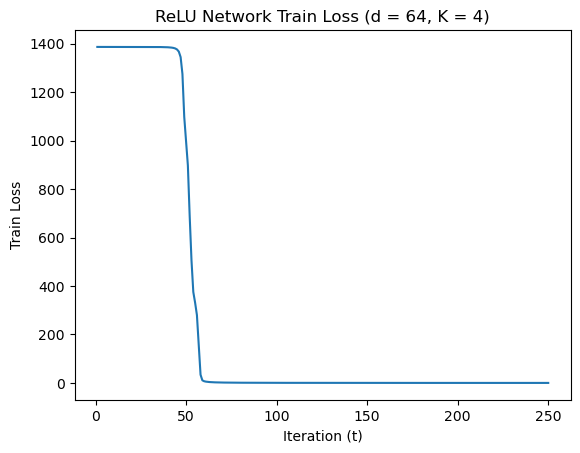

=== TRIAL 9 ===
Initializing weights using orthogonal method with scale 0.1


  0%|          | 0/250 [00:00<?, ?it/s]2026-01-02 19:38:23,303 - INFO - Finish Epoch 1
2026-01-02 19:38:23,305 - INFO - Train loss: 1386.2986631393433, train accuracy: 26.8
2026-01-02 19:38:23,322 - INFO - Val loss: 1386.292685508728, val accuracy: 28.8
2026-01-02 19:38:23,360 - INFO - Finish Epoch 2
2026-01-02 19:38:23,361 - INFO - Train loss: 1386.2952432632446, train accuracy: 28.4
2026-01-02 19:38:23,378 - INFO - Val loss: 1386.290397644043, val accuracy: 29.7
  1%|          | 2/250 [00:00<00:14, 17.62it/s]2026-01-02 19:38:23,418 - INFO - Finish Epoch 3
2026-01-02 19:38:23,419 - INFO - Train loss: 1386.2928924560547, train accuracy: 29.1
2026-01-02 19:38:23,436 - INFO - Val loss: 1386.288073539734, val accuracy: 30.4
2026-01-02 19:38:23,474 - INFO - Finish Epoch 4
2026-01-02 19:38:23,475 - INFO - Train loss: 1386.2905750274658, train accuracy: 30.0
2026-01-02 19:38:23,492 - INFO - Val loss: 1386.2857189178467, val accuracy: 31.6
  2%|▏         | 4/250 [00:00<00:13, 17.62it/s]2026-0

 27%|██▋       | 68/250 [00:03<00:10, 17.50it/s]2026-01-02 19:38:27,223 - INFO - Finish Epoch 69
2026-01-02 19:38:27,224 - INFO - Train loss: 1.8110991730354726, train accuracy: 100.0
2026-01-02 19:38:27,241 - INFO - Val loss: 1.6718722279183567, val accuracy: 100.0
2026-01-02 19:38:27,279 - INFO - Finish Epoch 70
2026-01-02 19:38:27,280 - INFO - Train loss: 1.6413390031084418, train accuracy: 100.0
2026-01-02 19:38:27,297 - INFO - Val loss: 1.5257832622155547, val accuracy: 100.0
 28%|██▊       | 70/250 [00:04<00:10, 17.51it/s]2026-01-02 19:38:27,337 - INFO - Finish Epoch 71
2026-01-02 19:38:27,338 - INFO - Train loss: 1.4997651735320687, train accuracy: 100.0
2026-01-02 19:38:27,355 - INFO - Val loss: 1.4024207638576627, val accuracy: 100.0
2026-01-02 19:38:27,393 - INFO - Finish Epoch 72
2026-01-02 19:38:27,394 - INFO - Train loss: 1.379978721961379, train accuracy: 100.0
2026-01-02 19:38:27,411 - INFO - Val loss: 1.29688470531255, val accuracy: 100.0
 29%|██▉       | 72/250 [00:04<

 41%|████      | 102/250 [00:05<00:08, 17.41it/s]2026-01-02 19:38:29,171 - INFO - Finish Epoch 103
2026-01-02 19:38:29,172 - INFO - Train loss: 0.37804543669335544, train accuracy: 100.0
2026-01-02 19:38:29,189 - INFO - Val loss: 0.3709871373139322, val accuracy: 100.0
2026-01-02 19:38:29,227 - INFO - Finish Epoch 104
2026-01-02 19:38:29,229 - INFO - Train loss: 0.3689670122694224, train accuracy: 100.0
2026-01-02 19:38:29,246 - INFO - Val loss: 0.36222837725654244, val accuracy: 100.0
 42%|████▏     | 104/250 [00:05<00:08, 17.43it/s]2026-01-02 19:38:29,286 - INFO - Finish Epoch 105
2026-01-02 19:38:29,287 - INFO - Train loss: 0.3602937301620841, train accuracy: 100.0
2026-01-02 19:38:29,304 - INFO - Val loss: 0.3538549079094082, val accuracy: 100.0
2026-01-02 19:38:29,343 - INFO - Finish Epoch 106
2026-01-02 19:38:29,344 - INFO - Train loss: 0.3520006072940305, train accuracy: 100.0
2026-01-02 19:38:29,361 - INFO - Val loss: 0.34584437240846455, val accuracy: 100.0
 42%|████▏     | 10

2026-01-02 19:38:31,090 - INFO - Val loss: 0.2033685017377138, val accuracy: 100.0
 54%|█████▍    | 136/250 [00:07<00:06, 17.36it/s]2026-01-02 19:38:31,130 - INFO - Finish Epoch 137
2026-01-02 19:38:31,131 - INFO - Train loss: 0.2027003288967535, train accuracy: 100.0
2026-01-02 19:38:31,148 - INFO - Val loss: 0.20054288464598358, val accuracy: 100.0
2026-01-02 19:38:31,186 - INFO - Finish Epoch 138
2026-01-02 19:38:31,187 - INFO - Train loss: 0.19989448878914118, train accuracy: 100.0
2026-01-02 19:38:31,204 - INFO - Val loss: 0.19778812502045184, val accuracy: 100.0
 55%|█████▌    | 138/250 [00:07<00:06, 17.40it/s]2026-01-02 19:38:31,243 - INFO - Finish Epoch 139
2026-01-02 19:38:31,244 - INFO - Train loss: 0.19715652405284345, train accuracy: 100.0
2026-01-02 19:38:31,261 - INFO - Val loss: 0.19510671531315893, val accuracy: 100.0
2026-01-02 19:38:31,299 - INFO - Finish Epoch 140
2026-01-02 19:38:31,300 - INFO - Train loss: 0.19448797567747533, train accuracy: 100.0
2026-01-02 19:38

2026-01-02 19:38:33,011 - INFO - Finish Epoch 170
2026-01-02 19:38:33,012 - INFO - Train loss: 0.13754064199747518, train accuracy: 100.0
2026-01-02 19:38:33,029 - INFO - Val loss: 0.1365033684996888, val accuracy: 100.0
 68%|██████▊   | 170/250 [00:09<00:04, 17.52it/s]2026-01-02 19:38:33,068 - INFO - Finish Epoch 171
2026-01-02 19:38:33,069 - INFO - Train loss: 0.13618495524860919, train accuracy: 100.0
2026-01-02 19:38:33,086 - INFO - Val loss: 0.13516900513786823, val accuracy: 100.0
2026-01-02 19:38:33,125 - INFO - Finish Epoch 172
2026-01-02 19:38:33,126 - INFO - Train loss: 0.13485726376529783, train accuracy: 100.0
2026-01-02 19:38:33,143 - INFO - Val loss: 0.13385941786691546, val accuracy: 100.0
 69%|██████▉   | 172/250 [00:09<00:04, 17.52it/s]2026-01-02 19:38:33,182 - INFO - Finish Epoch 173
2026-01-02 19:38:33,183 - INFO - Train loss: 0.1335549473296851, train accuracy: 100.0
2026-01-02 19:38:33,200 - INFO - Val loss: 0.13257282302947715, val accuracy: 100.0
2026-01-02 19:38

2026-01-02 19:38:34,900 - INFO - Train loss: 0.1031663766480051, train accuracy: 100.0
2026-01-02 19:38:34,917 - INFO - Val loss: 0.1025655745761469, val accuracy: 100.0
2026-01-02 19:38:34,955 - INFO - Finish Epoch 204
2026-01-02 19:38:34,957 - INFO - Train loss: 0.10238037398084998, train accuracy: 100.0
2026-01-02 19:38:34,974 - INFO - Val loss: 0.10178719402756542, val accuracy: 100.0
 82%|████████▏ | 204/250 [00:11<00:02, 17.45it/s]2026-01-02 19:38:35,013 - INFO - Finish Epoch 205
2026-01-02 19:38:35,014 - INFO - Train loss: 0.10160544863902032, train accuracy: 100.0
2026-01-02 19:38:35,032 - INFO - Val loss: 0.10102299379650503, val accuracy: 100.0
2026-01-02 19:38:35,070 - INFO - Finish Epoch 206
2026-01-02 19:38:35,071 - INFO - Train loss: 0.10083970107370988, train accuracy: 100.0
2026-01-02 19:38:35,088 - INFO - Val loss: 0.1002630788134411, val accuracy: 100.0
 82%|████████▏ | 206/250 [00:11<00:02, 17.46it/s]2026-01-02 19:38:35,128 - INFO - Finish Epoch 207
2026-01-02 19:38:

 94%|█████████▍| 236/250 [00:13<00:00, 17.34it/s]2026-01-02 19:38:36,849 - INFO - Finish Epoch 237
2026-01-02 19:38:36,851 - INFO - Train loss: 0.08157908439170569, train accuracy: 100.0
2026-01-02 19:38:36,868 - INFO - Val loss: 0.08119309484027326, val accuracy: 100.0
2026-01-02 19:38:36,905 - INFO - Finish Epoch 238
2026-01-02 19:38:36,907 - INFO - Train loss: 0.08107271994231269, train accuracy: 100.0
2026-01-02 19:38:36,923 - INFO - Val loss: 0.08069268596591428, val accuracy: 100.0
 95%|█████████▌| 238/250 [00:13<00:00, 17.44it/s]2026-01-02 19:38:36,962 - INFO - Finish Epoch 239
2026-01-02 19:38:36,964 - INFO - Train loss: 0.08057552913669497, train accuracy: 100.0
2026-01-02 19:38:36,980 - INFO - Val loss: 0.08019442419754341, val accuracy: 100.0
2026-01-02 19:38:37,019 - INFO - Finish Epoch 240
2026-01-02 19:38:37,020 - INFO - Train loss: 0.08007738628657535, train accuracy: 100.0
2026-01-02 19:38:37,037 - INFO - Val loss: 0.07970831770217046, val accuracy: 100.0
 96%|█████████

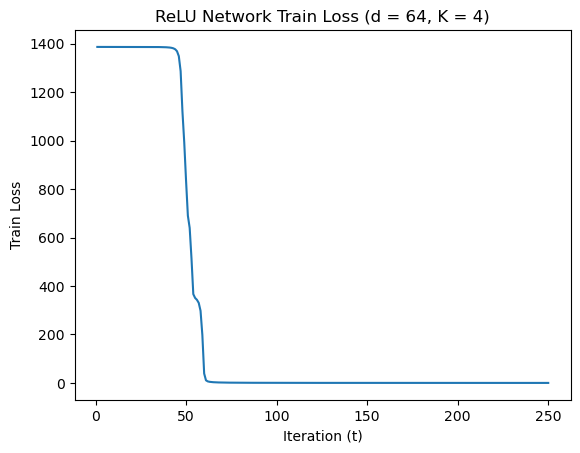

In [11]:
trials = 10

weight_decomp_norms = np.zeros((trials, len(act_fn_strs), epochs, L - 1, 4))
weight_decomp_dists = np.zeros((trials, len(act_fn_strs), epochs - 1, L - 1, 4))
train_losses = np.zeros((trials, len(act_fn_strs), epochs))

for (k, act_fn_str) in enumerate(act_fn_strs):
    lr = lrs[k]
    print("===== ACTIVATION FUNCTION: ", act_fn_str, " =====")
    for i in range(trials):
        # Create data
        train_loader, val_loader, grad_loader, X, Y = get_data(d, K, N_k, nu, whiten_, normalize_, batch_size=batch_size)
        
        print("=== TRIAL " + str(i) + " ===")
        # Train model
        init_grads, all_weights, train_losses_trial = train_model(L, d, m, K, act_fn_str, 
                                                                 train_loader, 
                                                                 grad_loader, 
                                                                 val_loader, 
                                                                 epochs, 
                                                                 lr, 
                                                                 freq, 
                                                                 loss_fn, 
                                                                 optimizer_type=optimizer_type,
                                                                 freeze_last_layer=freeze_last_layer,
                                                                 diff_init_last_layer=diff_init_last_layer,
                                                                 residual=residual,
                                                                 batchnorm=batchnorm,
                                                                 init_method=init_method,
                                                                 init_scale=init_scale)


            
        # Plot train loss
        plot_train_losses(train_losses_trial, act_fn_str, d, d, K, None, savefig=False)
        
        train_losses[i, k, :] = train_losses_trial


        # Calculate norms of decompositions
        trial_decomp_norms, trial_decomp_dists = weight_decomp_norms_dists(all_weights,
                                                                           init_grads, 
                                                                           K, 
                                                                           init_scale)
        
        weight_decomp_norms[i, k, ...] = trial_decomp_norms
        weight_decomp_dists[i, k, ...] = trial_decomp_dists
    
    
# Save results
save_fname = os.path.join(savefig_dir, 'all_acts_losses_decomp_dists')
save_fname += '_large_d.npz' if d > N else '_large_N.npz'

np.savez(save_fname, 
         train_losses=train_losses, 
         weight_decomp_norms=weight_decomp_norms, 
         weight_decomp_dists=weight_decomp_dists)

In [12]:
# load_fname = savefig_dir + '/all_acts_losses_decomp_dists'
# load_fname += '_large_d.npz' if d > N else '_large_N.npz'
# results = np.load(load_fname)

# weight_decomp_dists = results['weight_decomp_dists']

In [13]:
loss_str_map = {
    'mse_loss': 'Squared Error Loss',
    'ce_loss': 'Cross Entropy Loss'
}

In [14]:
def at_most_2_decimals(x, pos):
    return f"{x:.2f}".rstrip('0').rstrip('.')

def two_to_three_decimals(x, pos):
    s = f"{x:.3f}"          # round to 3 decimals
    integer, _, frac = s.partition('.')

    # ensure at least 2 decimals
    frac = frac.rstrip('0')
    if len(frac) < 2:
        frac = frac.ljust(2, '0')

    return integer + '.' + frac

formatter = FuncFormatter(at_most_2_decimals)

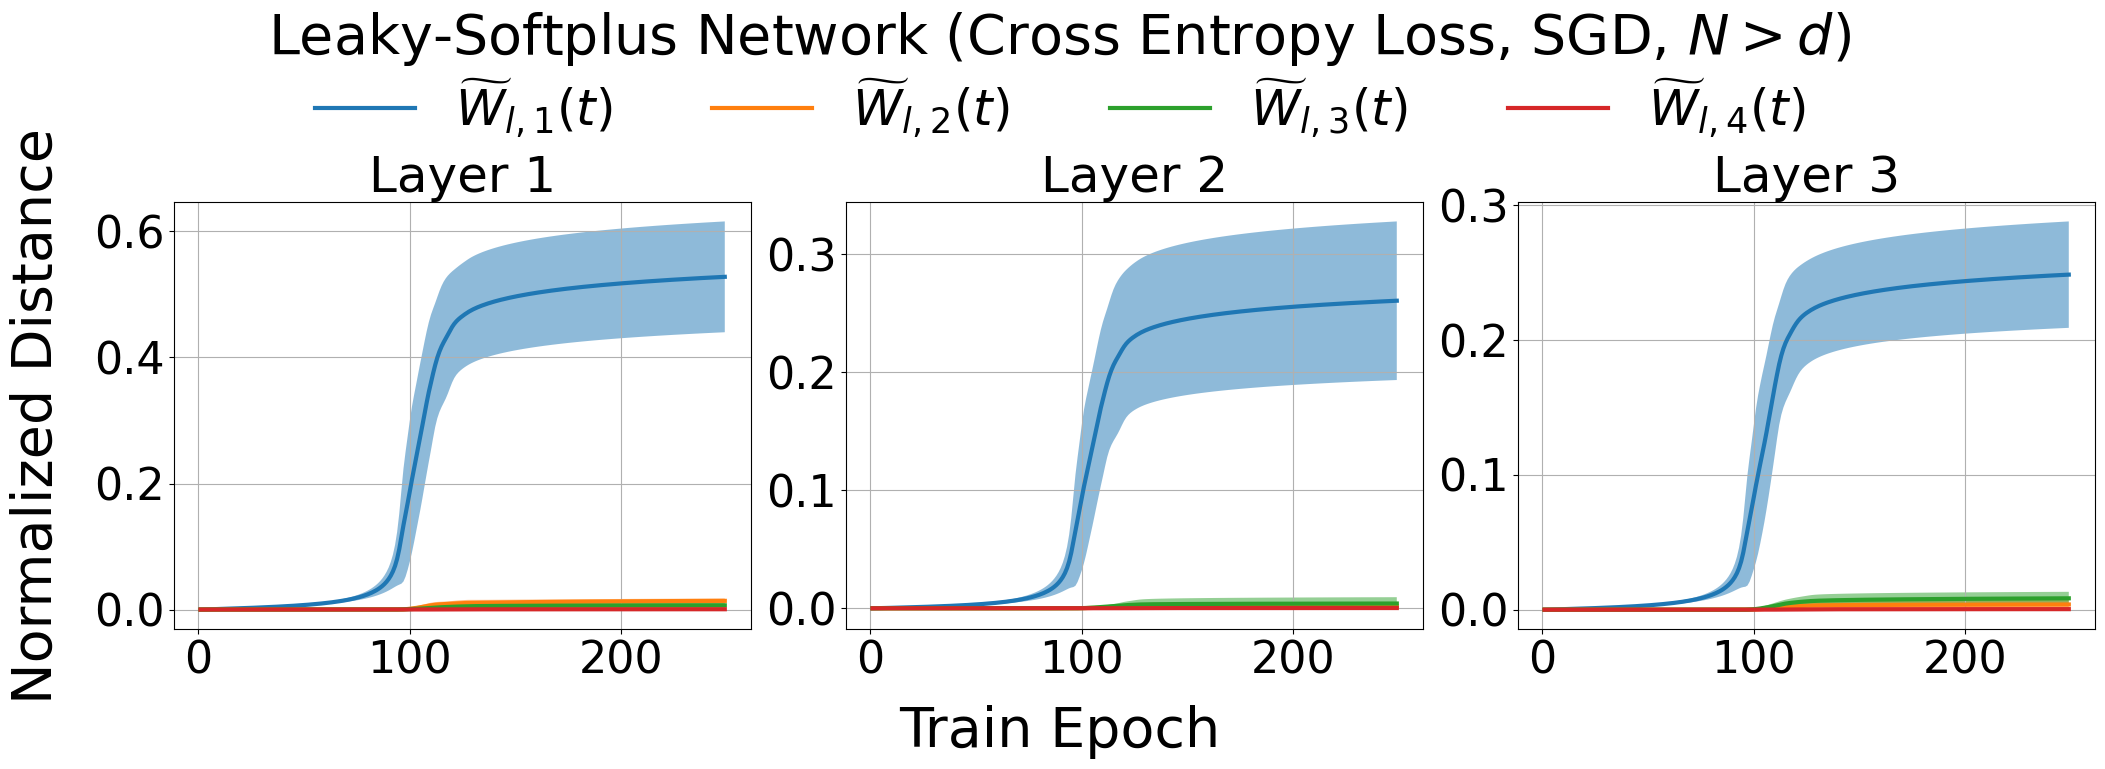

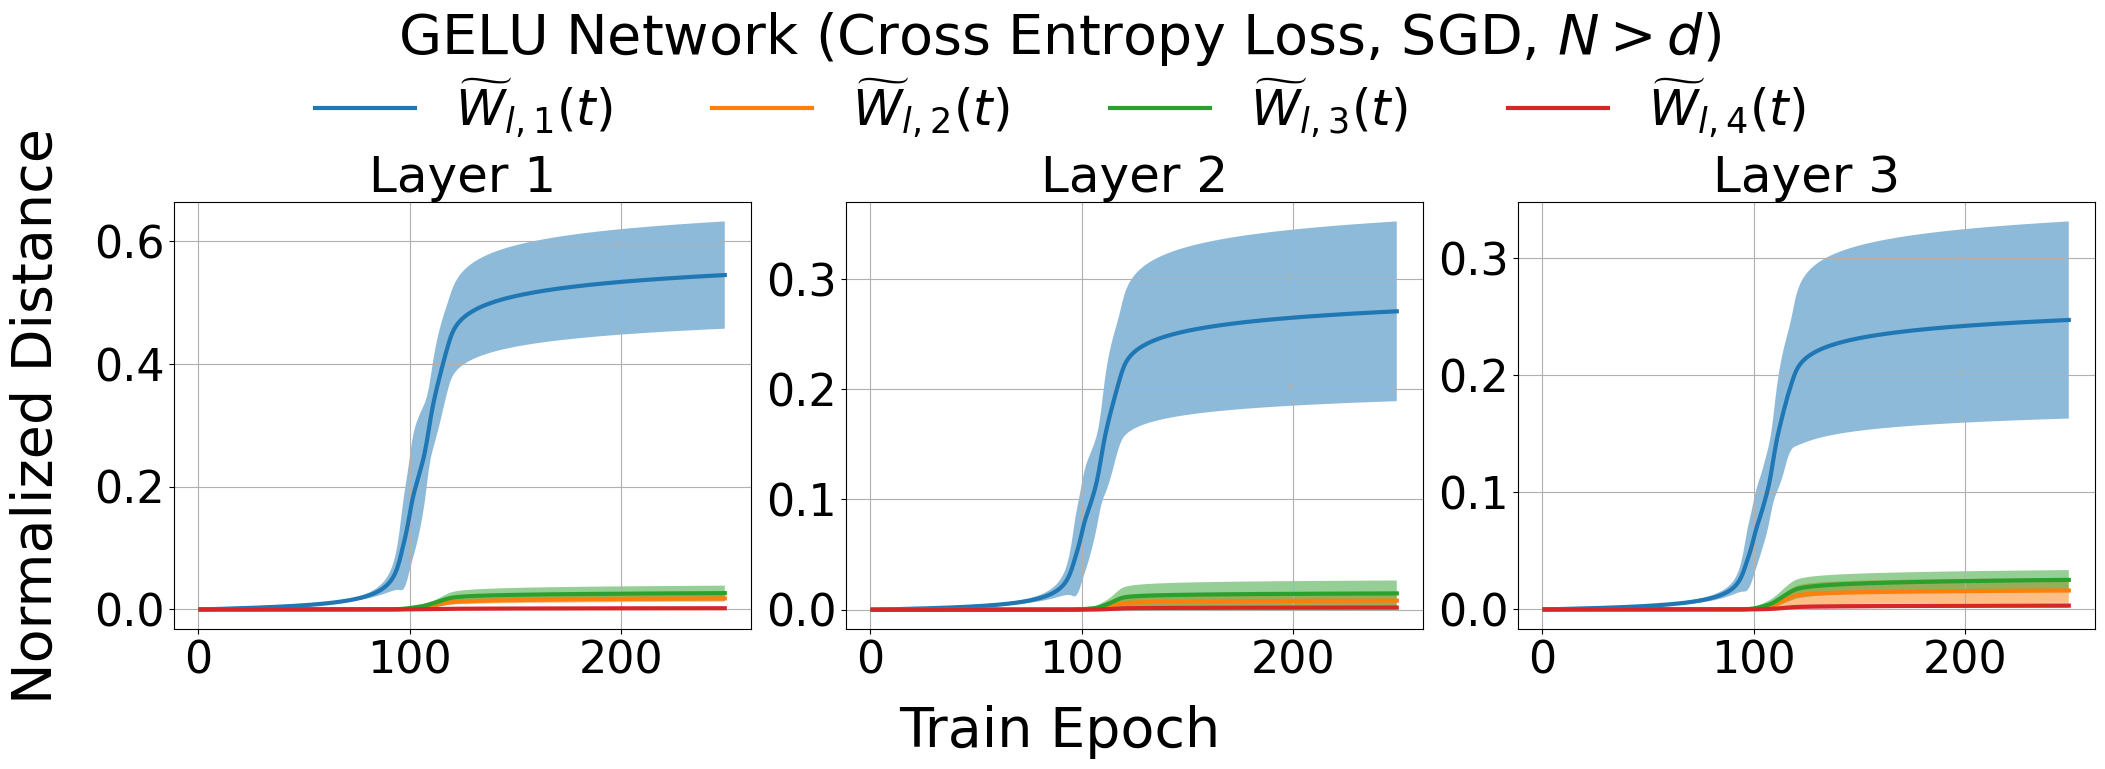

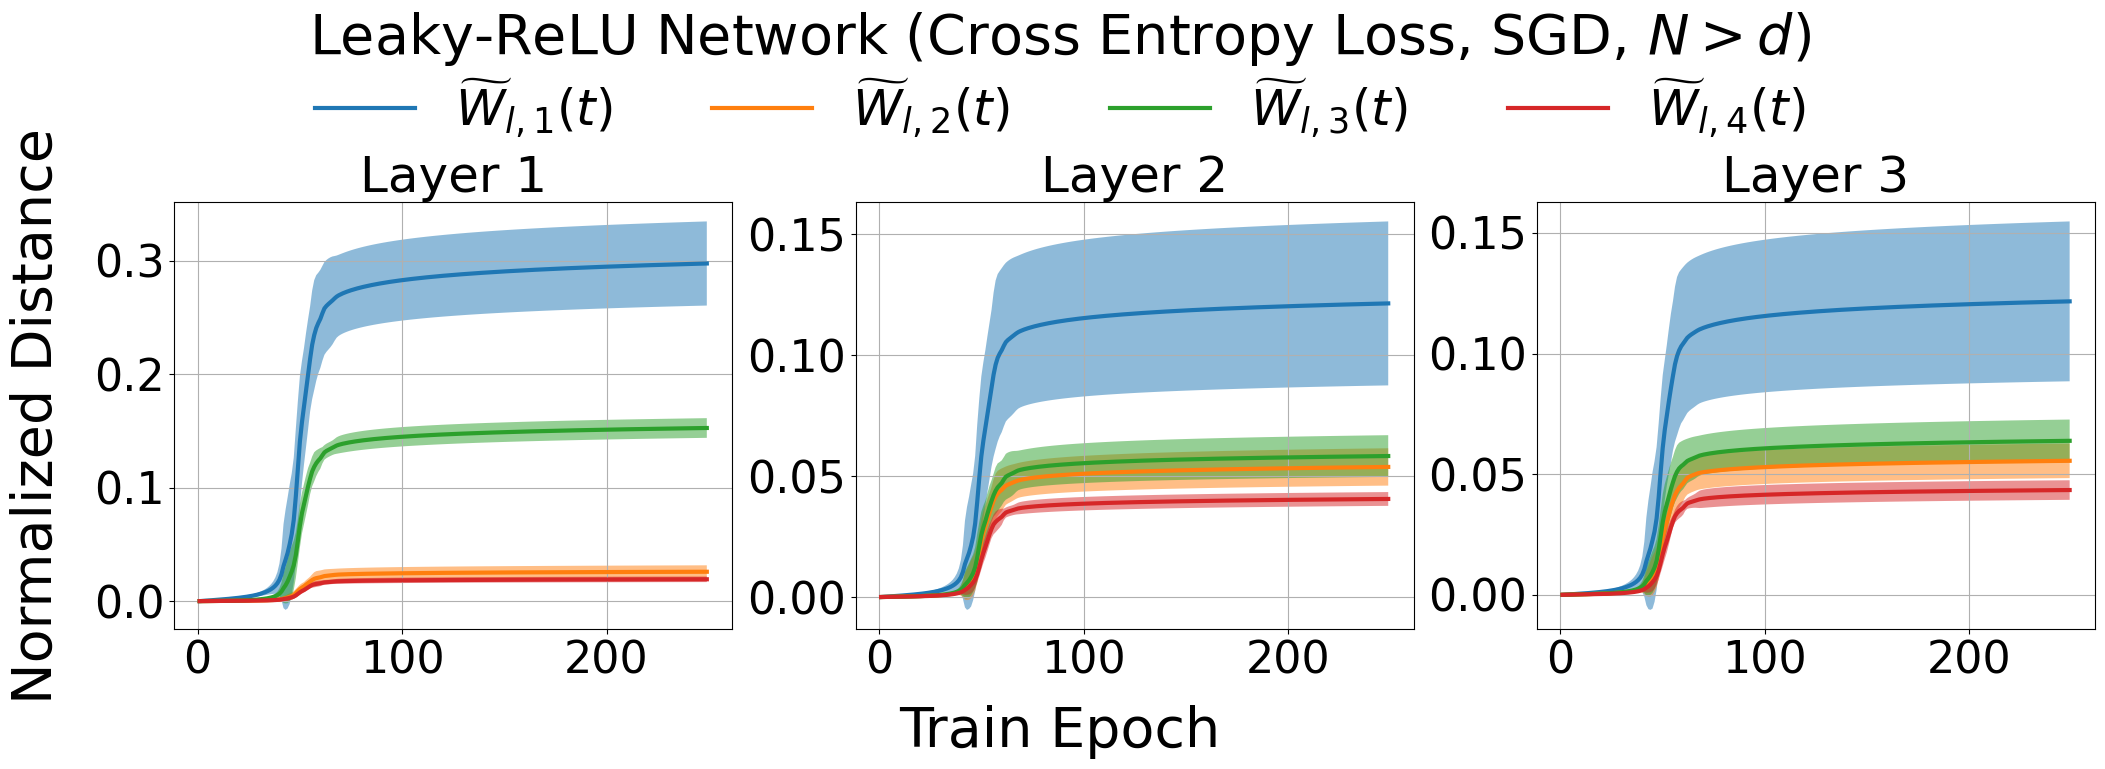

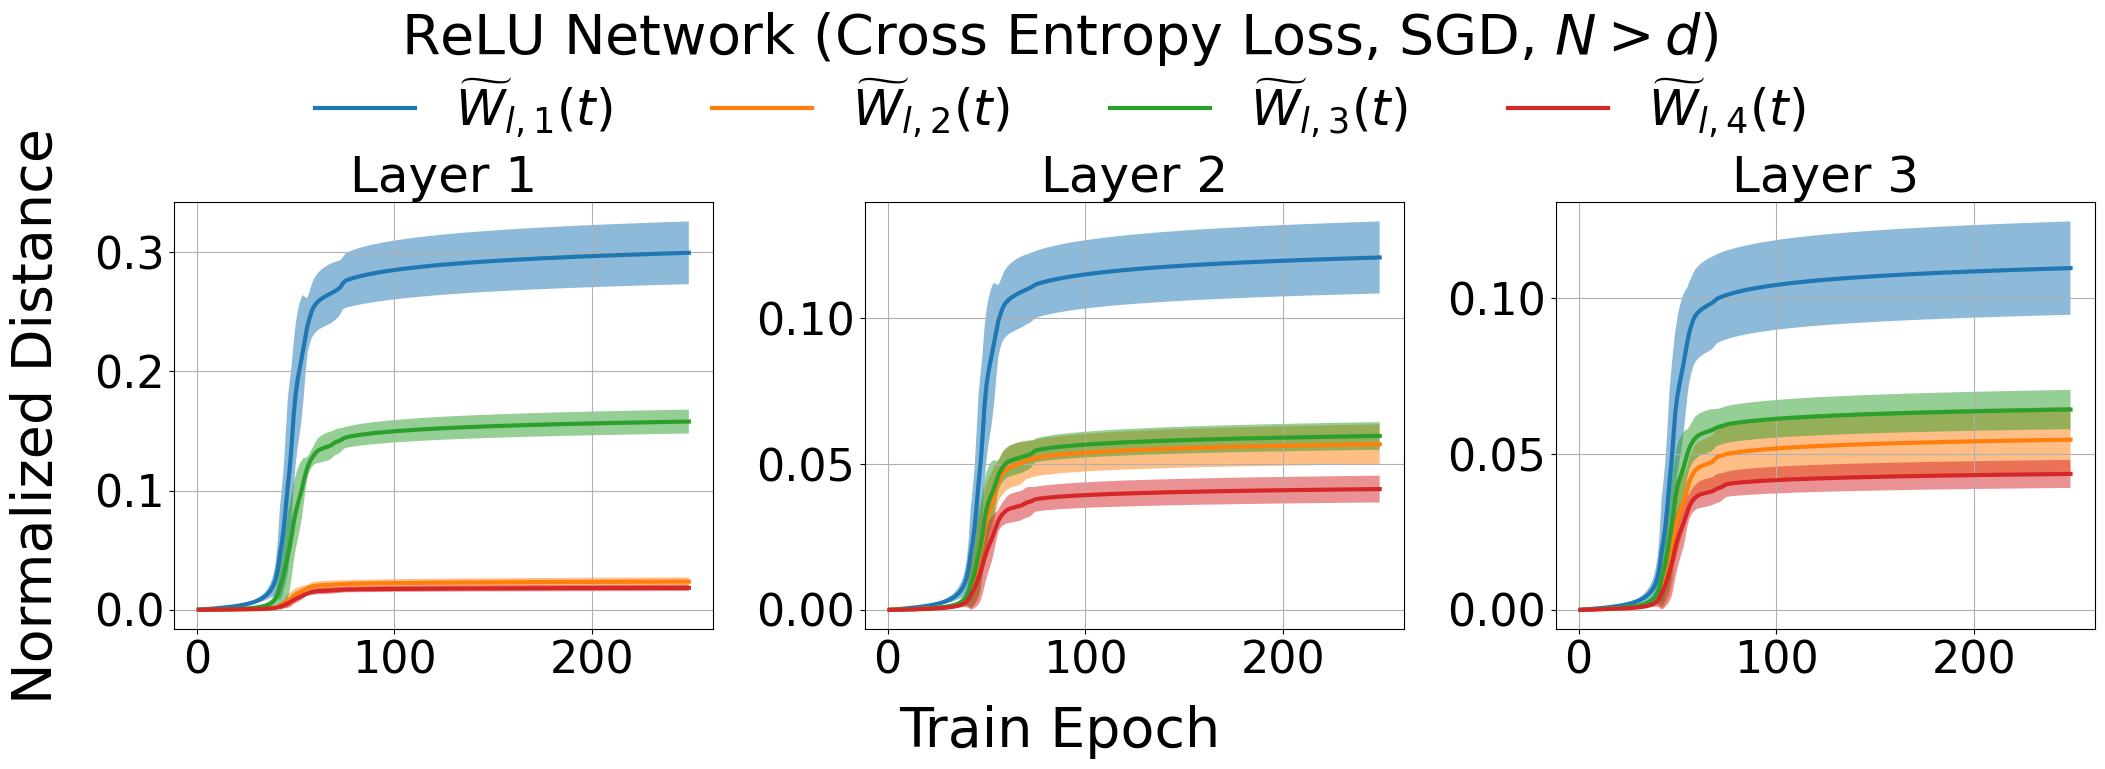

In [15]:
# Mean and stdev of weight decomposition norms across trials
mean_weight_decomp_dists = np.mean(weight_decomp_dists, axis=0)
std_weight_decomp_dists = np.std(weight_decomp_dists, axis=0) 

# mean_weight_decomp_norms = np.mean(weight_decomp_norms, axis=0)
# std_weight_decomp_norms = np.std(weight_decomp_norms, axis=0) 


# Plotting
x_range1 = np.arange(weight_decomp_dists.shape[2]) + 1
x_range2 = np.arange(0, epochs) 


for (k, act_fn_str) in enumerate(act_fn_strs):    
    # Create two figures
    fig1, ax1 = plt.subplots(nrows = 1, ncols = L - 1, figsize=(int(7*(L - 1)), 7))
    handles1, labels1 = [], [] 

    
    # Plot each layer
    for l in range(L - 1):
        for j in range(4):
            # Plot normalized distance from initialization
            plt_label = r'$\widetilde{W}_{l,' + str(j + 1) + r'}(t)$'
            ax1[l].plot(x_range1, 
                       mean_weight_decomp_dists[k, :, l, j], 
                       linewidth=3,
                       label=plt_label)
            
            ax1[l].fill_between(x_range1, 
                             mean_weight_decomp_dists[k, :, l, j] - std_weight_decomp_dists[k, :, l, j], 
                             mean_weight_decomp_dists[k, :, l, j] + std_weight_decomp_dists[k, :, l, j],
                             linewidth=3,
                             alpha=0.5)
            

        # Figure 1 visuals
        ax1[l].grid('on')
        ax1[l].tick_params(axis='x', labelsize=32)
        ax1[l].tick_params(axis='y', labelsize=32)
        #ax1[l].yaxis.set_major_formatter(formatter)
        ax1[l].set_title('Layer ' + str(l + 1), fontsize=36)
        #ax1[l].set_xticks(np.)


        for handle1, label1 in zip(*ax1[l].get_legend_handles_labels()):
            if label1 not in labels1:
                handles1.append(handle1)
                labels1.append(label1)
                
    
    
    # Show figure 1    
    if optimizer_type == 'SGD' and (not batch_size or batch_size == N):
        exp_info = act_fn_str + ' Network (' + loss_str_map[loss_fn] + ', Full Batch GD, '
    else:
        exp_info = act_fn_str + ' Network (' + loss_str_map[loss_fn] + ', ' + optimizer_type + ', '
    
    exp_info += r'$d > N$)' if d > N else r'$N > d$)'
        
    fig1.suptitle(exp_info, fontsize=40, y=1.08)
    fig1.supxlabel('Train Epoch', fontsize=40)
    fig1.supylabel('Normalized Distance', 
                  fontsize=40,
                 x = 0)

    fig1.legend(
        handles1,
        labels1,
        loc='upper center',
        bbox_to_anchor=(0.5, 1.05), 
        ncol=4,
        fontsize=36,
        frameon=False
    )


    fig1.tight_layout()    

    save_fname = act_fn_str + '_normalized_dist_from_init'
    save_fname = save_fname + '_large_d.pdf' if d > N else save_fname + '_large_N.pdf'
    plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')
    plt.show()
    plt.close()

In [16]:
# W1_end = weights[-1][0]

# svals = np.linalg.svd(W1_end, compute_uv=False)

# print(svals)